## Workflow Improvement Suggestions

Based on your current notebook, here are some suggestions to enhance your classification workflow, focusing on robustness, efficiency, and clarity.

### 1. Data Splitting and Cross-Validation Strategy

Your notebook uses `train_test_split` multiple times and also explores K-Fold and Repeated Stratified K-Fold. To ensure consistent and reliable model evaluation, it's crucial to establish a single, robust data splitting strategy early in your workflow.

**Suggestions:**

*   **Unified Train/Test Split:** For initial exploration and hyperparameter tuning, define your main train and test sets once. This prevents data leakage and ensures that all models are evaluated on the same 'unseen' data.
*   **Systematic Cross-Validation:** For more reliable performance estimation and hyperparameter tuning, consistently use cross-validation (e.g., `StratifiedKFold` or `RepeatedStratifiedKFold`). This provides a more stable estimate of model performance by averaging results over multiple train/validation splits.
*   **Nested Cross-Validation for Robust Hyperparameter Tuning:** You've already started exploring this. Nested CV (`GridSearchCV` or `RandomizedSearchCV` within an outer cross-validation loop) provides an unbiased estimate of the generalization error of the tuned model. This is especially important for complex models or when comparing different algorithms.

### 2. Feature Engineering and Selection

You have implemented various feature extraction methods (statistical, STFT, wavelet) and feature selection using Gini importance. This is an excellent foundation.

**Suggestions:**

*   **Automate Feature Extraction Integration:** Create a more streamlined function or pipeline that takes raw data and outputs the desired feature set (e.g., combining statistical, STFT, and wavelet features directly). This reduces redundancy and potential errors.
*   **Comparative Analysis of Feature Sets:** Systematically compare the performance of models trained on different feature sets (e.g., only statistical, only STFT, only wavelet, or various combinations). This can help identify the most informative features.
*   **Advanced Feature Selection:** Explore additional feature selection techniques like Recursive Feature Elimination (RFE) or different types of PCA/LDA (as you've also started using). Visualize the impact of reducing features on model performance.
*   **Denoising Integration:** Integrate the denoising step directly into your feature extraction pipeline, allowing you to easily compare models trained on raw vs. denoised features.

### 3. Model Training and Hyperparameter Optimization

You've experimented with a wide range of classical ML models and deep learning architectures, along with some GridSearchCV for RandomForest.

**Suggestions:**

*   **Systematic Hyperparameter Tuning Across All Models:** Extend `GridSearchCV` or `RandomizedSearchCV` to all your candidate models (SVM, XGBoost, MLP, etc.). This ensures that each model is evaluated at its optimal performance.
*   **Pipeline for Reproducibility:** Use `sklearn.pipeline.Pipeline` to chain preprocessing steps (scaling, feature selection/extraction) with classifiers. This makes your workflow cleaner, prevents data leakage, and ensures reproducibility.
*   **Learning Rate Schedulers (Deep Learning):** For your CNN and GRU models, utilize more advanced learning rate schedulers (`ReduceLROnPlateau`, `CosineDecay`, etc.) and potentially custom callbacks for better convergence and performance.
*   **Regularization in Deep Learning:** Continue to leverage `Dropout`, `BatchNormalization`, and `kernel_regularizer` effectively to prevent overfitting.

### 4. Evaluation and Interpretation

Your use of accuracy, precision, recall, F1-score, and confusion matrices is comprehensive.

**Suggestions:**

*   **Consolidate Evaluation Metrics:** Create a single function that outputs all relevant metrics (accuracy, precision, recall, F1, ROC-AUC) in a structured format (e.g., a DataFrame). This makes comparisons easier.
*   **Visualizations for Comparison:** Generate plots (e.g., bar charts) to easily compare the performance of different models across various metrics or feature sets.
*   **Error Analysis:** Beyond the confusion matrix, analyze specific misclassified samples. What characteristics do they share? This can provide insights for further feature engineering or model refinement.

### 5. Code Structure and Readability

Your notebook is quite long. Improving code structure can make it easier to manage and understand.

**Suggestions:**

*   **Modularize Functions:** Continue to break down complex operations into smaller, reusable functions (which you've done well in many places).
*   **Consistent Naming Conventions:** Ensure consistent naming for variables and functions.
*   **Comments and Docstrings:** Add more comments and docstrings to explain the purpose of functions, complex logic, and key parameters.
*   **Section Headers:** Use markdown headers (`#`, `##`, `###`) to clearly delineate sections of your notebook, as you've done, but perhaps refine them further for a clearer hierarchy.

## Set Dataset Directory ##

In [5]:
import os
import sys

# Deteksi apakah bisa berjalan di Google Colab
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    # 📌 GANTI DENGAN URL REPOSITORI GITHUB ANDA
    REPO_URL = "https://github.com/nellyoa-lecture/enose-coffee-defect-detection"
    REPO_NAME = "enose-coffee-defect-detection"

    # Clone repositori jika belum ada di session Colab
    if not os.path.exists(REPO_NAME):
        print(f"📥 Mengunduh repositori dari GitHub...")
        !git clone {REPO_URL}

    # Tentukan path absolut ke file dataset di dalam repositori yang di-clone
    # Struktur: /content/NAMA_REPOSITORI/dataset/dataset.csv
    DATASET_PATH = os.path.join("/content", REPO_NAME, "data", "Rasio_Gabungan_Semua_Grade.csv")
    print(f"✅ Berjalan di Colab. Path dataset: {DATASET_PATH}")

else:
    # Jika dijalankan di komputer lokal (karena posisi ipynb ada di folder 'src',
    # maka untuk ke folder 'dataset' kita perlu mundur satu folder bawaan/induk '..')
    DATASET_PATH = os.path.join("..", "data", "Rasio_Gabungan_Semua_Grade.csv")
    print(f"🏠 Berjalan di Lokal. Path dataset: {DATASET_PATH}")


📥 Mengunduh repositori dari GitHub...
Cloning into 'nellyoa-lecture'...
remote: Not Found
fatal: repository 'https://github.com/nellyoa-lecture/' not found
✅ Berjalan di Colab. Path dataset: /content/enose-coffee-defect-detection/data/Rasio_Gabungan_Semua_Grade.csv


## INSTALL DEPENDENCIES

In [2]:
!pip install pywavelets

## IMPORT LIBRARIES

In [3]:
import os
import pywt
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import random
import tensorflow as tf

from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [4]:
from scipy.stats import sem
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, make_scorer, precision_score, recall_score
from xgboost import XGBClassifier
import xgboost as xgb
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.feature_selection import SelectKBest, mutual_info_classif, f_classif
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score, StratifiedShuffleSplit, StratifiedKFold, RepeatedStratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

## IMPORT DATA

In [ ]:
df = pd.read_csv(DATASET_PATH)

display(df)

,Counter,Siklus,MQ2,MQ3,MQ4,MQ7,MQ8,MQ135,MQ137,TGS,Original_Sample,Grade
0,1001,1,0.865715,1.022924,1.010504,1.006786,1.000602,0.997857,1.003009,1.034609,Sample 1,1
1,1002,1,0.840325,0.992326,1.007607,1.003092,0.996449,0.995177,1.003009,0.996468,Sample 1,1
2,1003,1,0.812970,1.015111,1.007607,1.003092,1.000602,1.000551,1.000554,0.972537,Sample 1,1
3,1004,1,0.790368,1.011246,1.004726,1.010503,1.000602,1.003258,1.007953,1.034609,Sample 1,1
4,1005,1,0.762982,0.999814,1.004726,0.999421,1.000602,1.003258,1.003009,1.021581,Sample 1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
499995,20996,100,0.639680,0.790189,0.899343,0.869015,0.831095,0.841843,0.805430,0.458277,Sample 5,5
499996,20997,100,0.682751,0.776432,0.879090,0.876380,0.831095,0.839572,0.805430,0.444689,Sample 5,5
499997,20998,100,0.670257,0.788640,0.881576,0.876380,0.852443,0.832824,0.820702,0.444689,Sample 5,5
499998,20999,100,0.528205,0.771937,0.884076,0.872684,0.842834,0.830596,0.820702,0.458277,Sample 5,5


In [ ]:
# cleaning from unused string
df['Original_Sample'] = df['Original_Sample'].apply(lambda x : x.split(" ")[1])
df['Original_Sample'] = df['Original_Sample'].astype(int)
df['Siklus'] = df['Siklus'].astype(int)
df['Grade'] = df['Grade'].astype(int)
df.columns = df.columns.str.replace('Original_Sample', 'Sample')
df

,Counter,Siklus,MQ2,MQ3,MQ4,MQ7,MQ8,MQ135,MQ137,TGS,Sample,Grade
0,1001,1,0.865715,1.022924,1.010504,1.006786,1.000602,0.997857,1.003009,1.034609,1,1
1,1002,1,0.840325,0.992326,1.007607,1.003092,0.996449,0.995177,1.003009,0.996468,1,1
2,1003,1,0.812970,1.015111,1.007607,1.003092,1.000602,1.000551,1.000554,0.972537,1,1
3,1004,1,0.790368,1.011246,1.004726,1.010503,1.000602,1.003258,1.007953,1.034609,1,1
4,1005,1,0.762982,0.999814,1.004726,0.999421,1.000602,1.003258,1.003009,1.021581,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
499995,20996,100,0.639680,0.790189,0.899343,0.869015,0.831095,0.841843,0.805430,0.458277,5,5
499996,20997,100,0.682751,0.776432,0.879090,0.876380,0.831095,0.839572,0.805430,0.444689,5,5
499997,20998,100,0.670257,0.788640,0.881576,0.876380,0.852443,0.832824,0.820702,0.444689,5,5
499998,20999,100,0.528205,0.771937,0.884076,0.872684,0.842834,0.830596,0.820702,0.458277,5,5


In [ ]:
df.iloc[0:1004,:]

,Counter,Siklus,MQ2,MQ3,MQ4,MQ7,MQ8,MQ135,MQ137,TGS,Sample,Grade
0,1001,1,0.865715,1.022924,1.010504,1.006786,1.000602,0.997857,1.003009,1.034609,1,1
1,1002,1,0.840325,0.992326,1.007607,1.003092,0.996449,0.995177,1.003009,0.996468,1,1
2,1003,1,0.812970,1.015111,1.007607,1.003092,1.000602,1.000551,1.000554,0.972537,1,1
3,1004,1,0.790368,1.011246,1.004726,1.010503,1.000602,1.003258,1.007953,1.034609,1,1
4,1005,1,0.762982,0.999814,1.004726,0.999421,1.000602,1.003258,1.003009,1.021581,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
999,2000,1,0.892586,0.882280,1.013415,1.014244,0.768858,0.915743,0.855388,1.034609,1,1
1000,2001,2,0.896553,0.882280,1.025214,1.012371,0.768858,0.918053,0.859121,1.034609,1,1
1001,2002,2,0.904588,0.882280,1.025214,1.012371,0.774000,0.911155,0.860999,1.034609,1,1
1002,2003,2,0.908656,0.882280,1.019284,1.012371,0.768858,0.915743,0.857251,1.034609,1,1


Jumlah rekaman: 500
Rekaman per grade:
 Grade
1    100
2    100
3    100
4    100
5    100
dtype: int64
Panjang rekaman (min/maks): 1000 1000
X: (500, 700, 8) | y unik: [1 2 3 4 5]


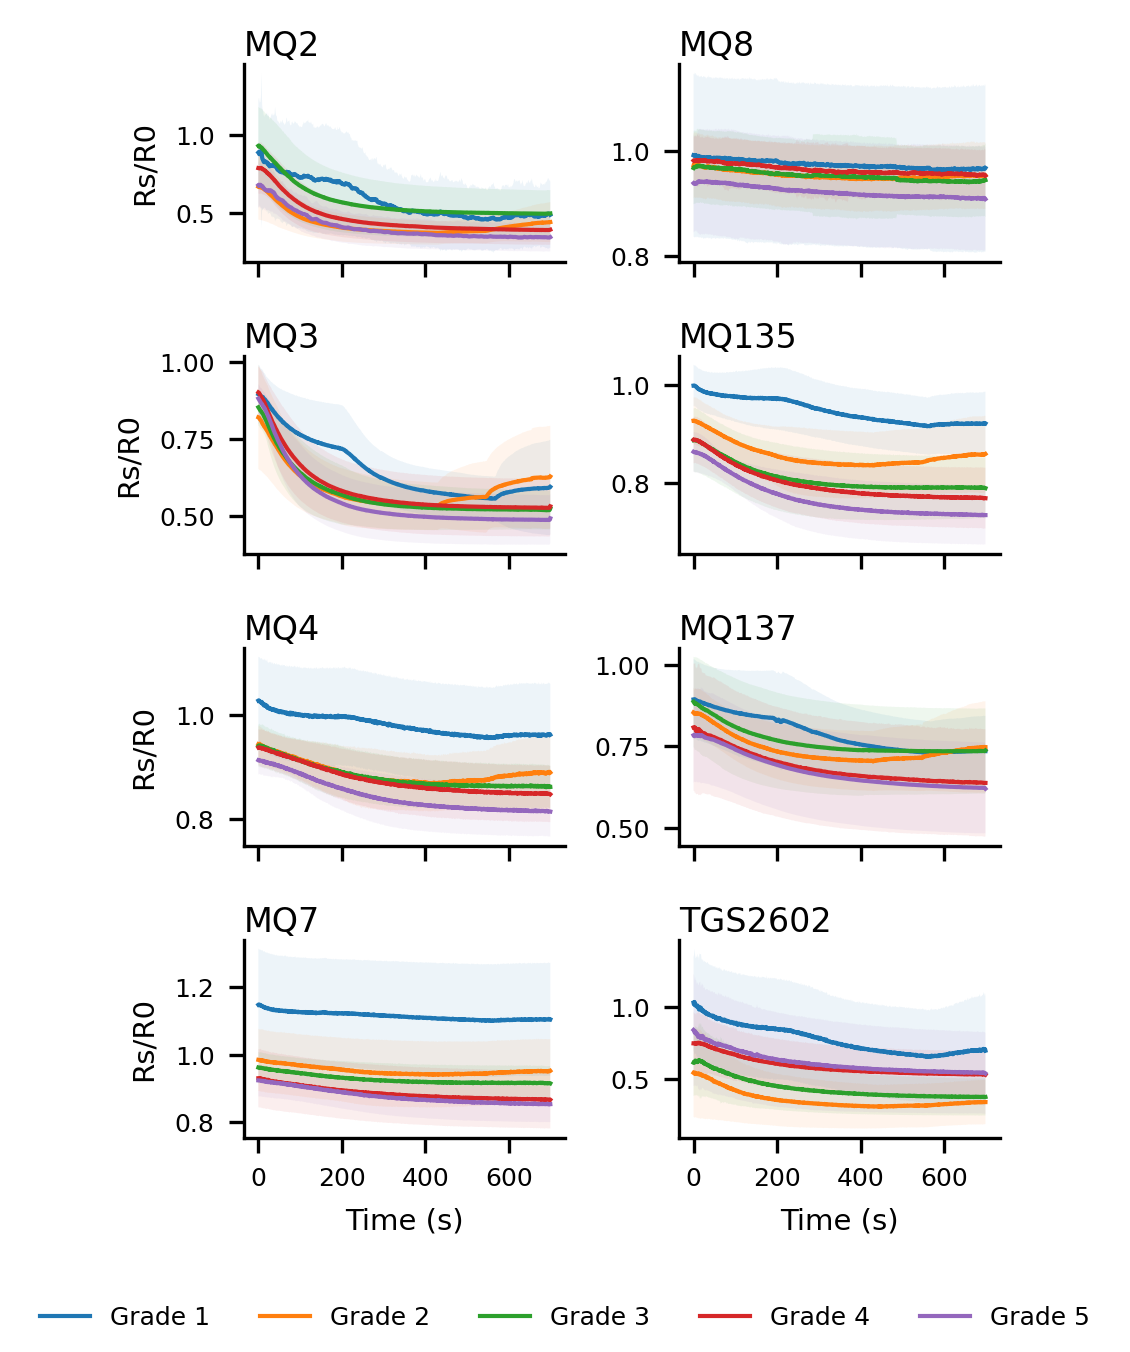

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- 1. Memuat data ----------
df1 = df#pd.read_csv("dataset_enose.csv")      # ganti dengan nama file kamu (atau pd.read_excel)

# Nama kolom sensor persis seperti di dataset; label "TGS2602" hanya untuk judul panel
sensor_cols = ["MQ2", "MQ3", "MQ4", "MQ7", "MQ8", "MQ135", "MQ137", "TGS"]
id_cols     = ["Grade", "Sample", "Siklus"]   # satu kombinasi = satu rekaman

# Urutkan per rekaman berdasarkan Counter (urutan waktu)
df1 = df1.sort_values(id_cols + ["Counter"])

# Cek panjang tiap rekaman sebelum dipotong
lengths = df1.groupby(id_cols).size()
print("Jumlah rekaman:", len(lengths))
print("Rekaman per grade:\n", lengths.groupby(level="Grade").size())
print("Panjang rekaman (min/maks):", lengths.min(), lengths.max())

n_time = min(700, lengths.min())           # 0..700 s; dipotong ke rekaman terpendek jika perlu

X_list, y_list = [], []
for (grade, sample, siklus), g in df.groupby(id_cols):
    arr = g[sensor_cols].to_numpy()[:n_time]          # (n_time, 8)
    X_list.append(arr)
    y_list.append(grade)

X = np.stack(X_list)                       # (n_rekaman, n_time, 8)
y = np.array(y_list)                       # (n_rekaman,)
t = np.arange(n_time)                      # detik, asumsi 1 baris = 1 detik
print("X:", X.shape, "| y unik:", np.unique(y))

# ---------- 2. Plot ----------
# Urutan panel: baris per baris (kiri, kanan); (kolom di dataset, judul panel)
panels = [("MQ2", "MQ2"), ("MQ8", "MQ8"),
          ("MQ3", "MQ3"), ("MQ135", "MQ135"),
          ("MQ4", "MQ4"), ("MQ137", "MQ137"),
          ("MQ7", "MQ7"), ("TGS", "TGS2602")]

grades = sorted(np.unique(y))
fig, axes = plt.subplots(4, 2, figsize=(3.2, 4.5), sharex=True, dpi=300)
for ax, (col, title) in zip(axes.flat, panels):
    j = sensor_cols.index(col)
    for gr in grades:
        d = X[y == gr, :, j]
        m, sd = d.mean(axis=0), d.std(axis=0)
        ax.plot(t, m, lw=1, label=f"Grade {gr}")
        ax.fill_between(t, m - sd, m + sd, alpha=0.08)
    ax.set_title(title, loc="left", fontsize=8, pad=2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=6)

for ax in axes[:, 0]:
    ax.set_ylabel("Rs/R0", fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel("Time (s)", fontsize=7)

h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=5, fontsize=6, frameon=False)
fig.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig("figure2.png", dpi=600)
plt.show()

In [ ]:
new_df = pd.DataFrame(X[0])
new_df

,0,1,2,3,4,5,6,7
0,0.865715,1.022924,1.010504,1.006786,1.000602,0.997857,1.003009,1.034609
1,0.840325,0.992326,1.007607,1.003092,0.996449,0.995177,1.003009,0.996468
2,0.812970,1.015111,1.007607,1.003092,1.000602,1.000551,1.000554,0.972537
3,0.790368,1.011246,1.004726,1.010503,1.000602,1.003258,1.007953,1.034609
4,0.762982,0.999814,1.004726,0.999421,1.000602,1.003258,1.003009,1.021581
...,...,...,...,...,...,...,...,...
695,0.474867,0.372309,0.855494,0.876392,0.716186,0.746389,0.646108,0.618915
696,0.473633,0.374275,0.855494,0.882306,0.713949,0.748000,0.643811,0.623797
697,0.479859,0.376259,0.857652,0.885288,0.711725,0.751239,0.644958,0.623797
698,0.486234,0.373618,0.853347,0.879341,0.713949,0.751239,0.644958,0.638900


## DATASET DEFINITION

In [ ]:
import pandas as pd
import numpy as np

# =========================================================
# LOAD DATASET
# =========================================================

# Contoh:
# df = pd.read_excel("dataset_enose.xlsx")

# Jika CSV:
#df = pd.read_csv("dataset_enose.csv")

print("Shape Dataset Awal :", df.shape)

# =========================================================
# PARAMETER DATASET
# =========================================================

ROWS_PER_BATCH = 1000

# Validasi jumlah data
assert len(df) % ROWS_PER_BATCH == 0, \
    "Jumlah baris tidak habis dibagi 1000"

total_batch = len(df) // ROWS_PER_BATCH

print("Total Batch :", total_batch)

# =========================================================
# LIST PENAMPUNG HASIL
# =========================================================

transient_data = []
steady_data = []
after_steady_data = []
combined_data = []

# =========================================================
# PROCESS SPLITTING
# =========================================================

for batch_idx in range(total_batch):

    # Ambil 1 batch (1000 baris)
    start_idx = batch_idx * ROWS_PER_BATCH
    end_idx = start_idx + ROWS_PER_BATCH

    batch_df = df.iloc[start_idx:end_idx]

    # =====================================================
    # Dataset 1 : Transient (1-200)
    # =====================================================

    transient = batch_df.iloc[0:200]

    # =====================================================
    # Dataset 2 : Steady State (201-500)
    # =====================================================

    steady = batch_df.iloc[200:500]

    # =====================================================
    # Dataset 3 : After Steady (501-700)
    # =====================================================

    after_steady = batch_df.iloc[500:700]

    # =====================================================
    # Dataset 4 : Combined (1-700)
    # =====================================================

    combined = batch_df.iloc[0:700]

    # =====================================================
    # Simpan ke list
    # =====================================================

    transient_data.append(transient)
    steady_data.append(steady)
    after_steady_data.append(after_steady)
    combined_data.append(combined)

# =========================================================
# GABUNGKAN SEMUA BATCH
# =========================================================

transient_dataset = pd.concat(transient_data, ignore_index=True)
steady_dataset = pd.concat(steady_data, ignore_index=True)
after_steady_dataset = pd.concat(after_steady_data, ignore_index=True)
combined_dataset = pd.concat(combined_data, ignore_index=True)

# =========================================================
# CEK SHAPE HASIL
# =========================================================

print("\n===== HASIL SPLIT =====")

print("Transient Dataset Shape      :", transient_dataset.shape)
print("Steady State Dataset Shape   :", steady_dataset.shape)
print("After Steady Dataset Shape   :", after_steady_dataset.shape)
print("Combined Dataset Shape       :", combined_dataset.shape)

# =========================================================
# SAVE DATASET
# =========================================================

transient_dataset.to_csv("dataset_transient.csv", index=False)
steady_dataset.to_csv("dataset_steady_state.csv", index=False)
after_steady_dataset.to_csv("dataset_after_steady.csv", index=False)
combined_dataset.to_csv("dataset_combined.csv", index=False)

print("\nSemua dataset berhasil disimpan!")

Shape Dataset Awal : (500000, 12)
Total Batch : 500

===== HASIL SPLIT =====
Transient Dataset Shape      : (100000, 12)
Steady State Dataset Shape   : (150000, 12)
After Steady Dataset Shape   : (100000, 12)
Combined Dataset Shape       : (350000, 12)

Semua dataset berhasil disimpan!


### DEFINE DATASET LABELS

In [ ]:
# Define labelling for the grades
Labels = []
counter = 1
class_id = 1

for i in range(500):
  Labels.append(class_id)
  if counter % 100 == 0:
    class_id += 1

  counter += 1

Labels = np.array(Labels)
Labels

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4,

## DATASET PRE-PROCESSING

### Check Missing Data

In [ ]:
# Global
raw_dataset = df.iloc[:,2:10]
raw_dataset['Grade'] = df.iloc[:,-1]
raw_dataset.head()

,MQ2,MQ3,MQ4,MQ7,MQ8,MQ135,MQ137,TGS,Grade
0,0.865715,1.022924,1.010504,1.006786,1.000602,0.997857,1.003009,1.034609,1
1,0.840325,0.992326,1.007607,1.003092,0.996449,0.995177,1.003009,0.996468,1
2,0.812970,1.015111,1.007607,1.003092,1.000602,1.000551,1.000554,0.972537,1
3,0.790368,1.011246,1.004726,1.010503,1.000602,1.003258,1.007953,1.034609,1
4,0.762982,0.999814,1.004726,0.999421,1.000602,1.003258,1.003009,1.021581,1


In [ ]:
raw_dataset.isnull().sum()

,0
MQ2,0
MQ3,0
MQ4,0
MQ7,0
MQ8,0
MQ135,0
MQ137,0
TGS,0
Grade,0


In [ ]:
# checked for duplicated data
#raw_dataset[raw_dataset.duplicated()]
duplicate_row = raw_dataset[raw_dataset.duplicated()].index
duplicate_row

Index([ 20837,  21507,  25010,  30405,  37561,  42004,  45676,  47275,  54468,
        61198,
       ...
       366210, 367827, 371202, 379514, 394589, 406285, 412842, 421610, 426399,
       470451],
      dtype='int64', length=529)

In [ ]:
raw_dataset.values.reshape(-1,)

array([0.86571502, 1.02292426, 1.01050362, ..., 0.82381566, 0.45827699,
       5.        ])

In [ ]:
duplicate_row = raw_dataset[raw_dataset.duplicated()].index
duplicate_row

Index([ 20837,  21507,  25010,  30405,  37561,  42004,  45676,  47275,  54468,
        61198,
       ...
       366210, 367827, 371202, 379514, 394589, 406285, 412842, 421610, 426399,
       470451],
      dtype='int64', length=529)

In [ ]:
raw_dataset.shape

(500000, 9)

### Noise Filtering/Denoising

In [ ]:
#DEFINE WAVELET FAMILIES

sym_wavelets = [wavelet for wavelet in pywt.wavelist(kind='discrete') if wavelet.startswith("sym")]
db_wavelets = [wavelet for wavelet in pywt.wavelist(kind='discrete') if wavelet.startswith("db")]
coif_wavelets = [wavelet for wavelet in pywt.wavelist(kind='discrete') if wavelet.startswith("coif")]
bior_wavelets = [wavelet for wavelet in pywt.wavelist(kind='discrete') if wavelet.startswith("bior")]
haar_wavelets = [wavelet for wavelet in pywt.wavelist(kind='discrete') if wavelet.startswith("haar")]
dmey_wavelets = [wavelet for wavelet in pywt.wavelist(kind='discrete') if wavelet.startswith("dmey")]
rbio_wavelets = [wavelet for wavelet in pywt.wavelist(kind='discrete') if wavelet.startswith("rbio")]
print(len(sym_wavelets))
print(len(db_wavelets))
print(len(coif_wavelets))
print(len(bior_wavelets))
print(len(haar_wavelets))
print(len(dmey_wavelets))
print(len(rbio_wavelets))

19
38
17
15
1
1
15


In [ ]:
# SHOW ONLY DISCRETE WAVELETS
discrete_wavelets = pywt.wavelist(kind='discrete')
print(len(discrete_wavelets))

106


In [ ]:
# Noise Filtering (Denoising) using wavelet
def wavelet_denoise(signal, wavelet='db6', level=1):

    # 1. Decompose: Decompose signal using wavelet
    coeffs = pywt.wavedec(signal, wavelet, level=level)

    # 2. Thresholding: apply hard threshold for detail coeffs
    sigma = np.median(np.abs(coeffs[-1])) / 0.6745  # Estimasi noise
    threshold = sigma * np.sqrt(2 * np.log(len(signal)))  # Threshold adaptif
    new_coeffs = [coeffs[0]] + [pywt.threshold(c, threshold, mode='hard') for c in coeffs[1:]]

    # 3. Signal Reconstruction
    denoised_signal = pywt.waverec(new_coeffs, wavelet)
    return denoised_signal


In [ ]:
import pandas

def do_noise_filtering(dataset, num_timestep_per_sample=300, wavelet='db6', level=1) -> pandas.core.frame.DataFrame:

  start_idx = 0
  denoised_resultset = pd.DataFrame(dtype="object")

  for i in range(int(dataset.shape[0]/num_timestep_per_sample)):
    signal_sample = dataset.iloc[start_idx : (start_idx + num_timestep_per_sample), :]

    # Denoising step per-sample per-sensor type
    denoised_data = pd.DataFrame(dtype="object")
    for col in signal_sample.columns:
      denoised_signal = wavelet_denoise(signal_sample[col].values, wavelet=wavelet, level=level)
      denoised_data[col] = denoised_signal[:len(signal_sample)]

    denoised_resultset = pd.concat([denoised_resultset, denoised_data], axis=0, ignore_index=True)
    start_idx += num_timestep_per_sample

  return denoised_resultset

In [ ]:
import pywt
import numpy as np

def wavelet_denoise_final(signal, wavelet='db2', level=3, mode='soft', eps=1e-8):

    # --- 1. specify safety level ---
    w = pywt.Wavelet(wavelet)
    max_level = pywt.dwt_max_level(len(signal), w.dec_len)
    level = min(level, max_level)

    # --- 2. decompotition (MODE KONSISTEN) ---
    coeffs = pywt.wavedec(
        signal,
        wavelet,
        level=level,
        mode='periodization'
    )

    # --- 3. find threshold (MAD) ---
    sigma = np.median(np.abs(coeffs[-1])) / (0.6745 + eps)
    T = sigma * np.sqrt(2 * np.log(len(signal) + eps))

    # --- 4. Thresholding (approximation TIDAK disentuh) ---
    new_coeffs = [coeffs[0]]

    for c in coeffs[1:]:
        c_new = apply_threshold(c, T, mode, eps)

        # ⛔ pastikan shape TIDAK berubah
        if c_new.shape != c.shape:
            raise ValueError("Coefficient shape changed during thresholding")

        new_coeffs.append(c_new)

    # --- 5. reconstruction (MODE HARUS SAMA) ---
    denoised = pywt.waverec(
        new_coeffs,
        wavelet,
        mode='periodization'
    )

    # --- 6. Trim agar panjang sama ---
    return denoised[:len(signal)]


def apply_threshold(c, T, mode='soft', eps=1e-8):

    if mode == 'hard':
        return c * (np.abs(c) > T)

    elif mode == 'soft':
        return np.sign(c) * np.maximum(np.abs(c) - T, 0)

    elif mode == 'garrote':
        abs_c = np.abs(c)
        shrink = np.zeros_like(c)
        mask = abs_c > T
        shrink[mask] = 1 - T / (abs_c[mask] + eps)
        return c * shrink

    elif mode == 'greater':
        return np.maximum(c - T, 0)

    elif mode == 'less':
        return np.minimum(c + T, 0)

    else:
        raise ValueError("Unknown threshold mode")


In [ ]:
import pandas

def do_noise_filtering2(dataset, num_timestep_per_sample=300, wavelet='db6', level=1, mode='hard') -> pandas.core.frame.DataFrame:

  start_idx = 0
  denoised_resultset = pd.DataFrame(dtype="object")

  for i in range(int(dataset.shape[0]/num_timestep_per_sample)):
    signal_sample = dataset.iloc[start_idx : (start_idx + num_timestep_per_sample), :]

    # Denoising step per-sample per-sensor type
    denoised_data = pd.DataFrame(dtype="object")
    for col in signal_sample.columns:
      denoised_signal = wavelet_denoise_final(signal_sample[col].values, wavelet=wavelet, level=level, mode=mode)
      denoised_data[col] = denoised_signal[:len(signal_sample)]

    denoised_resultset = pd.concat([denoised_resultset, denoised_data], axis=0, ignore_index=True)
    start_idx += num_timestep_per_sample

  return denoised_resultset

### Apply Noise Filtering for Each Sub Datasets

In [ ]:
denoised_dataset_t = do_noise_filtering(transient_dataset.iloc[:,2:10], 200, 'bior3.5', 4)
denoised_dataset_t

,MQ2,MQ3,MQ4,MQ7,MQ8,MQ135,MQ137,TGS
0,0.865887,1.023384,1.007452,1.006744,0.999529,0.997320,1.002263,1.037572
1,0.838573,0.992311,1.007682,1.003657,0.999352,0.999396,1.002081,0.990703
2,0.814365,1.014204,1.007663,1.004724,0.999159,1.001035,1.002865,0.982390
3,0.793262,1.009029,1.007393,1.009943,0.998950,1.002237,1.004615,1.012635
4,0.760395,0.999829,1.006873,0.997806,0.998727,1.002245,1.004576,1.038815
...,...,...,...,...,...,...,...,...
99995,0.407875,0.542588,0.858730,0.850179,0.824300,0.796454,0.777275,0.347168
99996,0.405919,0.542580,0.858958,0.850327,0.824341,0.796567,0.776999,0.346811
99997,0.410824,0.542609,0.859207,0.850561,0.824398,0.796284,0.776736,0.346446
99998,0.413632,0.542635,0.859428,0.850775,0.824451,0.796073,0.776513,0.346088


In [ ]:
denoised_dataset_st = do_noise_filtering(steady_dataset.iloc[:,2:10], 300, 'bior3.5', 4)
denoised_dataset_st

,MQ2,MQ3,MQ4,MQ7,MQ8,MQ135,MQ137,TGS
0,0.532189,0.370649,0.851380,0.881238,0.701911,0.785516,0.703865,0.732887
1,0.545929,0.370669,0.845344,0.882010,0.701768,0.785609,0.702315,0.732805
2,0.556664,0.370321,0.844819,0.885014,0.701623,0.785674,0.700979,0.732714
3,0.564392,0.369606,0.849806,0.890252,0.701474,0.785710,0.699857,0.732614
4,0.569898,0.368524,0.848942,0.891131,0.701323,0.785720,0.698949,0.732504
...,...,...,...,...,...,...,...,...
149995,0.454938,0.493424,0.835576,0.840677,0.803558,0.775362,0.732555,0.313226
149996,0.467360,0.493317,0.835830,0.840902,0.801315,0.775468,0.732294,0.312811
149997,0.482678,0.493219,0.836052,0.841683,0.803373,0.774308,0.732170,0.313298
149998,0.508083,0.493128,0.836242,0.842150,0.804693,0.773448,0.732181,0.289212


In [ ]:
denoised_dataset_ast = do_noise_filtering(after_steady_dataset.iloc[:,2:10], 200, 'bior3.5', 4)
denoised_dataset_ast

,MQ2,MQ3,MQ4,MQ7,MQ8,MQ135,MQ137,TGS
0,0.458140,0.360736,0.838808,0.864302,0.674910,0.737233,0.641286,0.619380
1,0.460106,0.360377,0.837700,0.865166,0.674999,0.737552,0.640621,0.619533
2,0.470571,0.360161,0.832615,0.865696,0.675098,0.737702,0.640233,0.619732
3,0.489535,0.360090,0.823551,0.865892,0.675206,0.737684,0.640123,0.619975
4,0.499422,0.360163,0.841811,0.865754,0.675325,0.737498,0.640289,0.620264
...,...,...,...,...,...,...,...,...
99995,0.503136,0.491962,0.831258,0.841066,0.809817,0.771676,0.727452,0.307885
99996,0.471295,0.491318,0.831290,0.841283,0.809713,0.769606,0.727450,0.307976
99997,0.453628,0.490286,0.831413,0.841524,0.809576,0.766506,0.725699,0.308033
99998,0.441319,0.493633,0.831535,0.841740,0.809460,0.767748,0.722382,0.308091


In [ ]:
denoised_dataset_comb = do_noise_filtering(combined_dataset.iloc[:,2:10], 700, 'bior3.5', 4)
denoised_dataset_comb

,MQ2,MQ3,MQ4,MQ7,MQ8,MQ135,MQ137,TGS
0,0.865887,1.023384,1.007452,1.004310,0.999529,0.997437,1.002392,1.037348
1,0.838573,0.992311,1.007682,1.002759,0.999352,0.999546,1.002270,0.985558
2,0.814365,1.014204,1.007663,1.004993,0.999159,1.001143,1.003044,0.983844
3,0.793262,1.009029,1.007393,1.011012,0.998950,1.002227,1.004713,1.032205
4,0.760395,0.999829,1.006873,0.998630,0.998727,1.002799,1.004524,1.019245
...,...,...,...,...,...,...,...,...
349995,0.502057,0.492125,0.832746,0.840750,0.809384,0.769855,0.726430,0.308670
349996,0.469898,0.491323,0.832685,0.840765,0.809480,0.768211,0.725933,0.308667
349997,0.452788,0.490143,0.832629,0.840851,0.809562,0.765684,0.725336,0.308664
349998,0.440893,0.493369,0.832578,0.841007,0.809629,0.767412,0.722808,0.308658


### Dataset Re-Structuring

In [ ]:
reshaped_transient_dataset = transient_dataset.iloc[:,2:10].copy().values.reshape(-1,200,8)
reshaped_steady_dataset = steady_dataset.iloc[:,2:10].copy().values.reshape(-1,300,8)
reshaped_after_steady_dataset = after_steady_dataset.iloc[:,2:10].copy().values.reshape(-1,200,8)
reshaped_combined_dataset = combined_dataset.iloc[:,2:10].copy().values.reshape(-1,700,8)

new_transient_denoised_dataset = denoise_dataset_multisensor(
    reshaped_transient_dataset,
    wavelet='bior3.5',
    level=4
)

new_steady_denoised_dataset = denoise_dataset_multisensor(
    reshaped_steady_dataset,
    wavelet='bior3.5',
    level=4
)

new_after_steady_denoised_dataset = denoise_dataset_multisensor(
    reshaped_after_steady_dataset,
    wavelet='bior3.5',
    level=4
)

new_combined_denoised_dataset = denoise_dataset_multisensor(
    reshaped_combined_dataset,
    wavelet='bior3.5',
    level=4
)

NameError: name 'denoise_dataset_multisensor' is not defined

In [ ]:
reshaped_transient_dataset.shape

In [ ]:
print("===== Transient Dataset Grade Summary =====")
display(transient_dataset['Grade'].value_counts())
for i in range(5):
  i += 1
  display(transient_dataset[transient_dataset['Grade']==i].index)

print("===== Steady Dataset Grade Summary =====")
display(steady_dataset['Grade'].value_counts())
for i in range(5):
  i += 1
  display(steady_dataset[steady_dataset['Grade']==i].index)

print("===== After Steady Dataset Grade Summary =====")
display(after_steady_dataset['Grade'].value_counts())
for i in range(5):
  i += 1
  display(after_steady_dataset[after_steady_dataset['Grade']==i].index)

print("===== Combined Dataset Grade Summary =====")
display(combined_dataset['Grade'].value_counts())
for i in range(5):
  i += 1
  display(combined_dataset[combined_dataset['Grade']==i].index)


In [ ]:
# Define Segmented Transient
segmented_transient_dataset = transient_dataset.iloc[:,2:10].values.reshape(-1,200,8)
flatten_segmented_transient_dataset = segmented_transient_dataset.reshape(-1,1600)
flatten_segmented_transient_dataset_df = pd.DataFrame(data=flatten_segmented_transient_dataset,dtype=object)
flatten_segmented_transient_dataset_df['Grade'] = Labels

display(segmented_transient_dataset.shape)
display(flatten_segmented_transient_dataset_df.shape)

# Define Segmented Steady
segmented_steady_dataset = steady_dataset.iloc[:,2:10].values.reshape(-1,300,8)
flatten_segmented_steady_dataset = segmented_steady_dataset.reshape(-1,2400)
flatten_segmented_steady_dataset_df = pd.DataFrame(data=flatten_segmented_steady_dataset,dtype=object)
flatten_segmented_steady_dataset_df['Grade'] = Labels

display(segmented_steady_dataset.shape)
display(flatten_segmented_steady_dataset_df.shape)

# Define Segmented After Steady
segmented_after_steady_dataset = after_steady_dataset.iloc[:,2:10].values.reshape(-1,200,8)
flatten_segmented_after_steady_dataset = segmented_after_steady_dataset.reshape(-1,1600)
flatten_segmented_after_steady_dataset_df = pd.DataFrame(data=flatten_segmented_after_steady_dataset,dtype=object)
flatten_segmented_after_steady_dataset_df['Grade'] = Labels

display(segmented_after_steady_dataset.shape)
display(flatten_segmented_after_steady_dataset_df.shape)

# Define Segmened Combined
segmented_combined_dataset = combined_dataset.iloc[:,2:10].values.reshape(-1,700,8)
flatten_segmented_combined_dataset = segmented_combined_dataset.reshape(-1,5600)
flatten_segmented_combined_dataset_df = pd.DataFrame(data=flatten_segmented_combined_dataset,dtype=object)
flatten_segmented_combined_dataset_df['Grade'] = Labels

display(segmented_combined_dataset.shape)
display(flatten_segmented_combined_dataset_df.shape)

In [ ]:
# Define Segmented Transient Denoised
segmented_transient_denoised_dataset = denoised_dataset_t.values.reshape(-1,200,8)
flatten_segmented_transient_denoised_dataset = segmented_transient_denoised_dataset.reshape(-1,1600)
flatten_segmented_transient_denoised_dataset_df = pd.DataFrame(data=flatten_segmented_transient_denoised_dataset,dtype=object)
flatten_segmented_transient_denoised_dataset_df['Grade'] = Labels

display(segmented_transient_denoised_dataset.shape)
display(flatten_segmented_transient_denoised_dataset_df.shape)

# Define Segmented Steady Denoised
segmented_steady_denoised_dataset = denoised_dataset_st.values.reshape(-1,300,8)
flatten_segmented_steady_denoised_dataset = segmented_steady_denoised_dataset.reshape(-1,2400)
flatten_segmented_steady_denoised_dataset_df = pd.DataFrame(data=flatten_segmented_steady_denoised_dataset,dtype=object)
flatten_segmented_steady_denoised_dataset_df['Grade'] = Labels

display(segmented_steady_denoised_dataset.shape)
display(flatten_segmented_steady_denoised_dataset_df.shape)

# Define Segmented After Steady Denoised
segmented_after_steady_denoised_dataset = denoised_dataset_ast.values.reshape(-1,200,8)
flatten_segmented_after_steady_denoised_dataset = segmented_after_steady_denoised_dataset.reshape(-1,1600)
flatten_segmented_after_steady_denoised_dataset_df = pd.DataFrame(data=flatten_segmented_after_steady_denoised_dataset,dtype=object)
flatten_segmented_after_steady_denoised_dataset_df['Grade'] = Labels

display(segmented_after_steady_denoised_dataset.shape)
display(flatten_segmented_after_steady_denoised_dataset_df.shape)

# Define Segmented Combined Denoised
segmented_combined_denoised_dataset = denoised_dataset_comb.values.reshape(-1,700,8)
flatten_segmented_combined_denoised_dataset = segmented_combined_denoised_dataset.reshape(-1,5600)
flatten_segmented_combined_denoised_dataset_df = pd.DataFrame(data=flatten_segmented_combined_denoised_dataset,dtype=object)
flatten_segmented_combined_denoised_dataset_df['Grade'] = Labels

display(segmented_combined_denoised_dataset.shape)
display(flatten_segmented_combined_denoised_dataset_df.shape)

### Plot Signal (At Any Specific Batch)

In [ ]:
# Test Signal Profile (at Specific SAMPLE BATCH and Specific Sensors)

from matplotlib import pyplot as plt

plt.title("signal MQ7 at one sample")
plt.plot(segmented_transient_dataset[0,:,3], label='raw-signal', color='blue')
plt.plot(segmented_transient_denoised_dataset[0,:,3], label='denoised-signal', linewidth='1.5', linestyle="dashed", color='magenta')

plt.legend()
plt.show()

## Set randomization

In [ ]:
def set_seed(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["TF_DETERMINISTIC_OPS"] = "1"  # ops deterministik
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seed(42)

## Baseline Classification

In [ ]:
# Compare all Model
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from xgboost import XGBClassifier
import pandas as pd


def doClassif(Dataset, rows_number, cols_number, t_size):
    all_feature_extractions_with_orig_data_df = pd.concat([Dataset.iloc[:,:-1]], axis=1, ignore_index=True)
    # flatten_df, stft_features_df, stats_feature_extraction_df, denoised_flatten_df, denoised_stft_features_df, denoised_stats_feature_extraction_df, sliding_features, fft_features

    # Split data to train & test set
    _X_train00, _X_test00, _y_train00, _y_test00 = train_test_split(
        all_feature_extractions_with_orig_data_df, Dataset['Grade'] - 1, test_size=t_size, random_state=42, stratify=Dataset['Grade'] - 1
    )

    # Standardize the data (scaling)
    scaler = StandardScaler()

    _X_train00 = scaler.fit_transform(_X_train00)
    _X_test00 = scaler.transform(_X_test00)

    # Train a Support Vector Machine (SVM) classifier

    list_models = {
        "SVM (RBF)": SVC(kernel='rbf', C=2.5, gamma='scale', random_state=42),

        "Random Forest": RandomForestClassifier(
            n_estimators=200, max_depth=None, random_state=42
        ),

        "Decision Tree": DecisionTreeClassifier(
            max_depth=None, random_state=42
        ),

        "XGBoost": XGBClassifier(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric='mlogloss'
        ),

        "Logistic Regression": LogisticRegression(
            max_iter=1000, random_state=42
        ),

        "MLP": MLPClassifier(
            hidden_layer_sizes=(200,),
            max_iter=500,
            random_state=42
        ),

        "KNN": KNeighborsClassifier(
            n_neighbors=7
        ),

        #"NAIVE BAYES": NaiveBayesClassifier()
    }

    results = []

    for model_name, model in list_models.items():
        model.fit(_X_train00, _y_train00)
        y_pred = model.predict(_X_test00)

        results.append({
            "Model": model_name,
            "Accuracy": accuracy_score(_y_test00, y_pred),
            "Precision (Macro)": precision_score(_y_test00, y_pred, average='macro'),
            "Recall (Macro)": recall_score(_y_test00, y_pred, average='macro'),
            "F1-score (Macro)": f1_score(_y_test00, y_pred, average='macro')
        })

    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(by="F1-score (Macro)", ascending=False)

    display(results_df)

    best_model_name = results_df.iloc[0]["Model"]
    best_model = list_models[best_model_name]

    y_best_pred = best_model.predict(_X_test00)

    conf_mat = confusion_matrix(_y_test00, y_best_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
                xticklabels=["Class1","Class2","Class3","Class4","Class5"],
                yticklabels=["Class1","Class2","Class3","Class4","Class5"])
    plt.title(f"Confusion Matrix - {best_model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()



### 1. Transient

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,SVM (RBF),0.933333,0.941270,0.933333,0.934722
5,MLP,0.933333,0.939048,0.933333,0.933509
1,Random Forest,0.920000,0.923663,0.920000,0.919224
3,XGBoost,0.866667,0.870036,0.866667,0.866384
6,KNN,0.866667,0.880530,0.866667,0.866380
4,Logistic Regression,0.826667,0.863030,0.826667,0.823211
2,Decision Tree,0.813333,0.818522,0.813333,0.809353


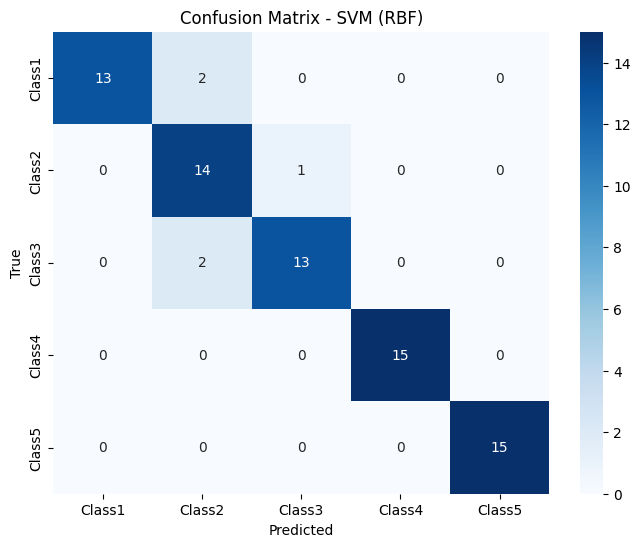

In [ ]:
doClassif(flatten_segmented_transient_dataset_df, 200, 8, 0.15)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.94,0.943863,0.94,0.939568
0,SVM (RBF),0.91,0.917172,0.91,0.910139
1,Random Forest,0.89,0.891987,0.89,0.888432
6,KNN,0.88,0.897619,0.88,0.879310
3,XGBoost,0.85,0.851704,0.85,0.850425
4,Logistic Regression,0.84,0.856824,0.84,0.838659
2,Decision Tree,0.80,0.800357,0.80,0.797570


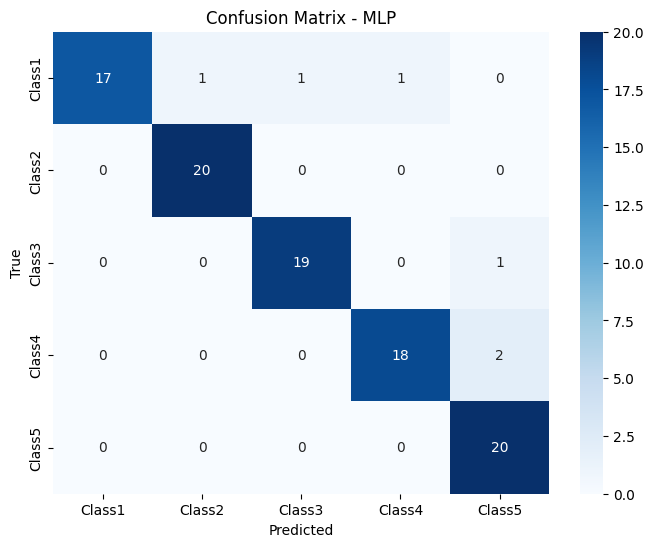

In [ ]:
doClassif(flatten_segmented_transient_dataset_df, 200, 8, 0.2)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.920,0.925103,0.920,0.920623
0,SVM (RBF),0.912,0.914377,0.912,0.912054
1,Random Forest,0.888,0.891441,0.888,0.888688
3,XGBoost,0.880,0.880386,0.880,0.879615
6,KNN,0.880,0.888867,0.880,0.879351
4,Logistic Regression,0.800,0.809592,0.800,0.799306
2,Decision Tree,0.768,0.766954,0.768,0.764814


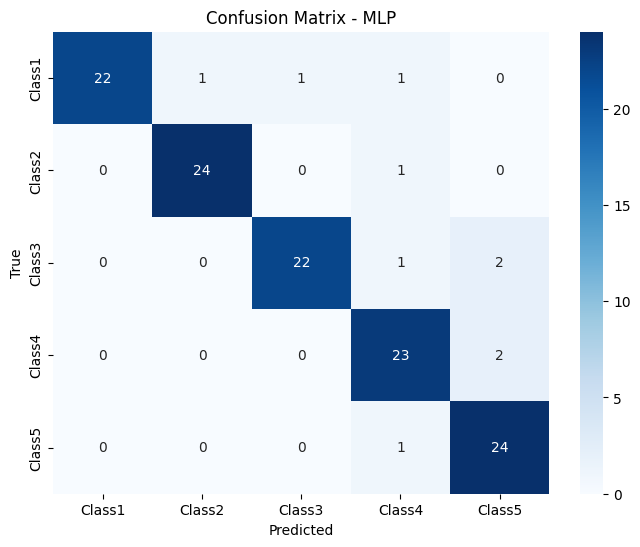

In [ ]:
doClassif(flatten_segmented_transient_dataset_df, 200, 8, 0.25)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:698: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,SVM (RBF),0.926667,0.929960,0.926667,0.926505
5,MLP,0.893333,0.894987,0.893333,0.892264
1,Random Forest,0.886667,0.887941,0.886667,0.884052
6,KNN,0.880000,0.888459,0.880000,0.880421
3,XGBoost,0.846667,0.844707,0.846667,0.844320
4,Logistic Regression,0.800000,0.807675,0.800000,0.799177
2,Decision Tree,0.760000,0.765294,0.760000,0.760178


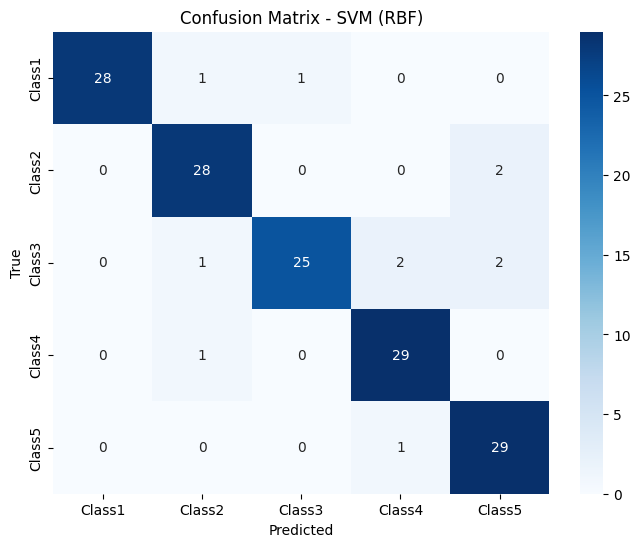

In [ ]:
doClassif(flatten_segmented_transient_dataset_df, 200, 8, 0.3)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.933333,0.936948,0.933333,0.933786
0,SVM (RBF),0.926667,0.929960,0.926667,0.926505
6,KNN,0.880000,0.888459,0.880000,0.880421
1,Random Forest,0.880000,0.880840,0.880000,0.878844
3,XGBoost,0.873333,0.871176,0.873333,0.871195
4,Logistic Regression,0.800000,0.806750,0.800000,0.799032
2,Decision Tree,0.733333,0.745579,0.733333,0.733575


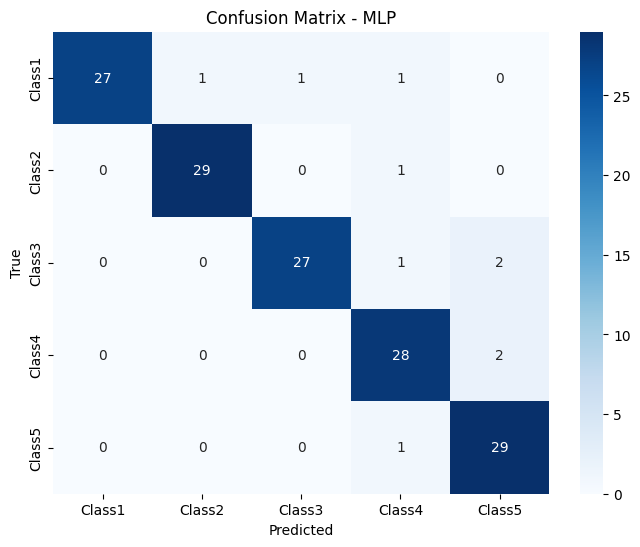

In [ ]:
doClassif(flatten_segmented_transient_denoised_dataset_df, 200, 8, 0.3)

### 2. Steady

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.933333,0.938655,0.933333,0.933128
3,XGBoost,0.933333,0.941667,0.933333,0.932407
0,SVM (RBF),0.920000,0.934365,0.920000,0.921113
1,Random Forest,0.920000,0.929412,0.920000,0.918056
6,KNN,0.893333,0.912185,0.893333,0.893184
2,Decision Tree,0.800000,0.824494,0.800000,0.805285
4,Logistic Regression,0.706667,0.743156,0.706667,0.709891


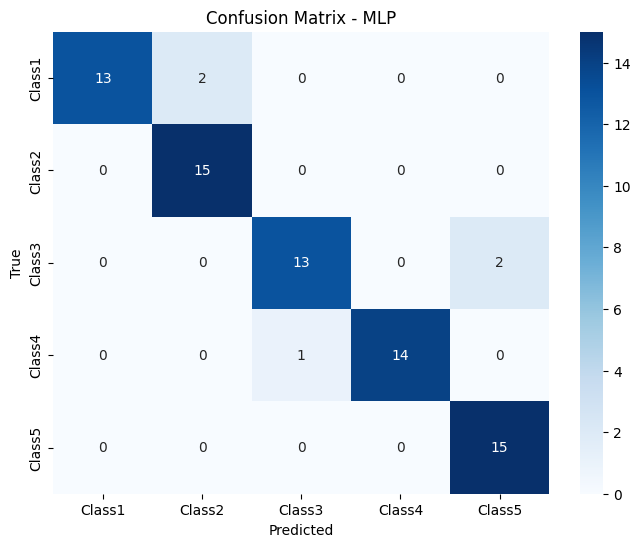

In [ ]:
doClassif(flatten_segmented_steady_dataset_df, 300, 8, 0.15)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.91,0.920952,0.91,0.910395
3,XGBoost,0.91,0.914376,0.91,0.909407
0,SVM (RBF),0.89,0.901029,0.89,0.890719
1,Random Forest,0.89,0.896439,0.89,0.889153
6,KNN,0.88,0.901474,0.88,0.880488
2,Decision Tree,0.79,0.805614,0.79,0.787291
4,Logistic Regression,0.75,0.771543,0.75,0.751526


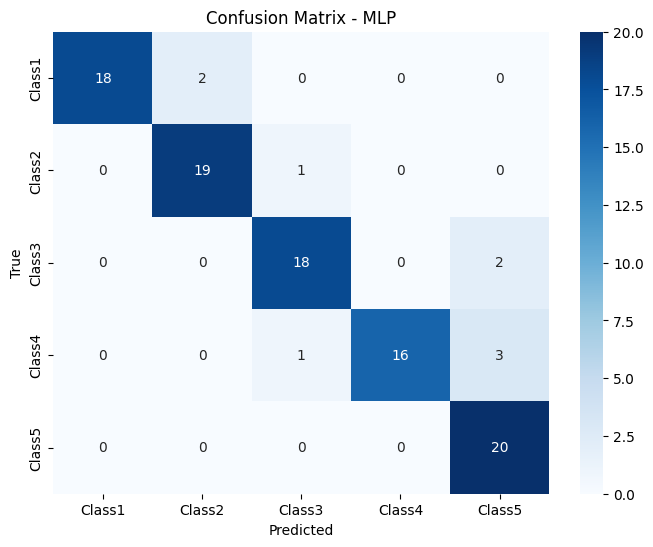

In [ ]:
doClassif(flatten_segmented_steady_dataset_df, 300, 8, 0.2)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.928,0.931348,0.928,0.928367
6,KNN,0.904,0.921290,0.904,0.905170
3,XGBoost,0.880,0.885460,0.880,0.881015
1,Random Forest,0.872,0.879489,0.872,0.872185
0,SVM (RBF),0.872,0.879793,0.872,0.870322
2,Decision Tree,0.768,0.766855,0.768,0.766174
4,Logistic Regression,0.688,0.703437,0.688,0.692814


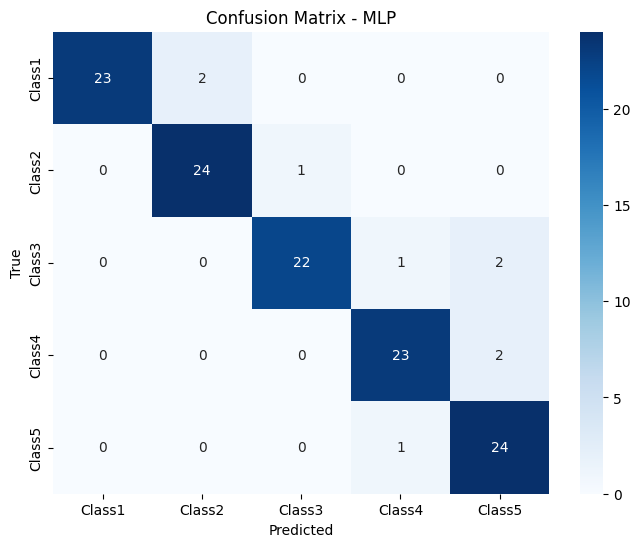

In [ ]:
doClassif(flatten_segmented_steady_dataset_df, 300, 8, 0.25)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.933333,0.935927,0.933333,0.933711
6,KNN,0.893333,0.907328,0.893333,0.894166
0,SVM (RBF),0.893333,0.899520,0.893333,0.893292
1,Random Forest,0.866667,0.868210,0.866667,0.864521
3,XGBoost,0.846667,0.847405,0.846667,0.845702
2,Decision Tree,0.766667,0.769217,0.766667,0.766609
4,Logistic Regression,0.693333,0.692822,0.693333,0.691849


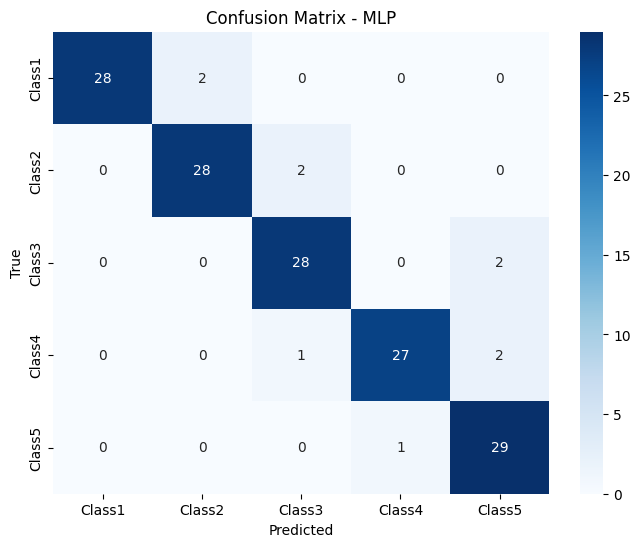

In [ ]:
doClassif(flatten_segmented_steady_dataset_df, 300, 8, 0.3)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.933333,0.935927,0.933333,0.933711
6,KNN,0.893333,0.907328,0.893333,0.894166
0,SVM (RBF),0.893333,0.899520,0.893333,0.893292
1,Random Forest,0.873333,0.874855,0.873333,0.871927
3,XGBoost,0.860000,0.861030,0.860000,0.859769
2,Decision Tree,0.773333,0.780871,0.773333,0.774386
4,Logistic Regression,0.700000,0.700989,0.700000,0.699004


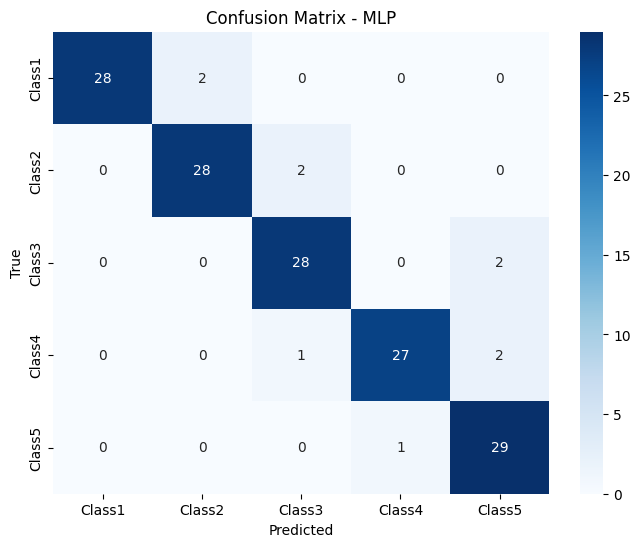

In [ ]:
doClassif(flatten_segmented_steady_denoised_dataset_df, 300, 8, 0.3)

### 3. After Steady

In [ ]:
doClassif(flatten_segmented_after_steady_dataset_df, 200, 8, 0.15)

In [ ]:
doClassif(flatten_segmented_after_steady_dataset_df, 200, 8, 0.2)

In [ ]:
doClassif(flatten_segmented_after_steady_dataset_df, 200, 8, 0.25)

In [ ]:
doClassif(flatten_segmented_after_steady_dataset_df, 200, 8, 0.3)

In [ ]:
doClassif(flatten_segmented_after_steady_denoised_dataset_df, 200, 8, 0.3)

### 4. Combined

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.946667,0.952941,0.946667,0.946921
0,SVM (RBF),0.933333,0.945395,0.933333,0.934551
3,XGBoost,0.920000,0.929167,0.920000,0.919504
6,KNN,0.893333,0.910276,0.893333,0.892544
1,Random Forest,0.893333,0.897753,0.893333,0.890376
4,Logistic Regression,0.840000,0.858120,0.840000,0.839009
2,Decision Tree,0.760000,0.770550,0.760000,0.758715


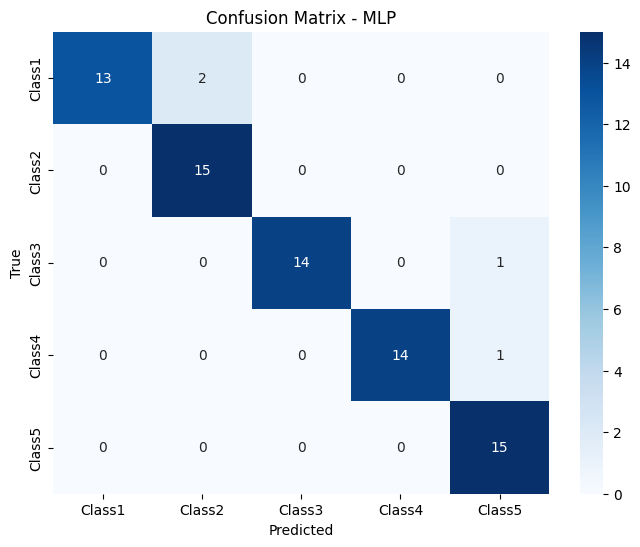

In [ ]:
doClassif(flatten_segmented_combined_dataset_df, 700, 8, 0.15)

In [ ]:
doClassif(flatten_segmented_combined_denoised_dataset_df, 700, 8, 0.15)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.96,0.962294,0.96,0.959382
0,SVM (RBF),0.92,0.929469,0.92,0.920070
3,XGBoost,0.90,0.901992,0.90,0.899868
1,Random Forest,0.88,0.881867,0.88,0.877767
6,KNN,0.87,0.892000,0.87,0.869150
4,Logistic Regression,0.83,0.839864,0.83,0.829431
2,Decision Tree,0.75,0.764779,0.75,0.749991


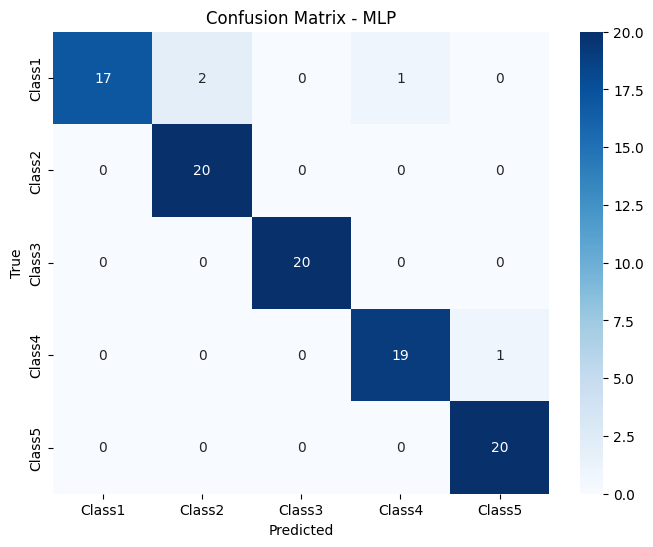

In [ ]:
doClassif(flatten_segmented_combined_dataset_df, 700, 8, 0.2)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.936,0.937079,0.936,0.935788
0,SVM (RBF),0.928,0.934319,0.928,0.927732
3,XGBoost,0.888,0.891268,0.888,0.888348
6,KNN,0.880,0.892656,0.880,0.879909
1,Random Forest,0.872,0.873401,0.872,0.870084
4,Logistic Regression,0.816,0.826886,0.816,0.813768
2,Decision Tree,0.800,0.808874,0.800,0.797686


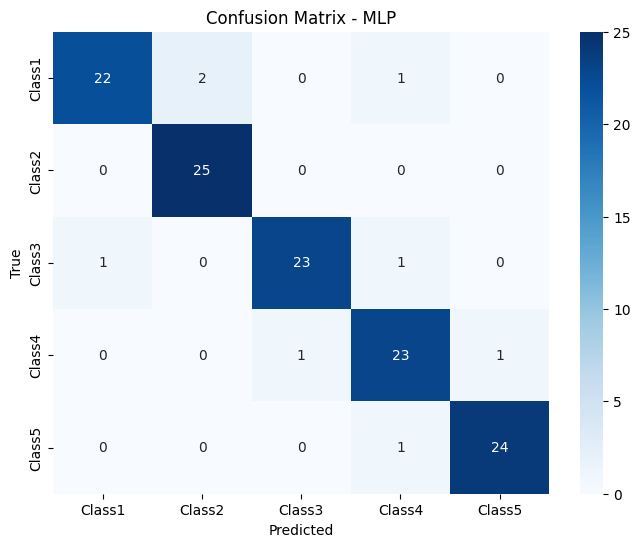

In [ ]:
doClassif(flatten_segmented_combined_dataset_df, 700, 8, 0.25)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.966667,0.967930,0.966667,0.966759
0,SVM (RBF),0.933333,0.936888,0.933333,0.933409
6,KNN,0.893333,0.901795,0.893333,0.893689
3,XGBoost,0.880000,0.880356,0.880000,0.877589
1,Random Forest,0.853333,0.859427,0.853333,0.852898
4,Logistic Regression,0.826667,0.836289,0.826667,0.825264
2,Decision Tree,0.786667,0.787679,0.786667,0.786474


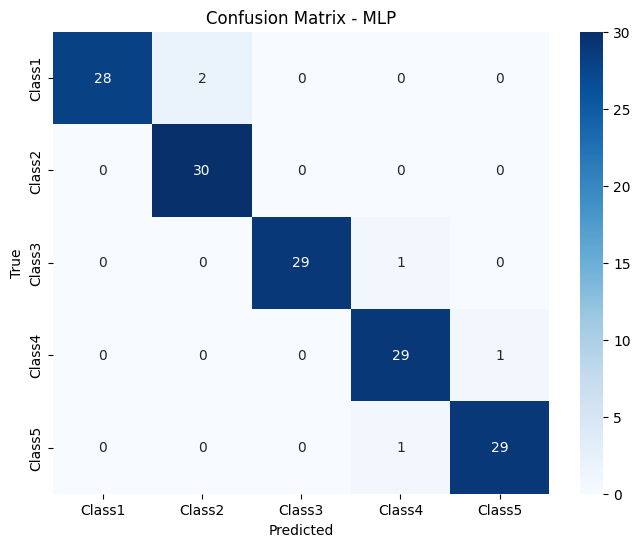

In [ ]:
doClassif(flatten_segmented_combined_dataset_df, 700, 8, 0.3)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,SVM (RBF),0.933333,0.936888,0.933333,0.933409
5,MLP,0.933333,0.933876,0.933333,0.933079
6,KNN,0.893333,0.901795,0.893333,0.893689
3,XGBoost,0.873333,0.873500,0.873333,0.872550
1,Random Forest,0.860000,0.863239,0.860000,0.859808
4,Logistic Regression,0.826667,0.836289,0.826667,0.825264
2,Decision Tree,0.780000,0.785205,0.780000,0.781325


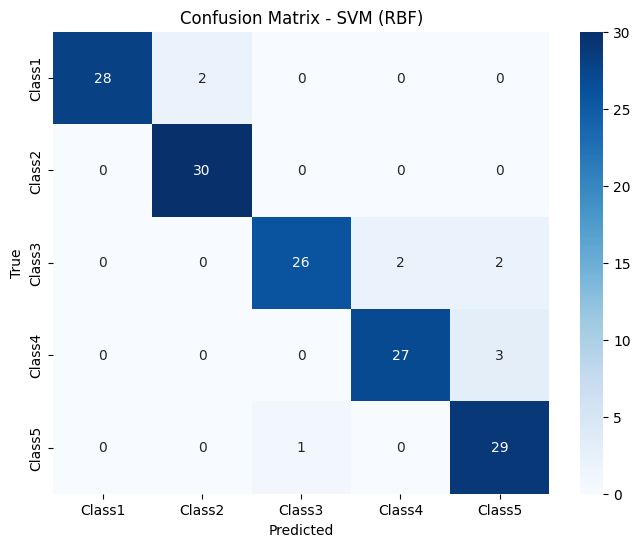

In [ ]:
doClassif(flatten_segmented_combined_denoised_dataset_df, 700, 8, 0.3)

## Feature Extraction W/O WINDOWING

In [ ]:
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import welch
import pywt

# ===============================
#  HAND-CRAFTED FEATURE EXTRACTOR
# ===============================

def extract_handcrafted_features(X, fs=1.0, wavelet='db4', level=4):
    """
    X: numpy array shape (n_samples, n_timesteps, n_sensors)
    fs: sampling rate
    wavelet: wavelet name for CWT/DWT
    level: wavelet decomposition level

    return: features array shape (n_samples, n_features)
            and list of feature names
    """
    n_samples, n_timesteps, n_sensors = X.shape

    feature_list = []
    feature_names = []

    # ====================================
    #  Helper function for band power
    # ====================================
    def calc_band_power(x, fs):
        freqs, psd = welch(x, fs=fs, nperseg=10)
        total_power = np.trapezoid(psd, freqs)
        return total_power

    # ====================================
    # Extract features per sample
    # ====================================
    for i in range(n_samples):
        sample_feats = []
        data = X[i]      # shape (timesteps, sensors)

        for s in range(n_sensors):
            x = data[:, s]

            # ---------------------------
            # TIME-DOMAIN FEATURES
            # ---------------------------
            mean_x = np.mean(x)
            std_x = np.std(x)
            min_x = np.min(x)
            max_x = np.max(x)
            range_x = np.max(x) - np.min(x)
            pctl25_x = np.percentile(x, 25)
            pctl75 = np.percentile(x, 75)
            pctl50 = np.percentile(x, 50)
            rms_x = np.sqrt(np.mean(x**2))
            skew_x = skew(x)
            kurt_x = kurtosis(x)
            slope_x = (x[-1] - x[0]) / n_timesteps
            auc_x = np.trapezoid(x)

            # ---------------------------
            # FREQUENCY-DOMAIN FEATURES
            # ---------------------------
            fft_vals = np.abs(np.fft.rfft(x))
            fft_freq = np.fft.rfftfreq(len(x), d=1/fs)

            peak_freq = fft_freq[np.argmax(fft_vals)]
            centroid = np.sum(fft_freq * fft_vals) / np.sum(fft_vals + 1e-8)

            # spectral entropy
            psd = fft_vals ** 2
            psd_norm = psd / np.sum(psd + 1e-12)
            spec_entropy = -np.sum(psd_norm * np.log(psd_norm + 1e-12))

            # band power
            bp = calc_band_power(x, fs)

            # ---------------------------
            # WAVELET FEATURES
            # ---------------------------
            coeffs = pywt.wavedec(x, wavelet, level=level)
            wavelet_energy = [np.sum(c**2) for c in coeffs]

            # Append all features
            sample_feats.extend([
                mean_x, std_x, min_x, max_x, range_x, pctl25_x, pctl75, pctl50,
                rms_x, skew_x, kurt_x, slope_x, auc_x,
                peak_freq, centroid, spec_entropy, bp,
                *wavelet_energy
            ])

            # Generate names (once)
            if i == 0:
                feature_names.extend([
                    f"sensor{s}_mean",
                    f"sensor{s}_std",
                    f"sensor{s}_min",
                    f"sensor{s}_max",
                    f"sensor{s}_range",
                    f"sensor{s}_percentile_25",
                    f"sensor{s}_percentile_75",
                    f"sensor{s}_percentile_50",
                    f"sensor{s}_rms",
                    f"sensor{s}_skew",
                    f"sensor{s}_kurtosis",
                    f"sensor{s}_slope",
                    f"sensor{s}_auc",
                    f"sensor{s}_fft_peakfreq",
                    f"sensor{s}_spec_centroid",
                    f"sensor{s}_spec_entropy",
                    f"sensor{s}_bandpower",
                ] + [f"sensor{s}_wavelet_energy_L{j}" for j in range(len(coeffs))])

        # =============================
        # CROSS-SENSOR FEATURES
        # =============================
        for s1 in range(n_sensors):
            for s2 in range(s1 + 1, n_sensors):
                x1 = data[:, s1]
                x2 = data[:, s2]

                # Cross-correlation (lag 0)
                corr = np.corrcoef(x1, x2)[0, 1]

                # Difference energy
                diff_energy = np.sum((x1 - x2)**2)

                sample_feats.extend([corr, diff_energy])

                if i == 0:
                    feature_names.extend([
                        f"corr_s{s1}_s{s2}",
                        f"diff_energy_s{s1}_s{s2}"
                    ])

        feature_list.append(sample_feats)

    return np.array(feature_list), feature_names



### Statistics Routines

In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as stats
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from scipy.signal import stft

#########################################################################

#########################################################################

def calc_skewness(data):
    """
    Menghitung Sample Skewness (g1) secara manual menggunakan NumPy.

    Args:
        data (np.array atau list): Dataset input.

    Returns:
        float: Nilai Sample Skewness (g1).
    """

    # 1. Konversi ke array NumPy dan dapatkan ukuran (n)
    data = np.asarray(data)
    n = len(data)

    # Cek untuk memastikan ada cukup data (minimal 3)
    if n < 3:
        # Skewness tidak terdefinisi atau tidak dapat dihitung
        return np.nan

    # 2. Hitung Rata-rata (Mean)
    mean = np.mean(data)

    # 3. Hitung Deviasi dari Rata-rata
    deviations = data - mean

    # --- Hitung Momen ---

    # 4. Momen Pusat Ketiga (Numerator) - sum( (xi - mean)^3 )
    moment_3 = np.sum(deviations**3)

    # 5. Momen Pusat Kedua (Denominator) - sum( (xi - mean)^2 )
    moment_2 = np.sum(deviations**2) # Ini adalah (n-1) * Varians sampel

    # --- Terapkan Rumus Sample Skewness (g1) ---

    # Bagian 1: Bias Correction (Koreksi Sampel)
    # Koefisien untuk momen ketiga: n / ((n - 1) * (n - 2))
    bias_corr_M3 = n / ((n - 1) * (n - 2))

    # Bagian 2: Std Dev Sampel (s) dipangkatkan 3
    # Std dev sampel (s) = sqrt(moment_2 / (n - 1))
    # Std dev sampel (s)^3 = (moment_2 / (n - 1))^(3/2)
    std_dev_sample_cubed = (moment_2 / (n - 1))**1.5

    # 6. Hitung Skewness (g1)
    # Skewness = (bias_corr_M3 * moment_3) / std_dev_sample_cubed
    if std_dev_sample_cubed == 0:
        return 0.0 # Jika semua nilai sama, deviasi 0, skewness 0

    skewness_g1 = (bias_corr_M3 * moment_3) / std_dev_sample_cubed

    return skewness_g1


def calc_kurtosis(data, population=False):
    """
    Menghitung Excess Kurtosis secara manual menggunakan NumPy
    berdasarkan Momen Pusat Keempat.

    Args:
        data (np.array atau list): Dataset input.
        population (bool):
            - True: Menggunakan N (ukuran populasi) untuk normalisasi.
            - False: Menggunakan N-1 (varian sampel) untuk standar deviasi.

    Returns:
        float: Nilai Excess Kurtosis.
    """

    # 1. Konversi ke array NumPy dan dapatkan ukuran (n)
    data = np.asarray(data)
    n = len(data)

    # Cek untuk memastikan ada cukup data (minimal 4 untuk Sample Kurtosis, 1 untuk Momen)
    if n < 2:
        return np.nan

    # 2. Hitung Rata-rata (Mean)
    mean = np.mean(data)

    # 3. Hitung Deviasi dari Rata-rata
    deviations = data - mean

    # --- Hitung Momen Pusat Keempat (M4) ---

    # 4. Momen Pusat Keempat (sum( (xi - mean)^4 ))
    sum_dev_pow_4 = np.sum(deviations**4)

    # Momen Pusat Keempat (M4)
    M4 = sum_dev_pow_4 / n

    # --- Hitung Varians (s^2) ---

    # 5. Momen Pusat Kedua / Varians (sum( (xi - mean)^2 ))
    sum_dev_pow_2 = np.sum(deviations**2)

    if population:
        # Varians Populasi: dibagi N
        variance = sum_dev_pow_2 / n
    else:
        # Varians Sampel (Unbiased): dibagi N-1 (standard)
        variance = sum_dev_pow_2 / (n - 1)

    # Standard Deviasi Kuadrat (s^2) adalah Varians

    # --- Hitung Kurtosis ---

    if variance == 0:
        return 0.0 # Jika semua nilai sama, kurtosis 0

    # Kurtosis Baku = M4 / (Varians)^2
    kurtosis_baku = M4 / (variance**2)

    # Excess Kurtosis = Kurtosis Baku - 3
    excess_kurtosis = kurtosis_baku - 3

    return excess_kurtosis


# Statistical Parameter Feature Extraction for sinyal 2D
def extract_stats_features(signal_2d):
    features = {}

    # Loop for each sensor (columns)
    for i in range(signal_2d.shape[1]):
        sensor_data = signal_2d[:, i]  # pick ith sensor data
        features[f'sensor_{i}_mean'] = np.mean(sensor_data)
        features[f'sensor_{i}_median'] = np.median(sensor_data)
        features[f'sensor_{i}_min'] = np.min(sensor_data)
        features[f'sensor_{i}_max'] = np.max(sensor_data)
        features[f'sensor_{i}_range'] = np.max(sensor_data) - np.min(sensor_data)
        features[f'sensor_{i}_std'] = np.std(sensor_data)
        features[f'sensor_{i}_var'] = np.var(sensor_data)
        features[f'sensor_{i}_percentile_25'] = np.percentile(sensor_data, 25)
        features[f'sensor_{i}_percentile_75'] = np.percentile(sensor_data, 75)
        features[f'sensor_{i}_percentile_50'] = np.percentile(sensor_data, 50)
        features[f'sensor_{i}_skew'] = calc_skewness(sensor_data)
        features[f'sensor_{i}_kurtosis'] = calc_kurtosis(sensor_data)
        features[f'sensor_{i}_auc'] = np.trapezoid(sensor_data)  # area under curve
        features[f'sensor_{i}_nunique'] = pd.Series(sensor_data).nunique()

    return features

# STFT Feature Extractions
def extract_stft_features(signal_2d, fs=2, nperseg=100):
  combine_features = np.array([])

  # Loop for each sensor (column)
  for i in range(signal_2d.shape[1]):
    signal1D = signal_2d[:, i]  # pick ith sensor data
    f, t, Zxx = stft(signal1D, fs=fs, nperseg=nperseg)
    magnitude = np.abs(Zxx)  # evaluate magnitudo
    mean_features = np.mean(magnitude, axis=1)  # pick mean in each frequency
    var_features = np.var(magnitude, axis=1)  # pick variance in each frequency
    median_features = np.median(magnitude, axis=1)
    range_features = np.max(magnitude, axis=1) - np.min(magnitude, axis=1)
    percentile_features = np.percentile(magnitude, 25, axis=1) \
    + np.median(magnitude, axis=1) \
    + np.percentile(magnitude, 75, axis=1)
    #skewness_features = calc_skewness(magnitude)
    #kurtosis_features = calc_kurtosis(magnitude)

    #combine_features = np.concatenate([combine_features, mean_features, var_features])#, \
    combine_features = np.concatenate([combine_features, mean_features, var_features, median_features, range_features, percentile_features])#, \
                                       #median_features, range_features, percentile_features]), \
                                       #skewness_features, kurtosis_features])

  return combine_features # array_spectral_for_one_sample


# Wavelet feature extraction
from pywt import wavedec
def extract_wavelet_features(signal_2d, wavelet='db4', level=4):
  features = np.array([])

  # Loop for each sensor (column)
  for i in range(signal_2d.shape[1]):
    signal1D = signal_2d[:, i]  # pick ith sensor data
    coeffs = wavedec(signal1D, wavelet, level=level)

    # ---------------------------
    # WAVELET FEATURES
    # ---------------------------
    coeffs = pywt.wavedec(x, wavelet, level=level)
    wavelet_energy = [np.sum(c**2) for c in coeffs]

    # Append all features
    features = np.concatenate([features, *wavelet_energy])

  return features


## Feature Extraction with windowing

In [ ]:
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import welch
import pywt

# ==========================================
# HANDCRAFTED FEATURE EXTRACTOR + WINDOWING
# ==========================================

def extract_handcrafted_features_windowed(
    X,
    fs=1.0,
    window_sec=50,
    overlap_sec=0,
    wavelet='db4',
    level=1
):
    """
    X shape:
        (n_samples, n_timesteps, n_sensors)

    fs:
        sampling rate (Hz)

    window_sec:
        durasi window dalam detik

    overlap_sec:
        overlap antar window

    return:
        features -> shape (n_total_windows, n_features)
        feature_names
    """

    n_samples, n_timesteps, n_sensors = X.shape

    # ======================================
    # Convert seconds to timestep
    # ======================================
    window_size = int(window_sec * fs)
    overlap_size = int(overlap_sec * fs)

    step_size = window_size - overlap_size

    feature_list = []
    feature_names = []

    # ======================================
    # Helper: Band Power
    # ======================================
    def calc_band_power(x, fs):
        freqs, psd = welch(x, fs=fs, nperseg=10)
        total_power = np.trapezoid(psd, freqs)
        return total_power

    # ======================================
    # LOOP SAMPLE
    # ======================================
    for i in range(n_samples):

        data = X[i]   # (timesteps, sensors)

        # ==================================
        # WINDOWING
        # ==================================
        for start in range(0, n_timesteps - window_size + 1, step_size):

            end = start + window_size

            window_data = data[start:end, :]

            sample_feats = []

            # ==============================
            # PER SENSOR
            # ==============================
            for s in range(n_sensors):

                x = window_data[:, s]

                # --------------------------
                # TIME DOMAIN
                # --------------------------
                mean_x = np.mean(x)
                std_x = np.std(x)
                min_x = np.min(x)
                max_x = np.max(x)
                range_x = np.max(x) - np.min(x)
                pctl25_x = np.percentile(x, 25)
                pctl75_x = np.percentile(x, 75)
                pctl50_x = np.percentile(x, 50)
                rms_x = np.sqrt(np.mean(x**2))

                skew_x = calc_skewness(x)
                kurt_x = calc_kurtosis(x)

                slope_x = (x[-1] - x[0]) / len(x)
                auc_x = np.trapezoid(x)

                # --------------------------
                # FREQUENCY DOMAIN
                # --------------------------

                fft_vals = np.abs(np.fft.rfft(x))

                fft_freq = np.fft.rfftfreq(
                    len(x),
                    d=1/fs
                )

                peak_freq = fft_freq[np.argmax(fft_vals)]

                centroid = (
                    np.sum(fft_freq * fft_vals)
                    / (np.sum(fft_vals) + 1e-8)
                )

                # Spectral entropy
                psd = fft_vals**2

                psd_norm = psd / (np.sum(psd) + 1e-12)

                spec_entropy = -np.sum(
                    psd_norm * np.log(psd_norm + 1e-12)
                )

                # Bandpower
                bp = calc_band_power(x, fs)

                # --------------------------
                # WAVELET
                # --------------------------
                coeffs = pywt.wavedec(
                    x,
                    wavelet,
                    level=level
                )

                wavelet_energy = [
                    np.sum(c**2)
                    for c in coeffs
                ]


                # --------------------------
                # APPEND FEATURES
                # --------------------------
                sample_feats.extend([
                    mean_x,
                    std_x,
                    min_x,
                    max_x,
                    range_x,
                    pctl25_x,
                    pctl75_x,
                    pctl50_x,
                    rms_x,
                    skew_x,
                    kurt_x,
                    slope_x,
                    auc_x,
                    peak_freq,
                    centroid,
                    spec_entropy,
                    bp,
                    *wavelet_energy
                ])

                # Generate names once
                if i == 0 and start == 0:

                    feature_names.extend([
                        f"sensor{s}_mean",
                        f"sensor{s}_std",
                        f"sensor{s}_min",
                        f"sensor{s}_max",
                        f"sensor{s}_range",
                        f"sensor{s}_percentile_25",
                        f"sensor{s}_percentile_75",
                        f"sensor{s}_percentile_50",
                        f"sensor{s}_rms",
                        f"sensor{s}_skew",
                        f"sensor{s}_kurtosis",
                        f"sensor{s}_slope",
                        f"sensor{s}_auc",
                        f"sensor{s}_fft_peakfreq",
                        f"sensor{s}_spec_centroid",
                        f"sensor{s}_spec_entropy",
                        f"sensor{s}_bandpower",
                        ] + [f"sensor{s}_wavelet_energy_L{j}" for j in range(len(coeffs))
                    ])


            # ==============================
            # CROSS SENSOR FEATURES
            # ==============================
            for s1 in range(n_sensors):

                for s2 in range(s1 + 1, n_sensors):

                    x1 = window_data[:, s1]
                    x2 = window_data[:, s2]

                    corr = np.corrcoef(x1, x2)[0, 1]

                    diff_energy = np.sum(
                        (x1 - x2)**2
                    )

                    sample_feats.extend([
                        corr if not np.nan else 0,
                        diff_energy
                    ])

                    if i == 0 and start == 0:

                        feature_names.extend([
                            f"corr_s{s1}_s{s2}",
                            f"diff_energy_s{s1}_s{s2}"
                        ])


            feature_list.append(sample_feats)


    return np.array(feature_list), feature_names

## Break Down Feature Extraction based-on its domain

In [ ]:
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import welch
import pywt

# ==========================================
# HANDCRAFTED FEATURE EXTRACTOR Time-Domain
# ==========================================

def extract_handcrafted_features_t_domain(
    X,
    fs=1.0,
    window_sec=50,
    overlap_sec=0,
    wavelet='db4',
    level=1
):
    """
    X shape:
        (n_samples, n_timesteps, n_sensors)

    fs:
        sampling rate (Hz)

    window_sec:
        durasi window dalam detik

    overlap_sec:
        overlap antar window

    return:
        features -> shape (n_total_windows, n_features)
        feature_names
    """

    n_samples, n_timesteps, n_sensors = X.shape

    # ======================================
    # Convert seconds to timestep
    # ======================================
    window_size = int(window_sec * fs)
    overlap_size = int(overlap_sec * fs)

    step_size = window_size - overlap_size

    feature_list = []
    feature_names = []

    # ======================================
    # Helper: Band Power
    # ======================================
    def calc_band_power(x, fs):
        freqs, psd = welch(x, fs=fs, nperseg=10)
        total_power = np.trapezoid(psd, freqs)
        return total_power

    # ======================================
    # LOOP SAMPLE
    # ======================================
    for i in range(n_samples):

        data = X[i]   # (timesteps, sensors)

        # ==================================
        # WINDOWING
        # ==================================
        for start in range(0, n_timesteps - window_size + 1, step_size):

            end = start + window_size

            window_data = data[start:end, :]

            sample_feats = []

            # ==============================
            # PER SENSOR
            # ==============================
            for s in range(n_sensors):

                x = window_data[:, s]

                # --------------------------
                # TIME DOMAIN
                # --------------------------
                mean_x = np.mean(x)
                std_x = np.std(x)
                min_x = np.min(x)
                max_x = np.max(x)
                range_x = np.max(x) - np.min(x)
                pctl25_x = np.percentile(x, 25)
                pctl75_x = np.percentile(x, 75)
                pctl50_x = np.percentile(x, 50)
                rms_x = np.sqrt(np.mean(x**2))

                skew_x = calc_skewness(x)
                kurt_x = calc_kurtosis(x)

                slope_x = (x[-1] - x[0]) / len(x)
                auc_x = np.trapezoid(x)

                # --------------------------
                # FREQUENCY DOMAIN
                # --------------------------
                """
                fft_vals = np.abs(np.fft.rfft(x))

                fft_freq = np.fft.rfftfreq(
                    len(x),
                    d=1/fs
                )

                peak_freq = fft_freq[np.argmax(fft_vals)]

                centroid = (
                    np.sum(fft_freq * fft_vals)
                    / (np.sum(fft_vals) + 1e-8)
                )

                # Spectral entropy
                psd = fft_vals**2

                psd_norm = psd / (np.sum(psd) + 1e-12)

                spec_entropy = -np.sum(
                    psd_norm * np.log(psd_norm + 1e-12)
                )

                # Bandpower
                bp = calc_band_power(x, fs)

                # --------------------------
                # WAVELET
                # --------------------------
                coeffs = pywt.wavedec(
                    x,
                    wavelet,
                    level=level
                )

                wavelet_energy = [
                    np.sum(c**2)
                    for c in coeffs
                ]

                """
                # --------------------------
                # APPEND FEATURES
                # --------------------------
                sample_feats.extend([
                    mean_x,
                    std_x,
                    min_x,
                    max_x,
                    range_x,
                    pctl25_x,
                    pctl75_x,
                    pctl50_x,
                    rms_x,
                    skew_x,
                    kurt_x,
                    slope_x,
                    auc_x,
                    #peak_freq,
                    #centroid,
                    #spec_entropy,
                    #bp,
                    #*wavelet_energy
                ])

                # Generate names once
                if i == 0 and start == 0:

                    feature_names.extend([
                        f"sensor{s}_mean",
                        f"sensor{s}_std",
                        f"sensor{s}_min",
                        f"sensor{s}_max",
                        f"sensor{s}_range",
                        f"sensor{s}_percentile_25",
                        f"sensor{s}_percentile_75",
                        f"sensor{s}_percentile_50",
                        f"sensor{s}_rms",
                        f"sensor{s}_skew",
                        f"sensor{s}_kurtosis",
                        f"sensor{s}_slope",
                        f"sensor{s}_auc",
                        f"sensor{s}_fft_peakfreq",
                        f"sensor{s}_spec_centroid",
                        f"sensor{s}_spec_entropy",
                        f"sensor{s}_bandpower",
                        ] + [f"sensor{s}_wavelet_energy_L{j}" for j in range(len(coeffs))
                    ])

            """"
            # ==============================
            # CROSS SENSOR FEATURES
            # ==============================
            for s1 in range(n_sensors):

                for s2 in range(s1 + 1, n_sensors):

                    x1 = window_data[:, s1]
                    x2 = window_data[:, s2]

                    corr = np.corrcoef(x1, x2)[0, 1]

                    diff_energy = np.sum(
                        (x1 - x2)**2
                    )

                    sample_feats.extend([
                        corr if not np.nan else 0,
                        diff_energy
                    ])

                    if i == 0 and start == 0:

                        feature_names.extend([
                            f"corr_s{s1}_s{s2}",
                            f"diff_energy_s{s1}_s{s2}"
                        ])
            """

            feature_list.append(sample_feats)


    return np.array(feature_list), feature_names

In [ ]:
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import welch
import pywt

# ==========================================
# HANDCRAFTED FEATURE EXTRACTOR Freq Domain
# ==========================================

def extract_handcrafted_features_freq_domain(
    X,
    fs=1.0,
    window_sec=50,
    overlap_sec=0,
    wavelet='db4',
    level=1
):
    """
    X shape:
        (n_samples, n_timesteps, n_sensors)

    fs:
        sampling rate (Hz)

    window_sec:
        durasi window dalam detik

    overlap_sec:
        overlap antar window

    return:
        features -> shape (n_total_windows, n_features)
        feature_names
    """

    n_samples, n_timesteps, n_sensors = X.shape

    # ======================================
    # Convert seconds to timestep
    # ======================================
    window_size = int(window_sec * fs)
    overlap_size = int(overlap_sec * fs)

    step_size = window_size - overlap_size

    feature_list = []
    feature_names = []

    # ======================================
    # Helper: Band Power
    # ======================================
    def calc_band_power(x, fs):
        freqs, psd = welch(x, fs=fs, nperseg=10)
        total_power = np.trapezoid(psd, freqs)
        return total_power

    # ======================================
    # LOOP SAMPLE
    # ======================================
    for i in range(n_samples):

        data = X[i]   # (timesteps, sensors)

        # ==================================
        # WINDOWING
        # ==================================
        for start in range(0, n_timesteps - window_size + 1, step_size):

            end = start + window_size

            window_data = data[start:end, :]

            sample_feats = []

            # ==============================
            # PER SENSOR
            # ==============================
            for s in range(n_sensors):

                x = window_data[:, s]

                # --------------------------
                # TIME DOMAIN
                # --------------------------
                """
                mean_x = np.mean(x)
                std_x = np.std(x)
                min_x = np.min(x)
                max_x = np.max(x)
                range_x = np.max(x) - np.min(x)
                pctl25_x = np.percentile(x, 25)
                pctl75_x = np.percentile(x, 75)
                pctl50_x = np.percentile(x, 50)
                rms_x = np.sqrt(np.mean(x**2))

                skew_x = calc_skewness(x)
                kurt_x = calc_kurtosis(x)

                slope_x = (x[-1] - x[0]) / len(x)
                auc_x = np.trapezoid(x)
                """
                # --------------------------
                # FREQUENCY DOMAIN
                # --------------------------

                fft_vals = np.abs(np.fft.rfft(x))

                fft_freq = np.fft.rfftfreq(
                    len(x),
                    d=1/fs
                )

                peak_freq = fft_freq[np.argmax(fft_vals)]

                centroid = (
                    np.sum(fft_freq * fft_vals)
                    / (np.sum(fft_vals) + 1e-8)
                )

                # Spectral entropy
                psd = fft_vals**2

                psd_norm = psd / (np.sum(psd) + 1e-12)

                spec_entropy = -np.sum(
                    psd_norm * np.log(psd_norm + 1e-12)
                )

                # Bandpower
                bp = calc_band_power(x, fs)

                """
                # --------------------------
                # WAVELET
                # --------------------------
                coeffs = pywt.wavedec(
                    x,
                    wavelet,
                    level=level
                )

                wavelet_energy = [
                    np.sum(c**2)
                    for c in coeffs
                ]

                """
                # --------------------------
                # APPEND FEATURES
                # --------------------------
                sample_feats.extend([
                    #mean_x,
                    #std_x,
                    #min_x,
                    #max_x,
                    #range_x,
                    #pctl25_x,
                    #pctl75_x,
                    #pctl50_x,
                    #rms_x,
                    #skew_x,
                    #kurt_x,
                    #slope_x,
                    #auc_x,
                    peak_freq,
                    centroid,
                    spec_entropy,
                    bp,
                    #*wavelet_energy
                ])

                # Generate names once
                if i == 0 and start == 0:

                    feature_names.extend([
                        #f"sensor{s}_mean",
                        #f"sensor{s}_std",
                        #f"sensor{s}_min",
                        #f"sensor{s}_max",
                        #f"sensor{s}_range",
                        #f"sensor{s}_percentile_25",
                        #f"sensor{s}_percentile_75",
                        #f"sensor{s}_percentile_50",
                        #f"sensor{s}_rms",
                        #f"sensor{s}_skew",
                        #f"sensor{s}_kurtosis",
                        #f"sensor{s}_slope",
                        #f"sensor{s}_auc",
                        f"sensor{s}_fft_peakfreq",
                        f"sensor{s}_spec_centroid",
                        f"sensor{s}_spec_entropy",
                        f"sensor{s}_bandpower",
                        #] + [f"sensor{s}_wavelet_energy_L{j}" for j in range(len(coeffs))
                    ])

            """"
            # ==============================
            # CROSS SENSOR FEATURES
            # ==============================
            for s1 in range(n_sensors):

                for s2 in range(s1 + 1, n_sensors):

                    x1 = window_data[:, s1]
                    x2 = window_data[:, s2]

                    corr = np.corrcoef(x1, x2)[0, 1]

                    diff_energy = np.sum(
                        (x1 - x2)**2
                    )

                    sample_feats.extend([
                        corr if not np.nan else 0,
                        diff_energy
                    ])

                    if i == 0 and start == 0:

                        feature_names.extend([
                            f"corr_s{s1}_s{s2}",
                            f"diff_energy_s{s1}_s{s2}"
                        ])
            """

            feature_list.append(sample_feats)


    return np.array(feature_list), feature_names

In [ ]:
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import welch
import pywt

# =============================================
# HANDCRAFTED FEATURE EXTRACTOR Wavelet Domain
# =============================================

def extract_handcrafted_features_wavelet_domain(
    X,
    fs=1.0,
    window_sec=50,
    overlap_sec=0,
    wavelet='db4',
    level=1
):
    """
    X shape:
        (n_samples, n_timesteps, n_sensors)

    fs:
        sampling rate (Hz)

    window_sec:
        durasi window dalam detik

    overlap_sec:
        overlap antar window

    return:
        features -> shape (n_total_windows, n_features)
        feature_names
    """

    n_samples, n_timesteps, n_sensors = X.shape

    # ======================================
    # Convert seconds to timestep
    # ======================================
    window_size = int(window_sec * fs)
    overlap_size = int(overlap_sec * fs)

    step_size = window_size - overlap_size

    feature_list = []
    feature_names = []

    # ======================================
    # Helper: Band Power
    # ======================================
    def calc_band_power(x, fs):
        freqs, psd = welch(x, fs=fs, nperseg=10)
        total_power = np.trapezoid(psd, freqs)
        return total_power

    # ======================================
    # LOOP SAMPLE
    # ======================================
    for i in range(n_samples):

        data = X[i]   # (timesteps, sensors)

        # ==================================
        # WINDOWING
        # ==================================
        for start in range(0, n_timesteps - window_size + 1, step_size):

            end = start + window_size

            window_data = data[start:end, :]

            sample_feats = []

            # ==============================
            # PER SENSOR
            # ==============================
            for s in range(n_sensors):

                x = window_data[:, s]

                # --------------------------
                # TIME DOMAIN
                # --------------------------
                """
                mean_x = np.mean(x)
                std_x = np.std(x)
                min_x = np.min(x)
                max_x = np.max(x)
                range_x = np.max(x) - np.min(x)
                pctl25_x = np.percentile(x, 25)
                pctl75_x = np.percentile(x, 75)
                pctl50_x = np.percentile(x, 50)
                rms_x = np.sqrt(np.mean(x**2))

                skew_x = calc_skewness(x)
                kurt_x = calc_kurtosis(x)

                slope_x = (x[-1] - x[0]) / len(x)
                auc_x = np.trapezoid(x)

                # --------------------------
                # FREQUENCY DOMAIN
                # --------------------------

                fft_vals = np.abs(np.fft.rfft(x))

                fft_freq = np.fft.rfftfreq(
                    len(x),
                    d=1/fs
                )

                peak_freq = fft_freq[np.argmax(fft_vals)]

                centroid = (
                    np.sum(fft_freq * fft_vals)
                    / (np.sum(fft_vals) + 1e-8)
                )

                # Spectral entropy
                psd = fft_vals**2

                psd_norm = psd / (np.sum(psd) + 1e-12)

                spec_entropy = -np.sum(
                    psd_norm * np.log(psd_norm + 1e-12)
                )

                # Bandpower
                bp = calc_band_power(x, fs)

                """
                # --------------------------
                # WAVELET
                # --------------------------
                coeffs = pywt.wavedec(
                    x,
                    wavelet,
                    level=level
                )

                wavelet_energy = [
                    np.sum(c**2)
                    for c in coeffs
                ]


                # --------------------------
                # APPEND FEATURES
                # --------------------------
                sample_feats.extend([
                    #mean_x,
                    #std_x,
                    #min_x,
                    #max_x,
                    #range_x,
                    #pctl25_x,
                    #pctl75_x,
                    #pctl50_x,
                    #rms_x,
                    #skew_x,
                    #kurt_x,
                    #slope_x,
                    #auc_x,
                    #peak_freq,
                    #centroid,
                    #spec_entropy,
                    #bp,
                    *wavelet_energy
                ])

                # Generate names once
                if i == 0 and start == 0:

                    feature_names.extend([
                        #f"sensor{s}_mean",
                        #f"sensor{s}_std",
                        #f"sensor{s}_min",
                        #f"sensor{s}_max",
                        #f"sensor{s}_range",
                        #f"sensor{s}_percentile_25",
                        #f"sensor{s}_percentile_75",
                        #f"sensor{s}_percentile_50",
                        #f"sensor{s}_rms",
                        #f"sensor{s}_skew",
                        #f"sensor{s}_kurtosis",
                        #f"sensor{s}_slope",
                        #f"sensor{s}_auc",
                        #f"sensor{s}_fft_peakfreq",
                        #f"sensor{s}_spec_centroid",
                        #f"sensor{s}_spec_entropy",
                        #f"sensor{s}_bandpower",
                        ] + [f"sensor{s}_wavelet_energy_L{j}" for j in range(len(coeffs))
                    ])

            """"
            # ==============================
            # CROSS SENSOR FEATURES
            # ==============================
            for s1 in range(n_sensors):

                for s2 in range(s1 + 1, n_sensors):

                    x1 = window_data[:, s1]
                    x2 = window_data[:, s2]

                    corr = np.corrcoef(x1, x2)[0, 1]

                    diff_energy = np.sum(
                        (x1 - x2)**2
                    )

                    sample_feats.extend([
                        corr if not np.nan else 0,
                        diff_energy
                    ])

                    if i == 0 and start == 0:

                        feature_names.extend([
                            f"corr_s{s1}_s{s2}",
                            f"diff_energy_s{s1}_s{s2}"
                        ])
            """

            feature_list.append(sample_feats)


    return np.array(feature_list), feature_names

In [ ]:
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.signal import welch
import pywt

# ==================================================
# HANDCRAFTED FEATURE EXTRACTOR Cross Sensor Domain
# ==================================================

def extract_handcrafted_features_cross_sensor(
    X,
    fs=1.0,
    window_sec=50,
    overlap_sec=0,
    wavelet='db4',
    level=4
):
    """
    X shape:
        (n_samples, n_timesteps, n_sensors)

    fs:
        sampling rate (Hz)

    window_sec:
        durasi window dalam detik

    overlap_sec:
        overlap antar window

    return:
        features -> shape (n_total_windows, n_features)
        feature_names
    """

    n_samples, n_timesteps, n_sensors = X.shape

    # ======================================
    # Convert seconds to timestep
    # ======================================
    window_size = int(window_sec * fs)
    overlap_size = int(overlap_sec * fs)

    step_size = window_size - overlap_size

    feature_list = []
    feature_names = []

    # ======================================
    # Helper: Band Power
    # ======================================
    def calc_band_power(x, fs):
        freqs, psd = welch(x, fs=fs, nperseg=10)
        total_power = np.trapezoid(psd, freqs)
        return total_power

    # ======================================
    # LOOP SAMPLE
    # ======================================
    for i in range(n_samples):

        data = X[i]   # (timesteps, sensors)

        # ==================================
        # WINDOWING
        # ==================================
        for start in range(0, n_timesteps - window_size + 1, step_size):

            end = start + window_size

            window_data = data[start:end, :]

            sample_feats = []

            # ==============================
            # PER SENSOR
            # ==============================
            for s in range(n_sensors):

                x = window_data[:, s]

                # --------------------------
                # TIME DOMAIN
                # --------------------------
                """
                mean_x = np.mean(x)
                std_x = np.std(x)
                min_x = np.min(x)
                max_x = np.max(x)
                range_x = np.max(x) - np.min(x)
                pctl25_x = np.percentile(x, 25)
                pctl75_x = np.percentile(x, 75)
                pctl50_x = np.percentile(x, 50)
                rms_x = np.sqrt(np.mean(x**2))

                skew_x = calc_skewness(x)
                kurt_x = calc_kurtosis(x)

                slope_x = (x[-1] - x[0]) / len(x)
                auc_x = np.trapezoid(x)

                # --------------------------
                # FREQUENCY DOMAIN
                # --------------------------

                fft_vals = np.abs(np.fft.rfft(x))

                fft_freq = np.fft.rfftfreq(
                    len(x),
                    d=1/fs
                )

                peak_freq = fft_freq[np.argmax(fft_vals)]

                centroid = (
                    np.sum(fft_freq * fft_vals)
                    / (np.sum(fft_vals) + 1e-8)
                )

                # Spectral entropy
                psd = fft_vals**2

                psd_norm = psd / (np.sum(psd) + 1e-12)

                spec_entropy = -np.sum(
                    psd_norm * np.log(psd_norm + 1e-12)
                )

                # Bandpower
                bp = calc_band_power(x, fs)


                # --------------------------
                # WAVELET
                # --------------------------
                coeffs = pywt.wavedec(
                    x,
                    wavelet,
                    level=level
                )

                wavelet_energy = [
                    np.sum(c**2)
                    for c in coeffs
                ]


                # --------------------------
                # APPEND FEATURES
                # --------------------------
                sample_feats.extend([
                    #mean_x,
                    #std_x,
                    #min_x,
                    #max_x,
                    #range_x,
                    #pctl25_x,
                    #pctl75_x,
                    #pctl50_x,
                    #rms_x,
                    #skew_x,
                    #kurt_x,
                    #slope_x,
                    #auc_x,
                    #peak_freq,
                    #centroid,
                    #spec_entropy,
                    #bp,
                    *wavelet_energy
                ])

                # Generate names once
                if i == 0 and start == 0:

                    feature_names.extend([
                        #f"sensor{s}_mean",
                        #f"sensor{s}_std",
                        #f"sensor{s}_min",
                        #f"sensor{s}_max",
                        #f"sensor{s}_range",
                        #f"sensor{s}_percentile_25",
                        #f"sensor{s}_percentile_75",
                        #f"sensor{s}_percentile_50",
                        #f"sensor{s}_rms",
                        #f"sensor{s}_skew",
                        #f"sensor{s}_kurtosis",
                        #f"sensor{s}_slope",
                        #f"sensor{s}_auc",
                        #f"sensor{s}_fft_peakfreq",
                        #f"sensor{s}_spec_centroid",
                        #f"sensor{s}_spec_entropy",
                        #f"sensor{s}_bandpower",
                        ] + [f"sensor{s}_wavelet_energy_L{j}" for j in range(len(coeffs))
                    ])
                    """

            # ==============================
            # CROSS SENSOR FEATURES
            # ==============================
            for s1 in range(n_sensors):

                for s2 in range(s1 + 1, n_sensors):

                    x1 = window_data[:, s1]
                    x2 = window_data[:, s2]

                    corr = np.corrcoef(x1, x2)[0, 1]

                    diff_energy = np.sum(
                        (x1 - x2)**2
                    )

                    sample_feats.extend([
                        corr if not np.nan else 0,
                        diff_energy
                    ])

                    if i == 0 and start == 0:

                        feature_names.extend([
                            f"corr_s{s1}_s{s2}",
                            f"diff_energy_s{s1}_s{s2}"
                        ])


            feature_list.append(sample_feats)


    return np.array(feature_list), feature_names

### Windowing W/O Overlapping (Remove)

In [ ]:
#============= Statistical Feature Extractions Calculation for each samples: ==============#

# 1. transient dataset
stats_feature_list_t = [extract_stats_features(segmented_transient_dataset[i]) for i in range(segmented_transient_dataset.shape[0])]
stats_feature_extraction_df_t = pd.DataFrame(stats_feature_list_t)

# 2. steady dataset
stats_feature_list_st = [extract_stats_features(segmented_steady_dataset[i]) for i in range(segmented_steady_dataset.shape[0])]
stats_feature_extraction_df_st = pd.DataFrame(stats_feature_list_st)

# 3. after steady dataset
stats_feature_list_ast = [extract_stats_features(segmented_after_steady_dataset[i]) for i in range(segmented_after_steady_dataset.shape[0])]
stats_feature_extraction_df_ast = pd.DataFrame(stats_feature_list_ast)

# 4. combined dataset
stats_feature_list_comb = [extract_stats_features(segmented_combined_dataset[i]) for i in range(segmented_combined_dataset.shape[0])]
stats_feature_extraction_df_comb = pd.DataFrame(stats_feature_list_comb)



#============= Spectral Feature Extractions Calculation for each samples: ==============#

# 1. transient dataset
stft_features_t = [extract_stft_features(segmented_transient_dataset[i], fs=2, nperseg=50) for i in range(segmented_transient_dataset.shape[0])]
stft_features_df_t = pd.DataFrame(stft_features_t)

# 2. steady dataset
stft_features_st = [extract_stft_features(segmented_steady_dataset[i], fs=2, nperseg=50) for i in range(segmented_steady_dataset.shape[0])]
stft_features_df_st = pd.DataFrame(stft_features_st)

# 3. after steady dataset
stft_features_ast = [extract_stft_features(segmented_after_steady_dataset[i], fs=2, nperseg=50) for i in range(segmented_after_steady_dataset.shape[0])]
stft_features_df_ast = pd.DataFrame(stft_features_ast)

# 4. combined dataset
stft_features_comb = [extract_stft_features(segmented_combined_dataset[i], fs=2, nperseg=50) for i in range(segmented_combined_dataset.shape[0])]
stft_features_df_comb = pd.DataFrame(stft_features_comb)



## FEATURE EXTRACTION PROCEDURES

In [ ]:
# Compare all Model
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from xgboost import XGBClassifier
import pandas as pd

### Test Break-Down Feature Extraction Routines

In [ ]:
def doClassification_t_domain(Dataset, rows_number, cols_number, t_size):
    all_feature_extractions_with_orig_data_df = pd.concat([Dataset.iloc[:,:-1]], axis=1, ignore_index=True)
    # flatten_df, stft_features_df, stats_feature_extraction_df, denoised_flatten_df, denoised_stft_features_df, denoised_stats_feature_extraction_df, sliding_features, fft_features

    # Split data to train & test set
    _X_train00, _X_test00, _y_train00, _y_test00 = train_test_split(
        all_feature_extractions_with_orig_data_df, Dataset['Grade'] - 1, test_size=t_size, random_state=42, stratify=Dataset['Grade'] - 1
    )

    ## ===== Procedure to do Feature Extraction ===== ##

    seg_X_train00 = _X_train00.values.reshape(-1, rows_number, cols_number)
    seg_X_train00 = seg_X_train00.astype(np.float64)

    seg_X_test00 = _X_test00.values.reshape(-1, rows_number, cols_number)
    seg_X_test00 = seg_X_test00.astype(np.float64)

    X_train_Feat_T = extract_handcrafted_features_t_domain(seg_X_train00, window_sec=50, level=1, overlap_sec=0)
    X_test_Feat_T = extract_handcrafted_features_t_domain(seg_X_test00, window_sec=50, level=1, overlap_sec=0)

    grade_list_train = _y_train00
    grade_list_test = _y_test00

    n = int(X_train_Feat_T[0].shape[0]/seg_X_train00.shape[0])  # duplicate each item

    _y_train00_dup = []
    _y_test00_dup = []

    for item in grade_list_train:
        _y_train00_dup.extend([item] * n)

    for item in grade_list_test:
        _y_test00_dup.extend([item] * n)

    ## ============== End Of Feat Extraction ============== ##

    # Standardize the data (scaling)
    scaler = StandardScaler()

    _X_train00 = scaler.fit_transform(X_train_Feat_T[0])
    _X_test00 = scaler.transform(X_test_Feat_T[0])

    _y_train00 = _y_train00_dup
    _y_test00 = _y_test00_dup

    # Train a Support Vector Machine (SVM) classifier

    list_models = {
        "SVM (RBF)": SVC(kernel='rbf', C=2.5, gamma='scale', random_state=42),

        "Random Forest": RandomForestClassifier(
            n_estimators=200, max_depth=None, random_state=42
        ),

        #"Decision Tree": DecisionTreeClassifier(
        #    max_depth=None, random_state=42
        #),

        "XGBoost": XGBClassifier(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric='mlogloss'
        ),

        #"Logistic Regression": LogisticRegression(
        #    max_iter=1000, random_state=42
        #),

        "MLP": MLPClassifier(
            hidden_layer_sizes=(200,),
            max_iter=500,
            random_state=42
        ),

        #"KNN": KNeighborsClassifier(
        #    n_neighbors=7
        #),

        #"NAIVE BAYES": NaiveBayesClassifier()
    }

    results = []

    for model_name, model in list_models.items():
        model.fit(_X_train00, _y_train00)
        y_pred = model.predict(_X_test00)

        results.append({
            "Model": model_name,
            "Accuracy": accuracy_score(_y_test00, y_pred),
            "Precision (Macro)": precision_score(_y_test00, y_pred, average='macro'),
            "Recall (Macro)": recall_score(_y_test00, y_pred, average='macro'),
            "F1-score (Macro)": f1_score(_y_test00, y_pred, average='macro')
        })

    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(by="F1-score (Macro)", ascending=False)

    display(results_df)

    best_model_name = results_df.iloc[0]["Model"]
    best_model = list_models[best_model_name]

    y_best_pred = best_model.predict(_X_test00)

    conf_mat = confusion_matrix(_y_test00, y_best_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
                xticklabels=["Class1","Class2","Class3","Class4","Class5"],
                yticklabels=["Class1","Class2","Class3","Class4","Class5"])
    plt.title(f"Confusion Matrix - {best_model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

In [ ]:
def doClassification_freq_domain(Dataset, rows_number, cols_number, t_size):
    all_feature_extractions_with_orig_data_df = pd.concat([Dataset.iloc[:,:-1]], axis=1, ignore_index=True)
    # flatten_df, stft_features_df, stats_feature_extraction_df, denoised_flatten_df, denoised_stft_features_df, denoised_stats_feature_extraction_df, sliding_features, fft_features

    # Split data to train & test set
    _X_train00, _X_test00, _y_train00, _y_test00 = train_test_split(
        all_feature_extractions_with_orig_data_df, Dataset['Grade'] - 1, test_size=t_size, random_state=42, stratify=Dataset['Grade'] - 1
    )

    ## ===== Procedure to do Feature Extraction ===== ##

    seg_X_train00 = _X_train00.values.reshape(-1, rows_number, cols_number)
    seg_X_train00 = seg_X_train00.astype(np.float64)

    seg_X_test00 = _X_test00.values.reshape(-1, rows_number, cols_number)
    seg_X_test00 = seg_X_test00.astype(np.float64)

    X_train_Feat_T = extract_handcrafted_features_freq_domain(seg_X_train00, window_sec=50, level=1, overlap_sec=0)
    X_test_Feat_T = extract_handcrafted_features_freq_domain(seg_X_test00, window_sec=50, level=1, overlap_sec=0)

    grade_list_train = _y_train00
    grade_list_test = _y_test00

    n = int(X_train_Feat_T[0].shape[0]/seg_X_train00.shape[0])  # duplicate each item

    _y_train00_dup = []
    _y_test00_dup = []

    for item in grade_list_train:
        _y_train00_dup.extend([item] * n)

    for item in grade_list_test:
        _y_test00_dup.extend([item] * n)

    ## ============== End Of Feat Extraction ============== ##

    # Standardize the data (scaling)
    scaler = StandardScaler()

    _X_train00 = scaler.fit_transform(X_train_Feat_T[0])
    _X_test00 = scaler.transform(X_test_Feat_T[0])

    _y_train00 = _y_train00_dup
    _y_test00 = _y_test00_dup

    # Train a Support Vector Machine (SVM) classifier

    list_models = {
        "SVM (RBF)": SVC(kernel='rbf', C=2.5, gamma='scale', random_state=42),

        "Random Forest": RandomForestClassifier(
            n_estimators=200, max_depth=None, random_state=42
        ),

        #"Decision Tree": DecisionTreeClassifier(
        #    max_depth=None, random_state=42
        #),

        "XGBoost": XGBClassifier(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric='mlogloss'
        ),

        #"Logistic Regression": LogisticRegression(
        #    max_iter=1000, random_state=42
        #),

        "MLP": MLPClassifier(
            hidden_layer_sizes=(200,),
            max_iter=500,
            random_state=42
        ),

        #"KNN": KNeighborsClassifier(
        #    n_neighbors=7
        #),

        #"NAIVE BAYES": NaiveBayesClassifier()
    }

    results = []

    for model_name, model in list_models.items():
        model.fit(_X_train00, _y_train00)
        y_pred = model.predict(_X_test00)

        results.append({
            "Model": model_name,
            "Accuracy": accuracy_score(_y_test00, y_pred),
            "Precision (Macro)": precision_score(_y_test00, y_pred, average='macro'),
            "Recall (Macro)": recall_score(_y_test00, y_pred, average='macro'),
            "F1-score (Macro)": f1_score(_y_test00, y_pred, average='macro')
        })

    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(by="F1-score (Macro)", ascending=False)

    display(results_df)

    best_model_name = results_df.iloc[0]["Model"]
    best_model = list_models[best_model_name]

    y_best_pred = best_model.predict(_X_test00)

    conf_mat = confusion_matrix(_y_test00, y_best_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
                xticklabels=["Class1","Class2","Class3","Class4","Class5"],
                yticklabels=["Class1","Class2","Class3","Class4","Class5"])
    plt.title(f"Confusion Matrix - {best_model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

In [ ]:
def doClassification_wavelet_domain(Dataset, rows_number, cols_number, t_size):
    all_feature_extractions_with_orig_data_df = pd.concat([Dataset.iloc[:,:-1]], axis=1, ignore_index=True)
    # flatten_df, stft_features_df, stats_feature_extraction_df, denoised_flatten_df, denoised_stft_features_df, denoised_stats_feature_extraction_df, sliding_features, fft_features

    # Split data to train & test set
    _X_train00, _X_test00, _y_train00, _y_test00 = train_test_split(
        all_feature_extractions_with_orig_data_df, Dataset['Grade'] - 1, test_size=t_size, random_state=42, stratify=Dataset['Grade'] - 1
    )

    ## ===== Procedure to do Feature Extraction ===== ##

    seg_X_train00 = _X_train00.values.reshape(-1, rows_number, cols_number)
    seg_X_train00 = seg_X_train00.astype(np.float64)

    seg_X_test00 = _X_test00.values.reshape(-1, rows_number, cols_number)
    seg_X_test00 = seg_X_test00.astype(np.float64)

    X_train_Feat_T = extract_handcrafted_features_wavelet_domain(seg_X_train00, window_sec=50, level=1, overlap_sec=0)
    X_test_Feat_T = extract_handcrafted_features_wavelet_domain(seg_X_test00, window_sec=50, level=1, overlap_sec=0)

    grade_list_train = _y_train00
    grade_list_test = _y_test00

    n = int(X_train_Feat_T[0].shape[0]/seg_X_train00.shape[0])  # duplicate each item

    _y_train00_dup = []
    _y_test00_dup = []

    for item in grade_list_train:
        _y_train00_dup.extend([item] * n)

    for item in grade_list_test:
        _y_test00_dup.extend([item] * n)

    ## ============== End Of Feat Extraction ============== ##

    # Standardize the data (scaling)
    scaler = StandardScaler()

    _X_train00 = scaler.fit_transform(X_train_Feat_T[0])
    _X_test00 = scaler.transform(X_test_Feat_T[0])

    _y_train00 = _y_train00_dup
    _y_test00 = _y_test00_dup

    # Train a Support Vector Machine (SVM) classifier

    list_models = {
        "SVM (RBF)": SVC(kernel='rbf', C=2.5, gamma='scale', random_state=42),

        "Random Forest": RandomForestClassifier(
            n_estimators=200, max_depth=None, random_state=42
        ),

        #"Decision Tree": DecisionTreeClassifier(
        #    max_depth=None, random_state=42
        #),

        "XGBoost": XGBClassifier(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric='mlogloss'
        ),

        #"Logistic Regression": LogisticRegression(
        #    max_iter=1000, random_state=42
        #),

        "MLP": MLPClassifier(
            hidden_layer_sizes=(200,),
            max_iter=500,
            random_state=42
        ),

        #"KNN": KNeighborsClassifier(
        #    n_neighbors=7
        #),

        #"NAIVE BAYES": NaiveBayesClassifier()
    }

    results = []

    for model_name, model in list_models.items():
        model.fit(_X_train00, _y_train00)
        y_pred = model.predict(_X_test00)

        results.append({
            "Model": model_name,
            "Accuracy": accuracy_score(_y_test00, y_pred),
            "Precision (Macro)": precision_score(_y_test00, y_pred, average='macro'),
            "Recall (Macro)": recall_score(_y_test00, y_pred, average='macro'),
            "F1-score (Macro)": f1_score(_y_test00, y_pred, average='macro')
        })

    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(by="F1-score (Macro)", ascending=False)

    display(results_df)

    best_model_name = results_df.iloc[0]["Model"]
    best_model = list_models[best_model_name]

    y_best_pred = best_model.predict(_X_test00)

    conf_mat = confusion_matrix(_y_test00, y_best_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
                xticklabels=["Class1","Class2","Class3","Class4","Class5"],
                yticklabels=["Class1","Class2","Class3","Class4","Class5"])
    plt.title(f"Confusion Matrix - {best_model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

In [ ]:
def doClassification_cross_sensors(Dataset, rows_number, cols_number, t_size):
    all_feature_extractions_with_orig_data_df = pd.concat([Dataset.iloc[:,:-1]], axis=1, ignore_index=True)
    # flatten_df, stft_features_df, stats_feature_extraction_df, denoised_flatten_df, denoised_stft_features_df, denoised_stats_feature_extraction_df, sliding_features, fft_features

    # Split data to train & test set
    _X_train00, _X_test00, _y_train00, _y_test00 = train_test_split(
        all_feature_extractions_with_orig_data_df, Dataset['Grade'] - 1, test_size=t_size, random_state=42, stratify=Dataset['Grade'] - 1
    )

    ## ===== Procedure to do Feature Extraction ===== ##

    seg_X_train00 = _X_train00.values.reshape(-1, rows_number, cols_number)
    seg_X_train00 = seg_X_train00.astype(np.float64)

    seg_X_test00 = _X_test00.values.reshape(-1, rows_number, cols_number)
    seg_X_test00 = seg_X_test00.astype(np.float64)

    X_train_Feat_T = extract_handcrafted_features_cross_sensor(seg_X_train00, window_sec=50, level=1, overlap_sec=0)
    X_test_Feat_T = extract_handcrafted_features_cross_sensor(seg_X_test00, window_sec=50, level=1, overlap_sec=0)

    grade_list_train = _y_train00
    grade_list_test = _y_test00

    n = int(X_train_Feat_T[0].shape[0]/seg_X_train00.shape[0])  # duplicate each item

    _y_train00_dup = []
    _y_test00_dup = []

    for item in grade_list_train:
        _y_train00_dup.extend([item] * n)

    for item in grade_list_test:
        _y_test00_dup.extend([item] * n)

    ## ============== End Of Feat Extraction ============== ##

    # Standardize the data (scaling)
    scaler = StandardScaler()

    _X_train00 = scaler.fit_transform(X_train_Feat_T[0])
    _X_test00 = scaler.transform(X_test_Feat_T[0])

    _y_train00 = _y_train00_dup
    _y_test00 = _y_test00_dup

    # Train a Support Vector Machine (SVM) classifier

    list_models = {
        "SVM (RBF)": SVC(kernel='rbf', C=2.5, gamma='scale', random_state=42),

        "Random Forest": RandomForestClassifier(
            n_estimators=200, max_depth=None, random_state=42
        ),

        #"Decision Tree": DecisionTreeClassifier(
        #    max_depth=None, random_state=42
        #),

        "XGBoost": XGBClassifier(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric='mlogloss'
        ),

        #"Logistic Regression": LogisticRegression(
        #    max_iter=1000, random_state=42
        #),

        "MLP": MLPClassifier(
            hidden_layer_sizes=(200,),
            max_iter=500,
            random_state=42
        ),

        #"KNN": KNeighborsClassifier(
        #    n_neighbors=7
        #),

        #"NAIVE BAYES": NaiveBayesClassifier()
    }

    results = []

    for model_name, model in list_models.items():
        model.fit(_X_train00, _y_train00)
        y_pred = model.predict(_X_test00)

        results.append({
            "Model": model_name,
            "Accuracy": accuracy_score(_y_test00, y_pred),
            "Precision (Macro)": precision_score(_y_test00, y_pred, average='macro'),
            "Recall (Macro)": recall_score(_y_test00, y_pred, average='macro'),
            "F1-score (Macro)": f1_score(_y_test00, y_pred, average='macro')
        })

    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(by="F1-score (Macro)", ascending=False)

    display(results_df)

    best_model_name = results_df.iloc[0]["Model"]
    best_model = list_models[best_model_name]

    y_best_pred = best_model.predict(_X_test00)

    conf_mat = confusion_matrix(_y_test00, y_best_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
                xticklabels=["Class1","Class2","Class3","Class4","Class5"],
                yticklabels=["Class1","Class2","Class3","Class4","Class5"])
    plt.title(f"Confusion Matrix - {best_model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

### Time Domain Feature Extraction

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
3,MLP,0.916667,0.917580,0.916667,0.916767
0,SVM (RBF),0.913333,0.914197,0.913333,0.912918
1,Random Forest,0.910000,0.911035,0.910000,0.909754
2,XGBoost,0.906667,0.907551,0.906667,0.906720


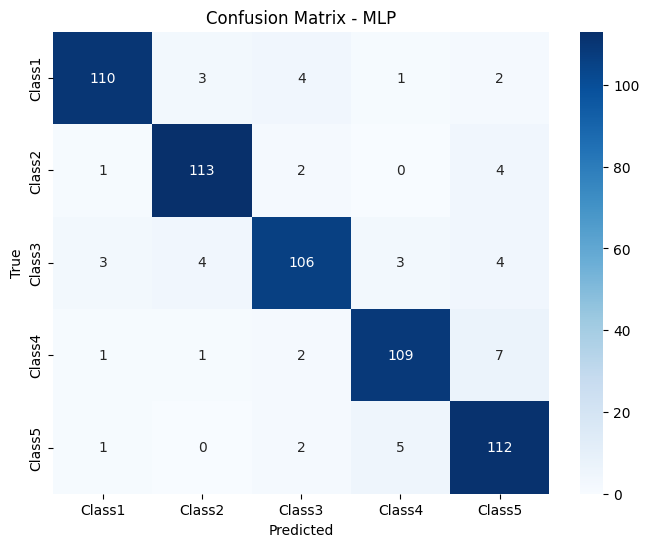

In [ ]:
doClassification_t_domain(flatten_segmented_transient_dataset_df, 200, 8, 0.3)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
3,MLP,0.954444,0.957197,0.954444,0.954708
0,SVM (RBF),0.921111,0.924486,0.921111,0.921010
2,XGBoost,0.907778,0.912039,0.907778,0.908596
1,Random Forest,0.898889,0.900892,0.898889,0.898943


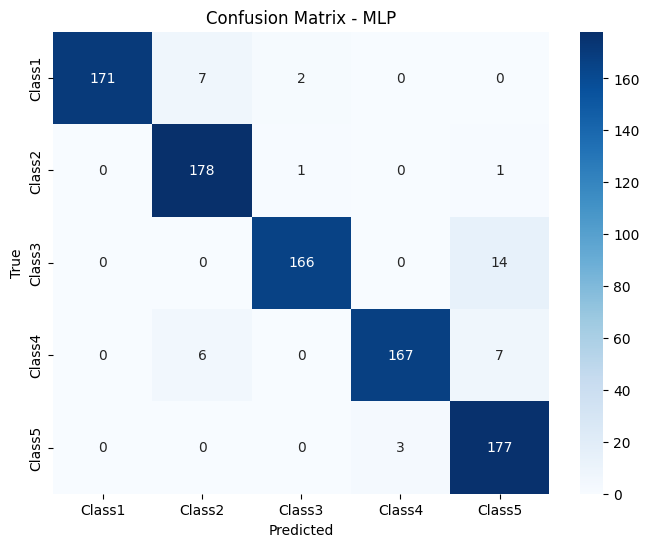

In [ ]:
doClassification_t_domain(flatten_segmented_steady_dataset_df, 300, 8, 0.3)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
3,MLP,0.941667,0.943194,0.941667,0.941286
0,SVM (RBF),0.931667,0.935274,0.931667,0.931590
2,XGBoost,0.903333,0.908557,0.903333,0.904278
1,Random Forest,0.888333,0.894007,0.888333,0.889640


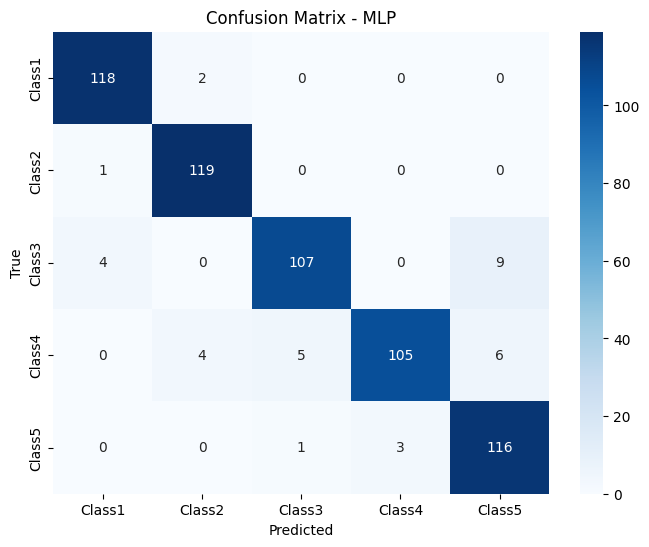

In [ ]:
doClassification_t_domain(flatten_segmented_after_steady_dataset_df, 200, 8, 0.3)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
3,MLP,0.949048,0.950359,0.949048,0.949210
0,SVM (RBF),0.937619,0.939272,0.937619,0.937684
1,Random Forest,0.920000,0.922267,0.920000,0.920055
2,XGBoost,0.920000,0.922034,0.920000,0.919882


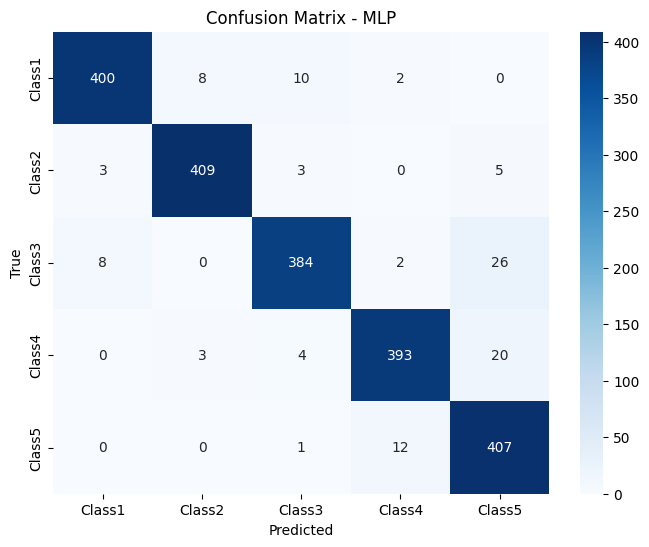

In [ ]:
doClassification_t_domain(flatten_segmented_combined_dataset_df, 700, 8, 0.3)

### Frequensi Domain Feature Extraction

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
2,XGBoost,0.716667,0.723490,0.716667,0.718510
1,Random Forest,0.678333,0.684273,0.678333,0.680311
3,MLP,0.675000,0.682147,0.675000,0.677576
0,SVM (RBF),0.551667,0.579111,0.551667,0.555336


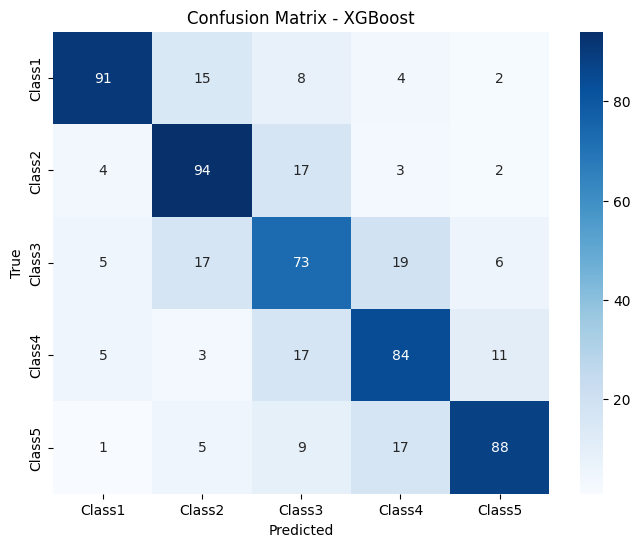

In [ ]:
doClassification_freq_domain(flatten_segmented_transient_dataset_df, 200, 8, 0.3)

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
2,XGBoost,0.762222,0.764509,0.762222,0.762670
1,Random Forest,0.713333,0.715196,0.713333,0.713576
3,MLP,0.637778,0.641742,0.637778,0.638288
0,SVM (RBF),0.563333,0.583009,0.563333,0.567299


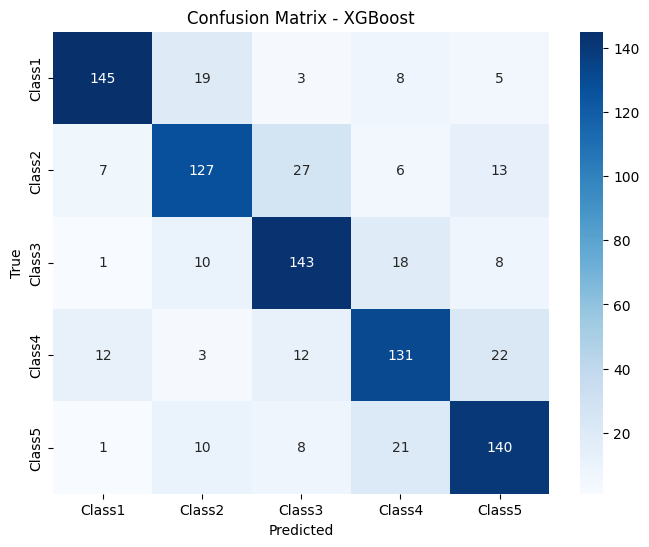

In [ ]:
doClassification_freq_domain(flatten_segmented_steady_dataset_df, 300, 8, 0.3)

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
2,XGBoost,0.683333,0.687448,0.683333,0.680048
1,Random Forest,0.606667,0.616548,0.606667,0.608145
3,MLP,0.593333,0.594602,0.593333,0.592439
0,SVM (RBF),0.515000,0.540727,0.515000,0.521654


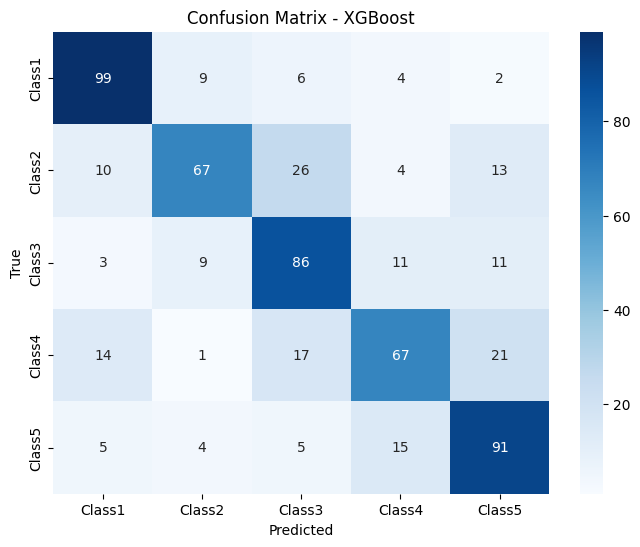

In [ ]:
doClassification_freq_domain(flatten_segmented_after_steady_dataset_df, 200, 8, 0.3)

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
2,XGBoost,0.737619,0.742270,0.737619,0.739175
1,Random Forest,0.669048,0.673661,0.669048,0.670589
3,MLP,0.626667,0.633339,0.626667,0.628005
0,SVM (RBF),0.543333,0.558741,0.543333,0.548194


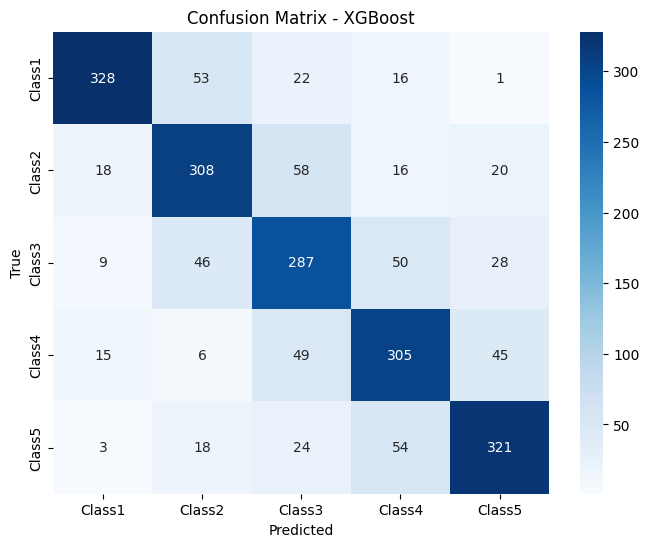

In [ ]:
doClassification_freq_domain(flatten_segmented_combined_dataset_df, 700, 8, 0.3)

### Wavelet Domain Feature Extraction

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
2,XGBoost,0.925,0.925474,0.925,0.924903
3,MLP,0.925,0.926557,0.925,0.924405
1,Random Forest,0.915,0.915269,0.915,0.914446
0,SVM (RBF),0.870,0.872769,0.870,0.869278


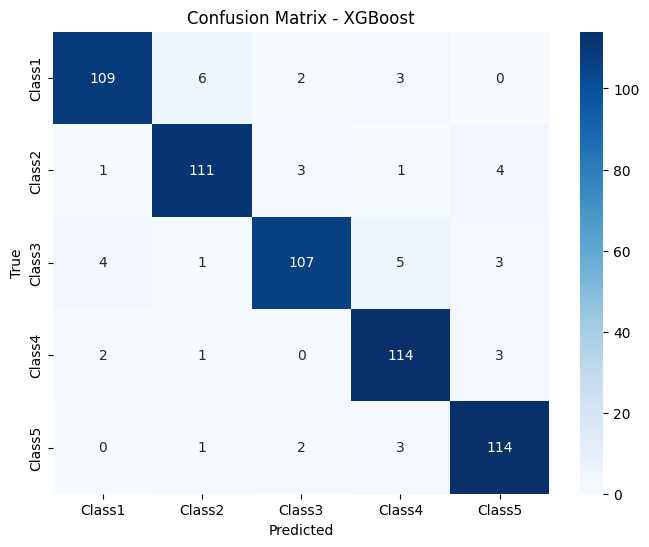

In [ ]:
doClassification_wavelet_domain(flatten_segmented_transient_dataset_df, 200, 8, 0.3)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
3,MLP,0.933333,0.936436,0.933333,0.933758
1,Random Forest,0.911111,0.913695,0.911111,0.910955
2,XGBoost,0.900000,0.904400,0.900000,0.900399
0,SVM (RBF),0.858889,0.864674,0.858889,0.858959


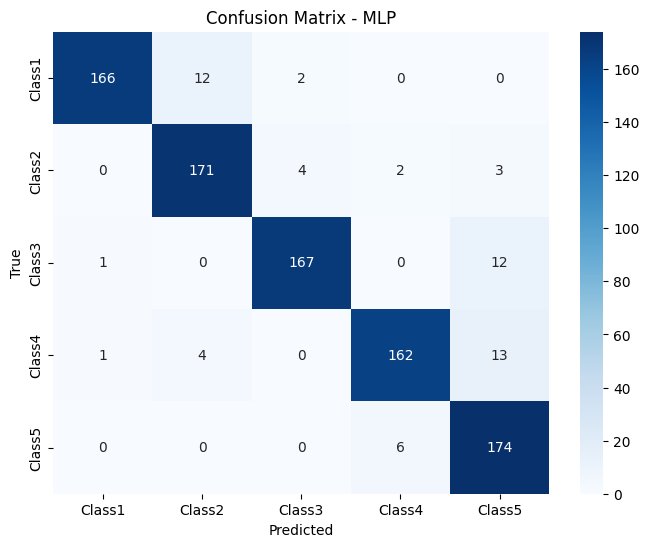

In [ ]:
doClassification_wavelet_domain(flatten_segmented_steady_dataset_df, 300, 8, 0.3)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
3,MLP,0.936667,0.938367,0.936667,0.936644
2,XGBoost,0.898333,0.903680,0.898333,0.898989
1,Random Forest,0.893333,0.900359,0.893333,0.894689
0,SVM (RBF),0.875000,0.876046,0.875000,0.874450


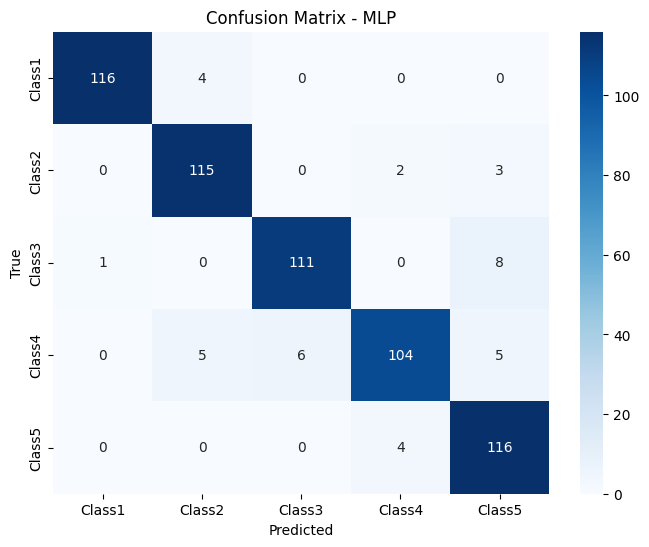

In [ ]:
doClassification_wavelet_domain(flatten_segmented_after_steady_dataset_df, 200, 8, 0.3)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
3,MLP,0.942381,0.943542,0.942381,0.942476
1,Random Forest,0.923810,0.926469,0.923810,0.923883
2,XGBoost,0.916667,0.919967,0.916667,0.916658
0,SVM (RBF),0.883810,0.886389,0.883810,0.883927


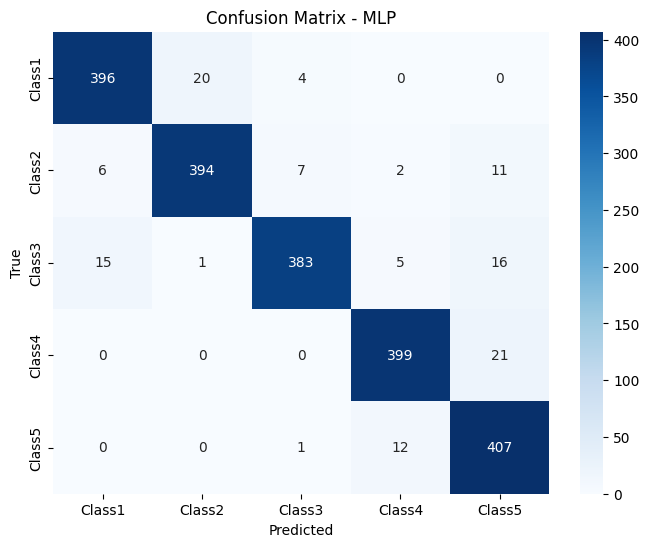

In [ ]:
doClassification_wavelet_domain(flatten_segmented_combined_dataset_df, 700, 8, 0.3)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
3,MLP,0.939524,0.942185,0.939524,0.939916
1,Random Forest,0.926190,0.928155,0.926190,0.926229
2,XGBoost,0.915238,0.918316,0.915238,0.915547
0,SVM (RBF),0.855714,0.859350,0.855714,0.855287


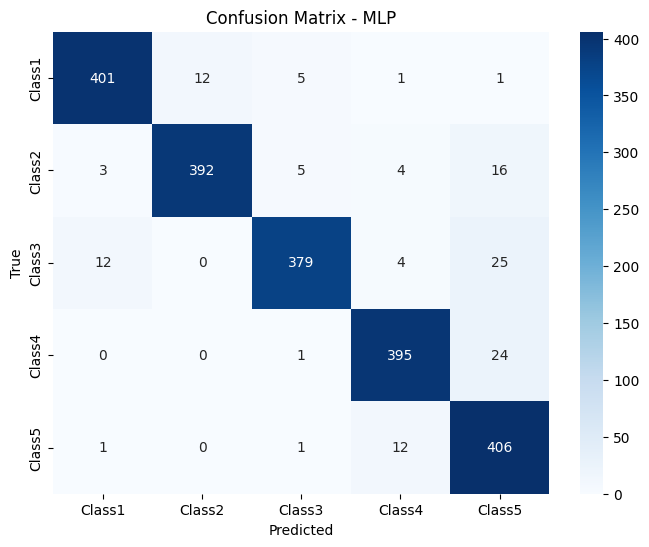

In [ ]:
doClassification_wavelet_domain(flatten_segmented_combined_denoised_dataset_df, 700, 8, 0.3)

### Cross-Sensor Feature Extraction

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
3,MLP,0.935000,0.935993,0.935000,0.935290
2,XGBoost,0.918333,0.920710,0.918333,0.918581
1,Random Forest,0.915000,0.916800,0.915000,0.915222
0,SVM (RBF),0.915000,0.916151,0.915000,0.914855


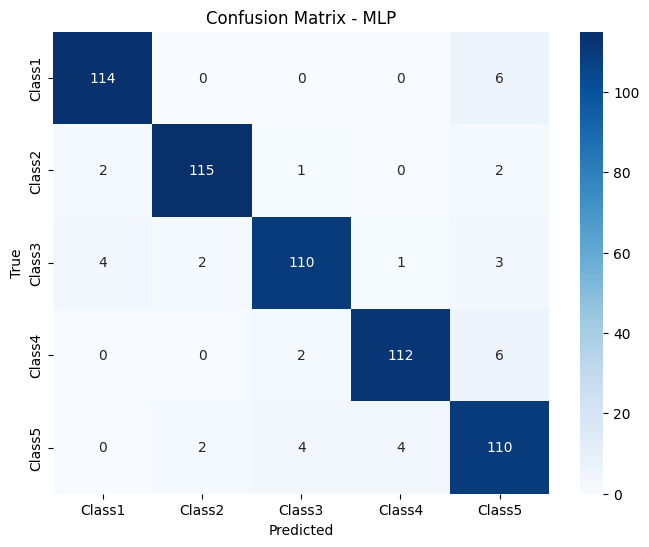

In [ ]:
doClassification_cross_sensors(flatten_segmented_transient_dataset_df, 200, 8, 0.3)

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,SVM (RBF),0.938889,0.941314,0.938889,0.939216
1,Random Forest,0.936667,0.939111,0.936667,0.936648
3,MLP,0.927778,0.930030,0.927778,0.927918
2,XGBoost,0.922222,0.923211,0.922222,0.922159


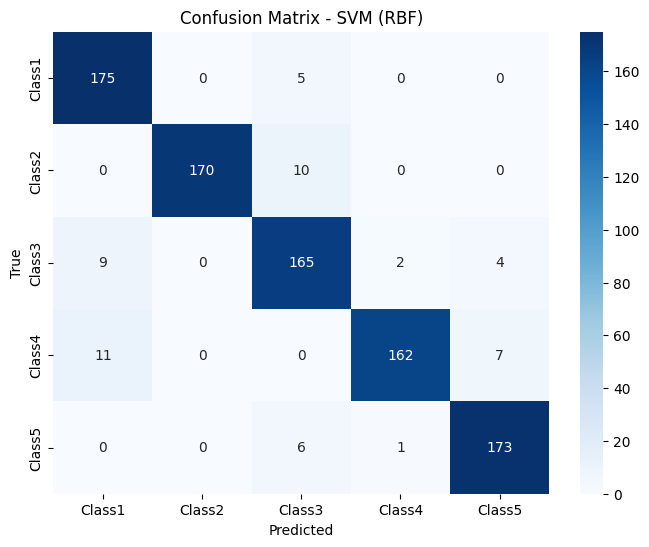

In [ ]:
doClassification_cross_sensors(flatten_segmented_steady_dataset_df, 300, 8, 0.3)

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,SVM (RBF),0.978333,0.979278,0.978333,0.978289
1,Random Forest,0.973333,0.974338,0.973333,0.973467
3,MLP,0.970000,0.971236,0.970000,0.969912
2,XGBoost,0.941667,0.943414,0.941667,0.941585


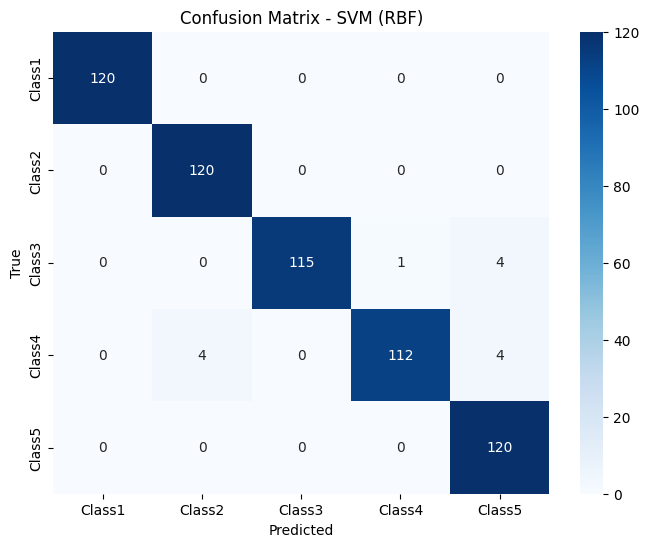

In [ ]:
doClassification_cross_sensors(flatten_segmented_after_steady_dataset_df, 200, 8, 0.3)

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
3,MLP,0.948095,0.948374,0.948095,0.948071
1,Random Forest,0.945238,0.945777,0.945238,0.945045
2,XGBoost,0.944286,0.944449,0.944286,0.944169
0,SVM (RBF),0.943333,0.945616,0.943333,0.943360


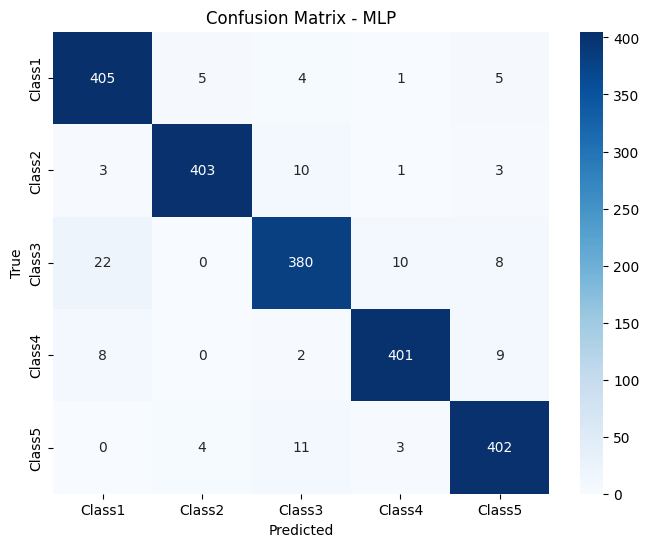

In [ ]:
doClassification_cross_sensors(flatten_segmented_combined_dataset_df, 700, 8, 0.3)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
1,Random Forest,0.949524,0.949776,0.949524,0.949375
3,MLP,0.949048,0.949313,0.949048,0.948989
0,SVM (RBF),0.942857,0.945097,0.942857,0.942892
2,XGBoost,0.940476,0.940638,0.940476,0.940381


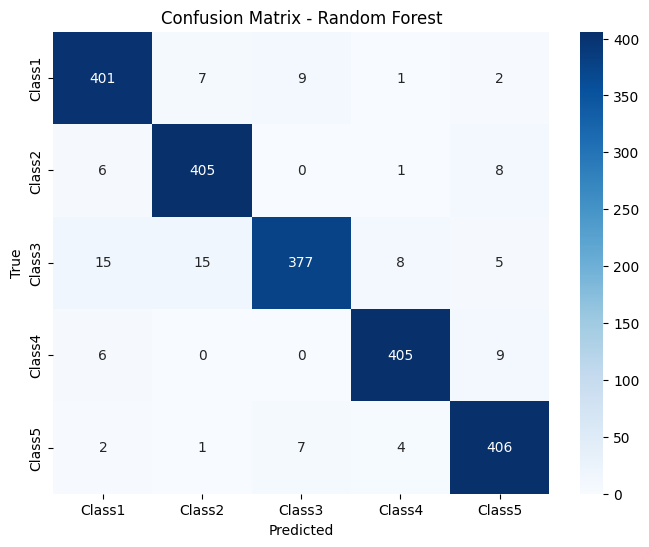

In [ ]:
doClassification_cross_sensors(flatten_segmented_combined_denoised_dataset_df, 700, 8, 0.3)

### Test Classif before Feature Selection

In [ ]:

def doClassification(Dataset, rows_number, cols_number, t_size):
    all_feature_extractions_with_orig_data_df = pd.concat([Dataset.iloc[:,:-1]], axis=1, ignore_index=True)
    # flatten_df, stft_features_df, stats_feature_extraction_df, denoised_flatten_df, denoised_stft_features_df, denoised_stats_feature_extraction_df, sliding_features, fft_features

    # Split data to train & test set
    _X_train00, _X_test00, _y_train00, _y_test00 = train_test_split(
        all_feature_extractions_with_orig_data_df, Dataset['Grade'] - 1, test_size=t_size, random_state=42, stratify=Dataset['Grade'] - 1
    )

    ## ===== Procedure to do Feature Extraction ===== ##

    seg_X_train00 = _X_train00.values.reshape(-1, rows_number, cols_number)
    seg_X_train00 = seg_X_train00.astype(np.float64)

    seg_X_test00 = _X_test00.values.reshape(-1, rows_number, cols_number)
    seg_X_test00 = seg_X_test00.astype(np.float64)

    X_train_Feat_T = extract_handcrafted_features_windowed(seg_X_train00, window_sec=50, level=1, overlap_sec=0)
    X_test_Feat_T = extract_handcrafted_features_windowed(seg_X_test00, window_sec=50, level=1, overlap_sec=0)

    grade_list_train = _y_train00
    grade_list_test = _y_test00

    n = int(X_train_Feat_T[0].shape[0]/seg_X_train00.shape[0])  # duplicate each item

    _y_train00_dup = []
    _y_test00_dup = []

    for item in grade_list_train:
        _y_train00_dup.extend([item] * n)

    for item in grade_list_test:
        _y_test00_dup.extend([item] * n)

    ## ============== End Of Feat Extraction ============== ##

    # Standardize the data (scaling)
    scaler = StandardScaler()

    _X_train00 = scaler.fit_transform(X_train_Feat_T[0])
    _X_test00 = scaler.transform(X_test_Feat_T[0])

    _y_train00 = _y_train00_dup
    _y_test00 = _y_test00_dup

    # Train a Support Vector Machine (SVM) classifier

    list_models = {
        "SVM (RBF)": SVC(kernel='rbf', C=2.5, gamma='scale', random_state=42),

        "Random Forest": RandomForestClassifier(
            n_estimators=200, max_depth=None, random_state=42
        ),

        "Decision Tree": DecisionTreeClassifier(
            max_depth=None, random_state=42
        ),

        "XGBoost": XGBClassifier(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric='mlogloss'
        ),

        "Logistic Regression": LogisticRegression(
            max_iter=1000, random_state=42
        ),

        "MLP": MLPClassifier(
            hidden_layer_sizes=(200,),
            max_iter=500,
            random_state=42
        ),

        "KNN": KNeighborsClassifier(
            n_neighbors=7
        ),

        #"NAIVE BAYES": NaiveBayesClassifier()
    }

    results = []

    for model_name, model in list_models.items():
        model.fit(_X_train00, _y_train00)
        y_pred = model.predict(_X_test00)

        results.append({
            "Model": model_name,
            "Accuracy": accuracy_score(_y_test00, y_pred),
            "Precision (Macro)": precision_score(_y_test00, y_pred, average='macro'),
            "Recall (Macro)": recall_score(_y_test00, y_pred, average='macro'),
            "F1-score (Macro)": f1_score(_y_test00, y_pred, average='macro')
        })

    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(by="F1-score (Macro)", ascending=False)

    display(results_df)

    best_model_name = results_df.iloc[0]["Model"]
    best_model = list_models[best_model_name]

    y_best_pred = best_model.predict(_X_test00)

    conf_mat = confusion_matrix(_y_test00, y_best_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
                xticklabels=["Class1","Class2","Class3","Class4","Class5"],
                yticklabels=["Class1","Class2","Class3","Class4","Class5"])
    plt.title(f"Confusion Matrix - {best_model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()



/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
3,XGBoost,0.946667,0.946562,0.946667,0.946581
5,MLP,0.938333,0.938840,0.938333,0.938185
0,SVM (RBF),0.938333,0.939048,0.938333,0.938000
1,Random Forest,0.918333,0.918289,0.918333,0.917784
6,KNN,0.906667,0.910247,0.906667,0.907188
4,Logistic Regression,0.888333,0.890444,0.888333,0.887504
2,Decision Tree,0.818333,0.820220,0.818333,0.818889


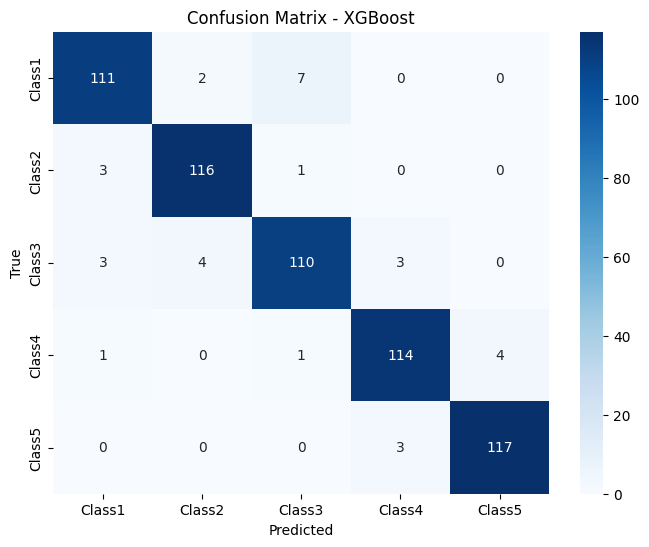

In [ ]:
# transient
doClassification(flatten_segmented_transient_dataset_df, 200, 8, 0.3)

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.9275,0.931955,0.9275,0.927767
3,XGBoost,0.9250,0.928508,0.9250,0.924648
0,SVM (RBF),0.9225,0.927866,0.9225,0.922770
1,Random Forest,0.9125,0.919952,0.9125,0.912453
6,KNN,0.9075,0.914469,0.9075,0.907538
4,Logistic Regression,0.8675,0.874083,0.8675,0.867373
2,Decision Tree,0.8500,0.854678,0.8500,0.849196


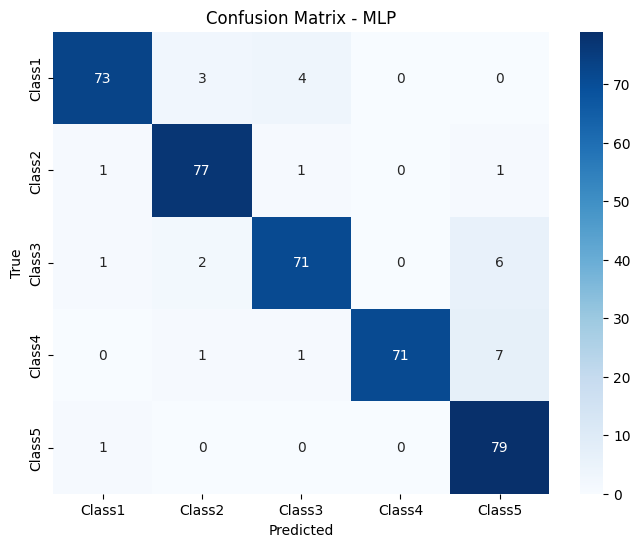

In [ ]:
doClassification(flatten_segmented_transient_dataset_df, 200, 8, 0.2)

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.957778,0.959504,0.957778,0.957964
0,SVM (RBF),0.938889,0.940905,0.938889,0.939065
3,XGBoost,0.937778,0.939202,0.937778,0.937668
4,Logistic Regression,0.931111,0.933605,0.931111,0.931298
1,Random Forest,0.924444,0.926061,0.924444,0.924384
6,KNN,0.903333,0.909077,0.903333,0.904129
2,Decision Tree,0.894444,0.895214,0.894444,0.894312


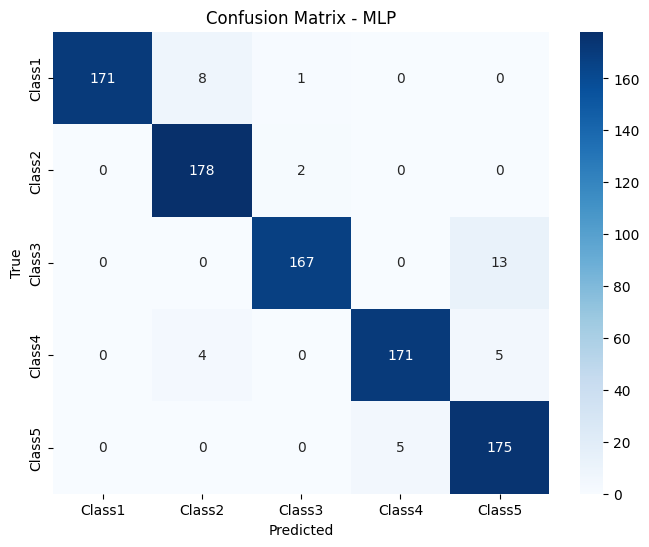

In [ ]:
# steady
doClassification(flatten_segmented_steady_dataset_df, 300, 8, 0.3)

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
3,XGBoost,0.950000,0.951609,0.950000,0.949998
5,MLP,0.945000,0.947571,0.945000,0.944861
0,SVM (RBF),0.940000,0.944427,0.940000,0.940214
1,Random Forest,0.933333,0.934539,0.933333,0.933639
4,Logistic Regression,0.920000,0.921270,0.920000,0.919803
6,KNN,0.896667,0.899622,0.896667,0.897145
2,Decision Tree,0.863333,0.865296,0.863333,0.863814


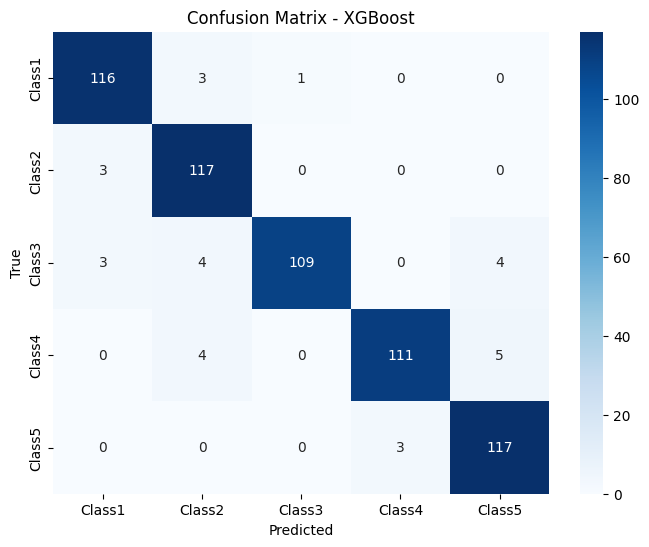

In [ ]:
# after steady
doClassification(flatten_segmented_after_steady_dataset_df, 200, 8, 0.3)

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.959524,0.960448,0.959524,0.959629
3,XGBoost,0.949524,0.950386,0.949524,0.949517
0,SVM (RBF),0.948095,0.949190,0.948095,0.948147
1,Random Forest,0.943333,0.945270,0.943333,0.943358
4,Logistic Regression,0.938095,0.939636,0.938095,0.938155
6,KNN,0.894286,0.898011,0.894286,0.894716
2,Decision Tree,0.860476,0.860788,0.860476,0.859927


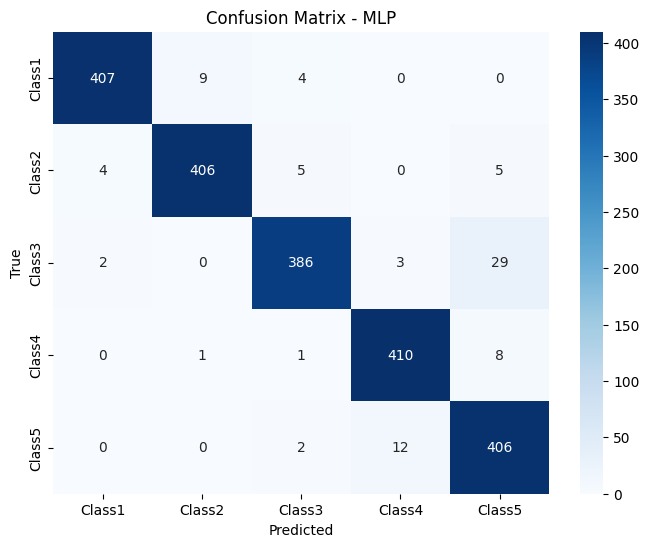

In [ ]:
# combined
doClassification(flatten_segmented_combined_dataset_df, 700, 8, 0.3)

## FEATURE SELECTION PROCEDURES

In [ ]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

def get_top_features(X_value, y_value):

    X = X_value
    y = y_value

    # 1. Menggunakan Mutual Information
    mi_scores = mutual_info_classif(X, y, random_state=42)
    mi_features = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)

    # 2. Menggunakan Random Forest (Akomodasi Non-Linear & Interaksi Sensor)
    model = RandomForestClassifier(random_state=42)
    model.fit(X, y)
    feature_names = X.columns

    # 3. Mengambil nilai Gini Importance dan mengurutkannya
    importances = model.feature_importances_
    df_importance = pd.DataFrame({'Feature': feature_names, 'Gini-Importance': importances})
    df_importance = df_importance.sort_values(by='Gini-Importance', ascending=False) # Urutkan naik untuk plot horizontal

    #print("Top 30 Fitur Berdasarkan Mutual Information:\n", mi_features.head(30))
    #print("Top 30 Fitur Berdasarkan Random Forest:\n", df_importance.head(30))

    return mi_features, df_importance

In [ ]:
def plot_importance_features(features, gini_vals):
    # 1. Membuat visualisasi
    plt.figure(figsize=(10, 6))

    # 2.Membuat grafik batang horizontal
    bars = plt.barh(features, gini_vals, color='skyblue', edgecolor='black')

    # 3.Menambahkan garis ambang batas (misal: threshold = 0.05)
    threshold = 0.05
    plt.axvline(x=threshold, color='red', linestyle='--', linewidth=1.5, label=f'Ambang Batas ({threshold})')

    # 4.Pengaturan teks dan label
    plt.xlabel('Nilai Gini Importance', fontsize=12)
    plt.ylabel('Daftar Fitur', fontsize=12)
    plt.title('Visualisasi Feature Importance (Random Forest)', fontsize=14, fontweight='bold')
    plt.legend(loc='lower right')
    plt.grid(axis='x', linestyle=':', alpha=0.6)

    # 5.Menampilkan nilai teks di ujung setiap batang
    for bar in bars:
        width = bar.get_width()
        plt.text(width + 0.005, bar.get_y() + bar.get_height()/2, f'{width:.3f}',
                va='center', ha='left', fontsize=10)

    plt.tight_layout()
    plt.show()


In [ ]:
def get_elbow_point(df_importance):

    # 3. Mengambil nilai Gini Importance dan mengurutkannya
    importances = df_importance['Gini-Importance']#rf.feature_importances_
    indices = np.argsort(importances)[::-1]  # Urutkan dari besar ke kecil

    # 4. Membuat DataFrame untuk visualisasi data
    #df_importance = pd.DataFrame(
    #    {"Fitur": [feature_names[i] for i in indices], "Importance": importances[indices]}
    #)

    # 5. Visualisasi dengan Elbow Method
    plt.figure(figsize=(10, 6))
    plt.plot(
        range(1, len(importances) + 1),
        df_importance["Gini-Importance"],
        marker="o",
        linestyle="-",
        color="b",
    )

    plt.title("Elbow Method For Feature Selection (Gini Importance)")
    plt.xlabel("Feature Rank (Most Importance -> Low Importance)")
    plt.ylabel("Gini Importance Score")
    plt.xticks(range(1, len(importances) + 1))
    plt.grid(True, linestyle="--", alpha=0.7)

    # Menampilkan grafik
    plt.show()

    # 6. Menampilkan tabel kontribusi kumulatif untuk akurasi tambahan
    df_importance["Kumulatif"] = df_importance["Gini-Importance"].cumsum()
    print("\nTabel Urutan Fitur & Kontribusi Kumulatif:")
    print(df_importance.head(15))  # Menampilkan 15 fitur teratas

In [ ]:
def get_importance_features_name(selected_dataset, X, feature_names, threshold=0.01):
  feat_important_list = selected_dataset[selected_dataset['Gini-Importance']>=threshold]['Feature']
  feat_selected = pd.DataFrame(X, columns=feature_names)
  columns_importance = []
  for item in feat_important_list:
      columns_importance.extend([feat_selected.columns[item]])

  return columns_importance
  display(columns_importance)

In [ ]:
# import libraries

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from xgboost import XGBClassifier
import pandas as pd

In [ ]:
def doClassification_for_feat_selection(Dataset, rows_number, cols_number, t_size):

    all_feature_extractions_df = pd.concat([Dataset.iloc[:,:-1]], axis=1, ignore_index=True)

    # Split data to train & test set
    _X_train, _X_test, _y_train, _y_test = train_test_split(
        all_feature_extractions_df, Dataset['Grade'] - 1, test_size=t_size, random_state=42, stratify=Dataset['Grade'] - 1
    )

    ## ===== Procedure to do Feature Extraction ===== ##

    seg_X_train = _X_train.values.reshape(-1, rows_number, cols_number)
    seg_X_train = seg_X_train.astype(np.float64)

    seg_X_test = _X_test.values.reshape(-1, rows_number, cols_number)
    seg_X_test = seg_X_test.astype(np.float64)

    X_train_Feat_Ex = extract_handcrafted_features_windowed(seg_X_train, window_sec=50, level=1, overlap_sec=0)
    X_test_Feat_Ex = extract_handcrafted_features_windowed(seg_X_test, window_sec=50, level=1, overlap_sec=0)

    grade_list_train = _y_train
    grade_list_test = _y_test

    n = int(X_train_Feat_Ex[0].shape[0]/seg_X_train.shape[0])  # duplicate each item

    _y_train_dup = []
    _y_test_dup = []

    for item in grade_list_train:
        _y_train_dup.extend([item] * n)

    for item in grade_list_test:
        _y_test_dup.extend([item] * n)

    return (X_train_Feat_Ex, X_test_Feat_Ex, _y_train_dup, _y_test_dup)

## ============== End Of Feat Extraction ============== ##


In [ ]:
import time

def TestClassification_after_Features_Selection(X_train_Feat_Ex, X_test_Feat_Ex, y_train_dup, y_test_dup, list_of_selected_feats):

    starttime = time.time()

    X_train = pd.DataFrame(X_train_Feat_Ex).iloc[:,list_of_selected_feats].values
    X_test = pd.DataFrame(X_test_Feat_Ex).iloc[:,list_of_selected_feats].values

    # Standardize the data (scaling)
    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    y_train = y_train_dup
    y_test = y_test_dup

    # Train a Support Vector Machine (SVM) classifier

    list_models = {
        "SVM (RBF)": SVC(kernel='rbf', C=2.5, gamma='scale', random_state=42),

        "Random Forest": RandomForestClassifier(
            n_estimators=200, max_depth=None, random_state=42
        ),

        "Decision Tree": DecisionTreeClassifier(
            max_depth=None, random_state=42
        ),

        "XGBoost": XGBClassifier(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric='mlogloss'
        ),

        "Logistic Regression": LogisticRegression(
            max_iter=1000, random_state=42
        ),

        "MLP": MLPClassifier(
            hidden_layer_sizes=(200,),
            max_iter=500,
            random_state=42
        ),

        "KNN": KNeighborsClassifier(
            n_neighbors=7
        ),

        #"NAIVE BAYES": GaussianNB()

    }

    results = []

    for model_name, model in list_models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        results.append({
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision (Macro)": precision_score(y_test, y_pred, average='macro'),
            "Recall (Macro)": recall_score(y_test, y_pred, average='macro'),
            "F1-score (Macro)": f1_score(y_test, y_pred, average='macro')
        })

    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(by="F1-score (Macro)", ascending=False)

    display(results_df)

    best_model_name = results_df.iloc[0]["Model"]
    best_model = list_models[best_model_name]

    y_best_pred = best_model.predict(X_test)

    conf_mat = confusion_matrix(y_test, y_best_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
                xticklabels=["Class1","Class2","Class3","Class4","Class5"],
                yticklabels=["Class1","Class2","Class3","Class4","Class5"])
    plt.title(f"Confusion Matrix - {best_model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

    print(f"Runtime: {time.time() - starttime}")
    print(X_train.shape)

### 1. Transient Dataset

In [ ]:
flatten_segmented_transient_dataset_df.shape

(500, 1601)

In [ ]:
X_train_Feat_Ex_transient, X_test_Feat_Ex_transient, y_train_dup_transient, y_test_dup_transient = doClassification_for_feat_selection(flatten_segmented_transient_dataset_df, 200, 8, 0.3)

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [ ]:
_, df_result_importance_feats_transient = get_top_features(pd.DataFrame(X_train_Feat_Ex_transient[0]),y_train_dup_transient)

In [ ]:
df_result_importance_feats_transient

,Feature,Gini-Importance
63,63,0.025177
165,165,0.023896
97,97,0.022278
201,201,0.021780
74,74,0.020717
...,...,...
194,194,0.000000
202,202,0.000000
200,200,0.000000
204,204,0.000000


In [ ]:
importance_feats = get_importance_features_name(df_result_importance_feats_transient, X_train_Feat_Ex_transient[0], X_train_Feat_Ex_transient[1])
len(importance_feats)

35

In [ ]:
threshold = 0.001
index_of_importance_feats = df_result_importance_feats_transient[df_result_importance_feats_transient['Gini-Importance']>=threshold].index
index_of_importance_feats

Index([ 63, 165,  97, 201,  74, 100, 135,  65,  59, 112,
       ...
        67,  68, 130,  99,  73,  29,  58, 105,   9, 113],
      dtype='int64', length=154)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
3,XGBoost,0.946667,0.946710,0.946667,0.946591
5,MLP,0.945000,0.945918,0.945000,0.945037
0,SVM (RBF),0.943333,0.943550,0.943333,0.943161
1,Random Forest,0.913333,0.913663,0.913333,0.912913
6,KNN,0.906667,0.909572,0.906667,0.906809
4,Logistic Regression,0.888333,0.889774,0.888333,0.887629
2,Decision Tree,0.833333,0.835212,0.833333,0.833933


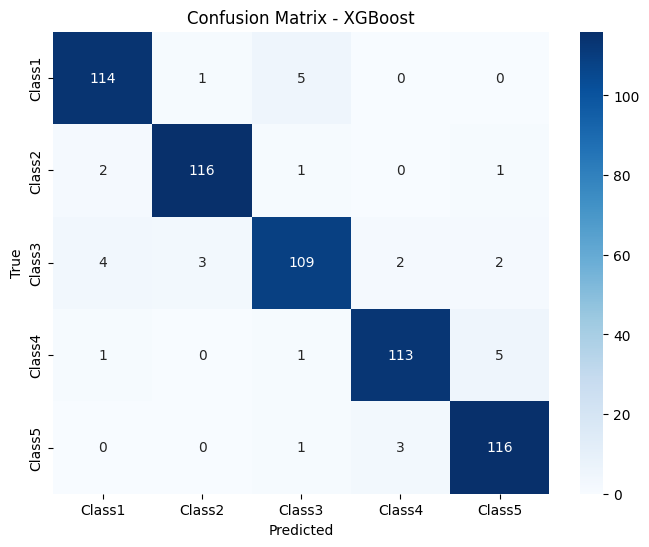

Runtime: 24.673484802246094
(1400, 154)


In [ ]:
TestClassification_after_Features_Selection(X_train_Feat_Ex_transient[0], X_test_Feat_Ex_transient[0], y_train_dup_transient, y_test_dup_transient, index_of_importance_feats)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
3,XGBoost,0.946667,0.946710,0.946667,0.946591
5,MLP,0.945000,0.945918,0.945000,0.945037
0,SVM (RBF),0.943333,0.943550,0.943333,0.943161
1,Random Forest,0.913333,0.913663,0.913333,0.912913
6,KNN,0.906667,0.909572,0.906667,0.906809
4,Logistic Regression,0.888333,0.889774,0.888333,0.887629
2,Decision Tree,0.833333,0.835212,0.833333,0.833933


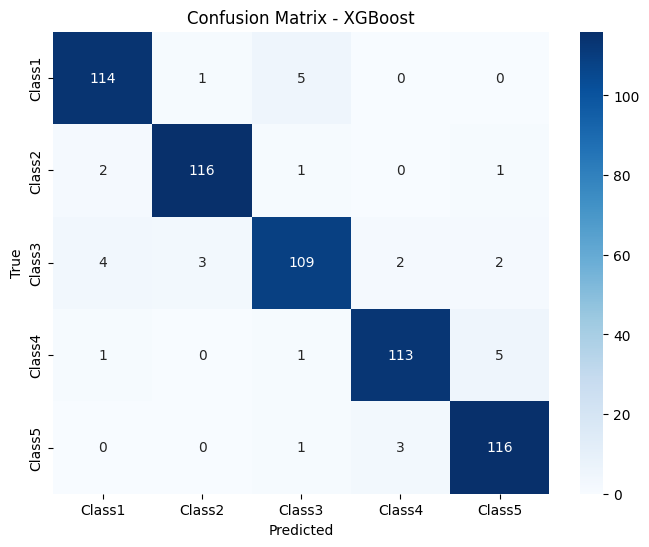

Runtime: 28.643057584762573
(1400, 154)


In [ ]:
TestClassification_after_Features_Selection(X_train_Feat_Ex_transient[0], X_test_Feat_Ex_transient[0], y_train_dup_transient, y_test_dup_transient, index_of_importance_feats)

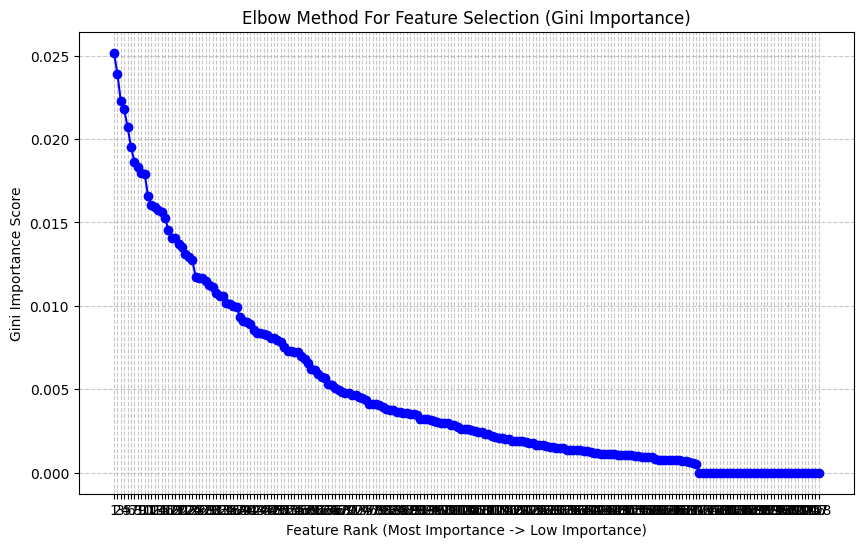


Tabel Urutan Fitur & Kontribusi Kumulatif:
     Feature  Gini-Importance  Kumulatif
63        63         0.025177   0.025177
165      165         0.023896   0.049074
97        97         0.022278   0.071351
201      201         0.021780   0.093131
74        74         0.020717   0.113847
100      100         0.019511   0.133359
135      135         0.018654   0.152013
65        65         0.018352   0.170364
59        59         0.017981   0.188345
112      112         0.017928   0.206273
102      102         0.016559   0.222832
88        88         0.016077   0.238909
57        57         0.015908   0.254817
103      103         0.015742   0.270560
64        64         0.015658   0.286218


In [ ]:
get_elbow_point(df_result_importance_feats_transient)

### 2. Steady Dataset

In [ ]:
flatten_segmented_steady_dataset_df.shape

(500, 2401)

In [ ]:
X_train_Feat_Ex_steady, X_test_Feat_Ex_steady, y_train_dup_steady, y_test_dup_steady = doClassification_for_feat_selection(flatten_segmented_steady_dataset_df, 300, 8, 0.3)

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [ ]:
_, df_result_importance_feats_steady = get_top_features(pd.DataFrame(X_train_Feat_Ex_steady[0]),y_train_dup_steady)

In [ ]:
importance_feats2 = get_importance_features_name(df_result_importance_feats_steady, X_train_Feat_Ex_steady[0], X_train_Feat_Ex_steady[1])
len(importance_feats2)

38

In [ ]:
threshold = 0.01
index_of_importance_feats2 = df_result_importance_feats_steady[df_result_importance_feats_steady['Gini-Importance']>=threshold].index
index_of_importance_feats2

Index([112, 161, 103, 187, 102, 100, 177, 165,  97, 205,  98, 107,  95, 138,
       183,  74, 159, 201,  79, 155, 101,  65,  63,   2,   0,  57,  64, 157,
        88, 135,  62, 150,  69,  59, 141,  84, 191,  93],
      dtype='int64')

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.954444,0.955822,0.954444,0.954569
6,KNN,0.940000,0.942793,0.940000,0.939800
0,SVM (RBF),0.932222,0.934082,0.932222,0.932181
3,XGBoost,0.926667,0.927482,0.926667,0.926467
1,Random Forest,0.918889,0.920520,0.918889,0.918837
2,Decision Tree,0.882222,0.885362,0.882222,0.881844
4,Logistic Regression,0.814444,0.815178,0.814444,0.810421


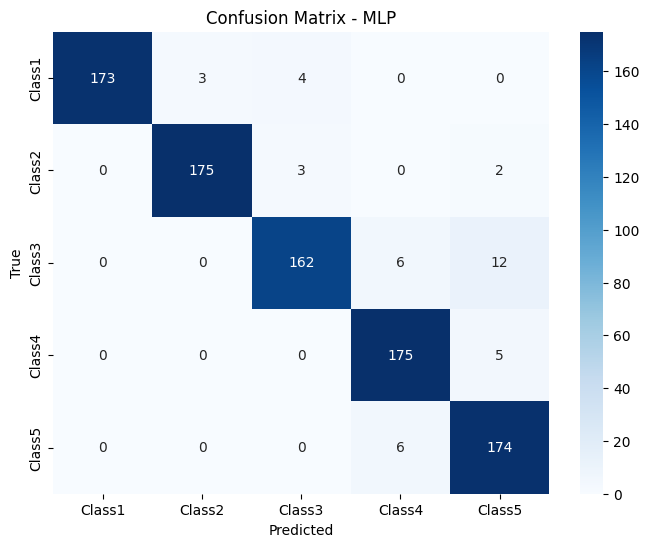

Runtime: 15.253549814224243
(2100, 38)


In [ ]:
TestClassification_after_Features_Selection(X_train_Feat_Ex_steady[0], X_test_Feat_Ex_steady[0], y_train_dup_steady, y_test_dup_steady, index_of_importance_feats2)

In [ ]:
threshold = 0.001
index_of_importance_feats2 = df_result_importance_feats_steady[df_result_importance_feats_steady['Gini-Importance']>=threshold].index
index_of_importance_feats2

Index([112, 161, 103, 187, 102, 100, 177, 165,  97, 205,
       ...
        26,  92,  39, 149,  91, 151, 134,  90, 125,  53],
      dtype='int64', length=118)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.952222,0.953913,0.952222,0.952556
4,Logistic Regression,0.945556,0.947090,0.945556,0.945682
0,SVM (RBF),0.942222,0.946414,0.942222,0.942885
3,XGBoost,0.937778,0.939477,0.937778,0.937746
1,Random Forest,0.930000,0.931338,0.930000,0.929968
6,KNN,0.928889,0.932812,0.928889,0.929228
2,Decision Tree,0.906667,0.907130,0.906667,0.906551


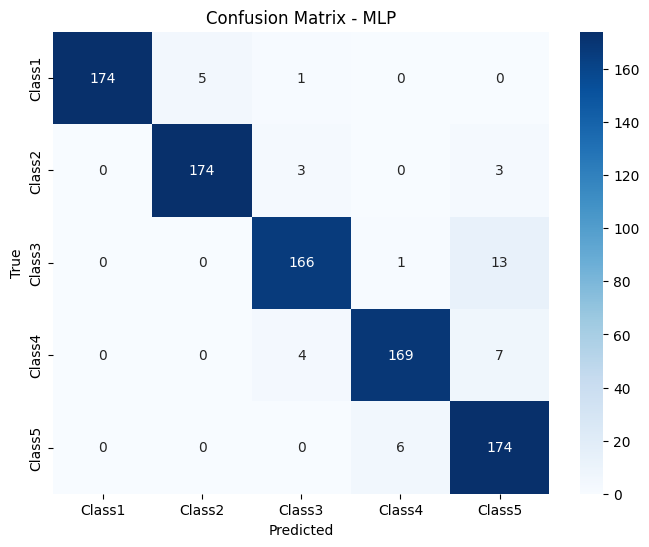

Runtime: 110.91437411308289
(2100, 118)


In [ ]:
TestClassification_after_Features_Selection(X_train_Feat_Ex_steady[0], X_test_Feat_Ex_steady[0], y_train_dup_steady, y_test_dup_steady, index_of_importance_feats2)

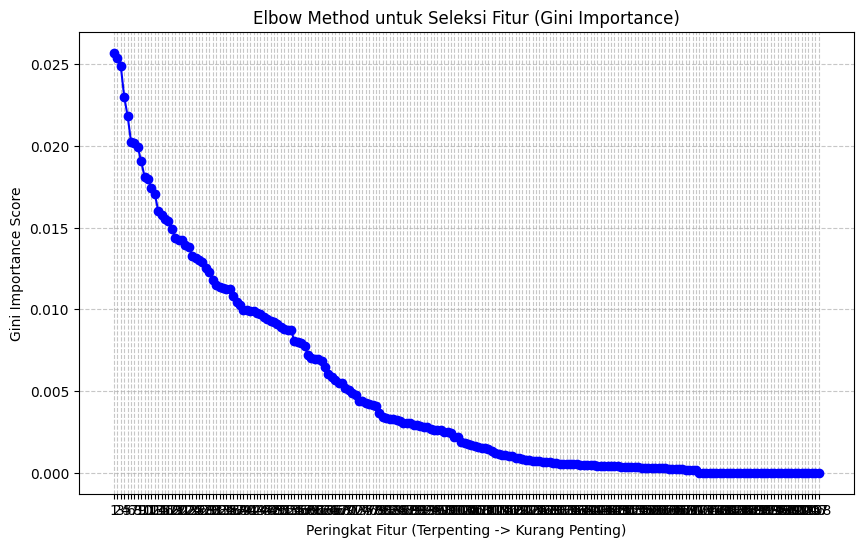


Tabel Urutan Fitur & Kontribusi Kumulatif:
     Feature  Gini-Importance  Kumulatif
112      112         0.025694   0.025694
161      161         0.025375   0.051069
103      103         0.024866   0.075935
187      187         0.022991   0.098925
102      102         0.021825   0.120750
100      100         0.020257   0.141007
177      177         0.020187   0.161194
165      165         0.019905   0.181099
97        97         0.019043   0.200142
205      205         0.018089   0.218231
98        98         0.017978   0.236208
107      107         0.017402   0.253611
95        95         0.017045   0.270656
138      138         0.016012   0.286668
183      183         0.015769   0.302437


In [ ]:
get_elbow_point(df_result_importance_feats_steady)

### 3. After Steady

In [ ]:
flatten_segmented_after_steady_dataset_df.shape

(500, 1601)

In [ ]:
X_train_Feat_Ex_after_steady, X_test_Feat_Ex_after_steady, y_train_dup_after_steady, y_test_dup_after_steady = doClassification_for_feat_selection(flatten_segmented_after_steady_dataset_df, 200, 8, 0.3)

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [ ]:
_, df_result_importance_feats_after_steady = get_top_features(pd.DataFrame(X_train_Feat_Ex_after_steady[0]),y_train_dup_after_steady)

In [ ]:
importance_feats3 = get_importance_features_name(df_result_importance_feats_after_steady, X_train_Feat_Ex_after_steady[0], X_train_Feat_Ex_after_steady[1])
len(importance_feats3)

40

In [ ]:
threshold = 0.01
index_of_importance_feats3 = df_result_importance_feats_after_steady[df_result_importance_feats_after_steady['Gini-Importance']>=threshold].index
index_of_importance_feats3

Index([187, 177, 112,  63, 161, 159,  64, 165, 100,  95, 103,  98,  65,  59,
       155, 205,  74, 179,  97, 101,  57, 173, 102,  88, 135,  62, 207,   2,
       138, 157,  83, 201,  84, 191,  17,  82,  60, 183, 107,   0],
      dtype='int64')

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,SVM (RBF),0.963333,0.965588,0.963333,0.963667
5,MLP,0.963333,0.963701,0.963333,0.963349
1,Random Forest,0.960000,0.960241,0.960000,0.959967
6,KNN,0.953333,0.953749,0.953333,0.953437
3,XGBoost,0.950000,0.951614,0.950000,0.950131
2,Decision Tree,0.885000,0.887496,0.885000,0.884612
4,Logistic Regression,0.880000,0.879607,0.880000,0.877719


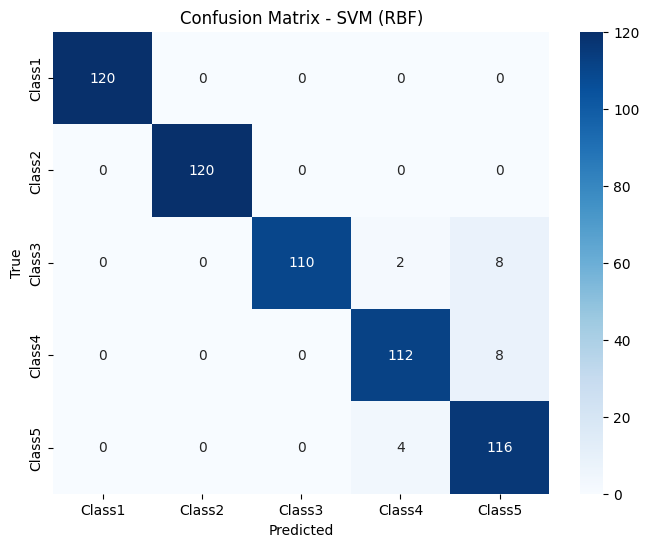

Runtime: 7.347224712371826
(1400, 40)


In [ ]:
TestClassification_after_Features_Selection(X_train_Feat_Ex_after_steady[0], X_test_Feat_Ex_after_steady[0], y_train_dup_after_steady, y_test_dup_after_steady, index_of_importance_feats3)

In [ ]:
threshold = 0.001
index_of_importance_feats3 = df_result_importance_feats_after_steady[df_result_importance_feats_after_steady['Gini-Importance']>=threshold].index
index_of_importance_feats3

Index([187, 177, 112,  63, 161, 159,  64, 165, 100,  95,
       ...
        77, 125, 151,  39,  92,  35, 134, 137,   1,  90],
      dtype='int64', length=118)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.961667,0.963810,0.961667,0.961617
4,Logistic Regression,0.950000,0.953038,0.950000,0.950431
0,SVM (RBF),0.948333,0.951183,0.948333,0.948703
3,XGBoost,0.945000,0.947269,0.945000,0.945171
1,Random Forest,0.941667,0.943126,0.941667,0.941846
6,KNN,0.936667,0.940880,0.936667,0.937442
2,Decision Tree,0.878333,0.883069,0.878333,0.879658


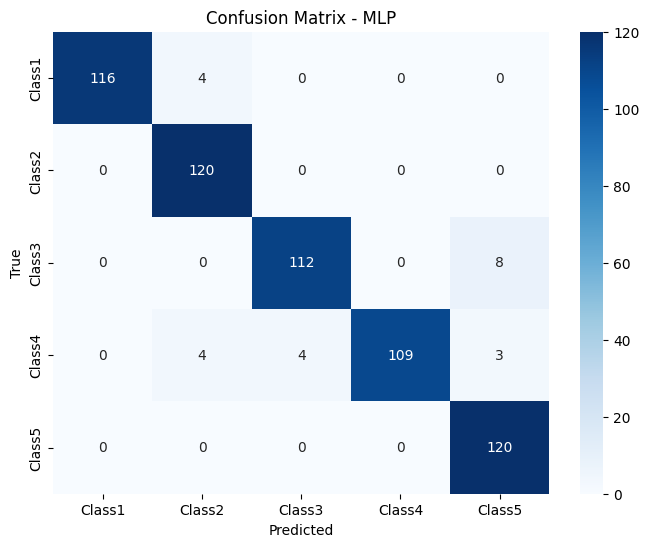

Runtime: 72.80820369720459
(1400, 118)


In [ ]:
TestClassification_after_Features_Selection(X_train_Feat_Ex_after_steady[0], X_test_Feat_Ex_after_steady[0], y_train_dup_after_steady, y_test_dup_after_steady, index_of_importance_feats3)

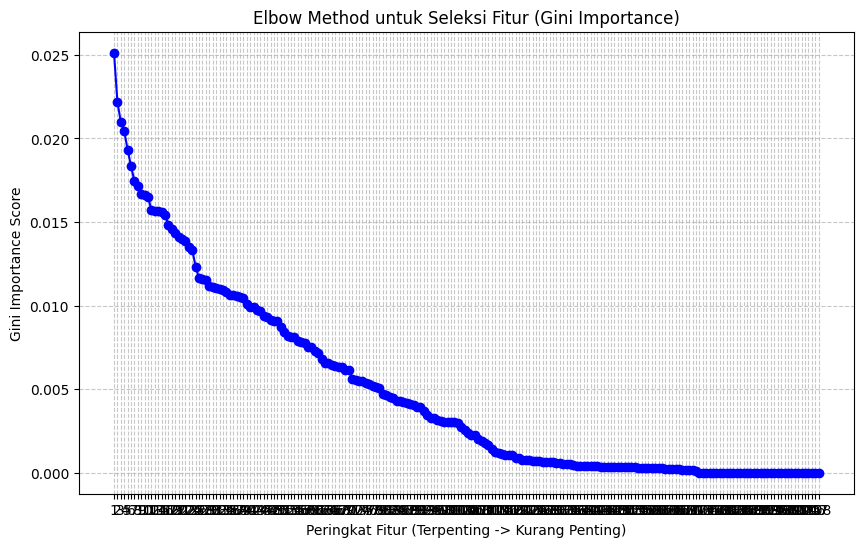


Tabel Urutan Fitur & Kontribusi Kumulatif:
     Feature  Gini-Importance  Kumulatif
187      187         0.025130   0.025130
177      177         0.022185   0.047315
112      112         0.020992   0.068307
63        63         0.020442   0.088749
161      161         0.019336   0.108085
159      159         0.018343   0.126428
64        64         0.017448   0.143876
165      165         0.017177   0.161053
100      100         0.016704   0.177757
95        95         0.016624   0.194381
103      103         0.016469   0.210850
98        98         0.015731   0.226581
65        65         0.015650   0.242231
59        59         0.015646   0.257877
155      155         0.015596   0.273473


In [ ]:
get_elbow_point(df_result_importance_feats_after_steady)

### 4. Combined

In [ ]:
flatten_segmented_combined_dataset_df.shape

(500, 5601)

In [ ]:
X_train_Feat_Ex_combined, X_test_Feat_Ex_combined, y_train_dup_combined, y_test_dup_combined = doClassification_for_feat_selection(flatten_segmented_combined_dataset_df, 700, 8, 0.3)

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [ ]:
_, df_result_importance_feats_combined = get_top_features(pd.DataFrame(X_train_Feat_Ex_combined[0]),y_train_dup_combined)

In [ ]:
importance_feats4 = get_importance_features_name(df_result_importance_feats_combined, X_train_Feat_Ex_combined[0], X_train_Feat_Ex_combined[1])
len(importance_feats4)
display(importance_feats4)

['sensor3_wavelet_energy_L0',
 'sensor3_percentile_75',
 'diff_energy_s0_s7',
 'sensor3_rms',
 'sensor3_percentile_50',
 'diff_energy_s2_s7',
 'diff_energy_s2_s5',
 'diff_energy_s5_s7',
 'sensor5_percentile_25',
 'sensor3_percentile_25',
 'diff_energy_s0_s5',
 'diff_energy_s1_s7',
 'sensor3_min',
 'sensor5_min',
 'sensor7_min',
 'sensor5_mean',
 'diff_energy_s4_s7',
 'sensor3_max',
 'sensor3_mean',
 'sensor4_max',
 'sensor5_rms',
 'sensor7_percentile_25',
 'sensor4_auc',
 'sensor4_rms',
 'sensor5_percentile_50',
 'sensor0_min',
 'sensor5_wavelet_energy_L0',
 'diff_energy_s2_s3',
 'sensor4_percentile_75',
 'diff_energy_s3_s5',
 'diff_energy_s6_s7',
 'sensor4_min',
 'sensor4_percentile_50',
 'diff_energy_s0_s4',
 'diff_energy_s0_s1',
 'sensor5_auc',
 'sensor5_max',
 'sensor7_mean',
 'sensor7_wavelet_energy_L0',
 'sensor7_rms',
 'sensor4_wavelet_energy_L0',
 'sensor3_auc',
 'sensor7_auc',
 'diff_energy_s0_s2']

In [ ]:
threshold = 0.01
index_of_importance_feats4 = df_result_importance_feats_combined[df_result_importance_feats_combined['Gini-Importance']>=threshold].index
len(index_of_importance_feats4)

44

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.955714,0.956162,0.955714,0.955731
0,SVM (RBF),0.955238,0.955946,0.955238,0.955271
6,KNN,0.949048,0.950712,0.949048,0.949088
3,XGBoost,0.941905,0.944307,0.941905,0.942019
1,Random Forest,0.935714,0.938118,0.935714,0.935609
2,Decision Tree,0.866190,0.866738,0.866190,0.865625
4,Logistic Regression,0.850476,0.849241,0.850476,0.849426


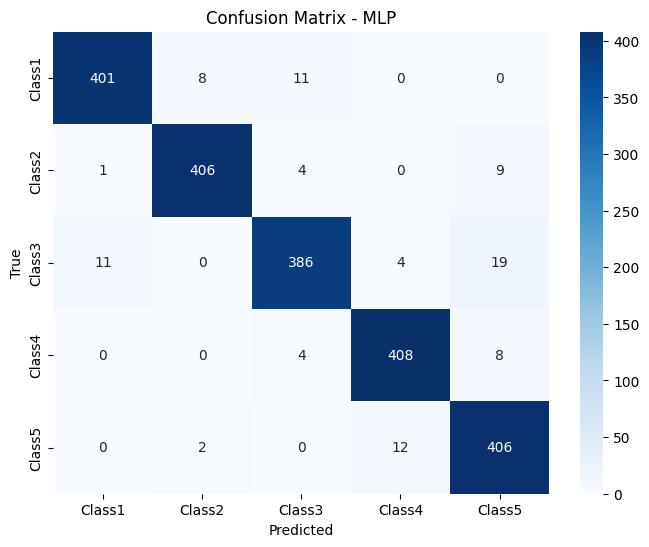

Runtime: 34.28665542602539
(4900, 44)


In [ ]:
TestClassification_after_Features_Selection(X_train_Feat_Ex_combined[0], X_test_Feat_Ex_combined[0], y_train_dup_combined, y_test_dup_combined, index_of_importance_feats4)

In [ ]:
threshold = 0.001
index_of_importance_feats4 = df_result_importance_feats_combined[df_result_importance_feats_combined['Gini-Importance']>=threshold].index
len(index_of_importance_feats4)

123

In [ ]:
X_train_Feat_Ex_combined[1]

['sensor0_mean',
 'sensor0_std',
 'sensor0_min',
 'sensor0_max',
 'sensor0_range',
 'sensor0_percentile_25',
 'sensor0_percentile_75',
 'sensor0_percentile_50',
 'sensor0_rms',
 'sensor0_skew',
 'sensor0_kurtosis',
 'sensor0_slope',
 'sensor0_auc',
 'sensor0_fft_peakfreq',
 'sensor0_spec_centroid',
 'sensor0_spec_entropy',
 'sensor0_bandpower',
 'sensor0_wavelet_energy_L0',
 'sensor0_wavelet_energy_L1',
 'sensor1_mean',
 'sensor1_std',
 'sensor1_min',
 'sensor1_max',
 'sensor1_range',
 'sensor1_percentile_25',
 'sensor1_percentile_75',
 'sensor1_percentile_50',
 'sensor1_rms',
 'sensor1_skew',
 'sensor1_kurtosis',
 'sensor1_slope',
 'sensor1_auc',
 'sensor1_fft_peakfreq',
 'sensor1_spec_centroid',
 'sensor1_spec_entropy',
 'sensor1_bandpower',
 'sensor1_wavelet_energy_L0',
 'sensor1_wavelet_energy_L1',
 'sensor2_mean',
 'sensor2_std',
 'sensor2_min',
 'sensor2_max',
 'sensor2_range',
 'sensor2_percentile_25',
 'sensor2_percentile_75',
 'sensor2_percentile_50',
 'sensor2_rms',
 'sensor2

In [ ]:
importance_feats_ = get_importance_features_name(df_result_importance_feats_combined, X_train_Feat_Ex_combined[0], X_train_Feat_Ex_combined[1])
pd.DataFrame(importance_feats_).sort_values(by=0)

,0
34,diff_energy_s0_s1
43,diff_energy_s0_s2
33,diff_energy_s0_s4
10,diff_energy_s0_s5
2,diff_energy_s0_s7
11,diff_energy_s1_s7
27,diff_energy_s2_s3
6,diff_energy_s2_s5
5,diff_energy_s2_s7
29,diff_energy_s3_s5


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.956190,0.957609,0.956190,0.956378
0,SVM (RBF),0.950952,0.952594,0.950952,0.951217
3,XGBoost,0.946667,0.947586,0.946667,0.946662
1,Random Forest,0.946667,0.948137,0.946667,0.946567
4,Logistic Regression,0.938571,0.939895,0.938571,0.938499
6,KNN,0.934762,0.936314,0.934762,0.934904
2,Decision Tree,0.854286,0.855483,0.854286,0.854050


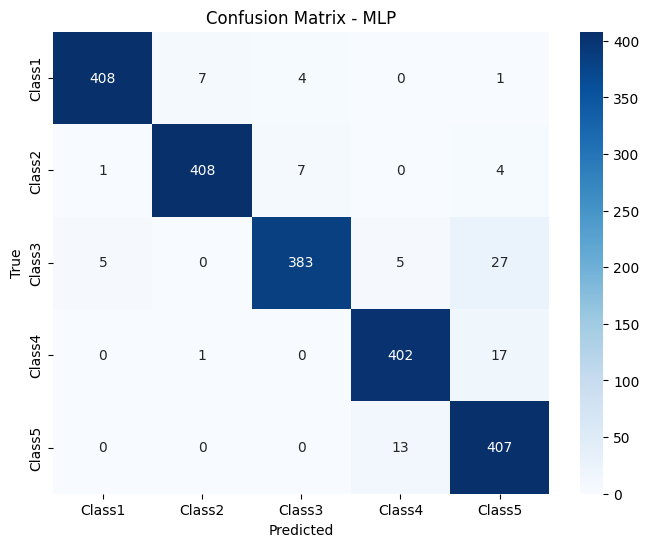

Runtime: 38.26813101768494
(4900, 123)


In [ ]:
TestClassification_after_Features_Selection(X_train_Feat_Ex_combined[0], X_test_Feat_Ex_combined[0], y_train_dup_combined, y_test_dup_combined, index_of_importance_feats4)

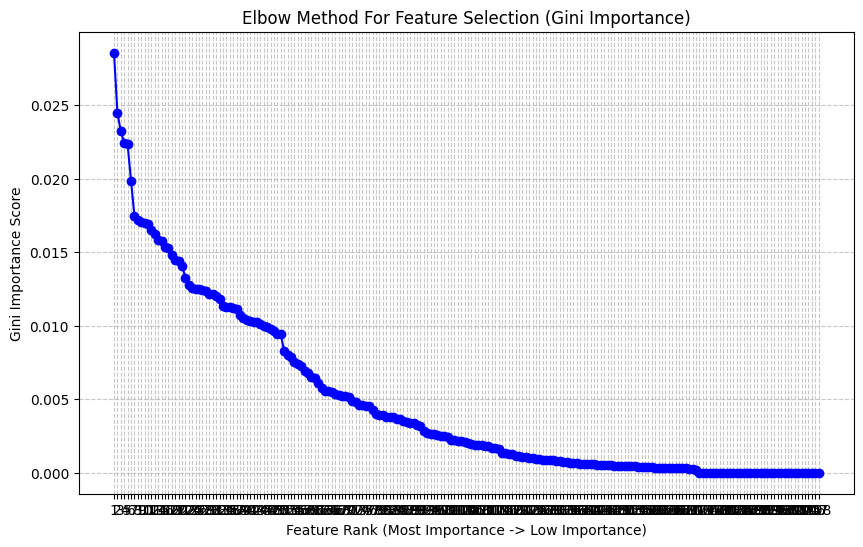


Tabel Urutan Fitur & Kontribusi Kumulatif:
     Feature  Gini-Importance  Kumulatif
74        74         0.028564   0.028564
63        63         0.024473   0.053037
165      165         0.023221   0.076258
65        65         0.022418   0.098676
64        64         0.022326   0.121002
187      187         0.019852   0.140853
183      183         0.017470   0.158324
205      205         0.017168   0.175492
100      100         0.017047   0.192538
62        62         0.016954   0.209492
161      161         0.016932   0.226424
177      177         0.016539   0.242963
59        59         0.016213   0.259176
97        97         0.015798   0.274974
135      135         0.015733   0.290707


In [ ]:
get_elbow_point(df_result_importance_feats_combined)

In [ ]:
_, df_result_importance_feats_combined_raw_data = get_top_features(df.iloc[:,2:10],df['Grade'])

In [ ]:
df.iloc[:,2:10]

,MQ2,MQ3,MQ4,MQ7,MQ8,MQ135,MQ137,TGS
0,0.865715,1.022924,1.010504,1.006786,1.000602,0.997857,1.003009,1.034609
1,0.840325,0.992326,1.007607,1.003092,0.996449,0.995177,1.003009,0.996468
2,0.812970,1.015111,1.007607,1.003092,1.000602,1.000551,1.000554,0.972537
3,0.790368,1.011246,1.004726,1.010503,1.000602,1.003258,1.007953,1.034609
4,0.762982,0.999814,1.004726,0.999421,1.000602,1.003258,1.003009,1.021581
...,...,...,...,...,...,...,...,...
499995,0.639680,0.790189,0.899343,0.869015,0.831095,0.841843,0.805430,0.458277
499996,0.682751,0.776432,0.879090,0.876380,0.831095,0.839572,0.805430,0.444689
499997,0.670257,0.788640,0.881576,0.876380,0.852443,0.832824,0.820702,0.444689
499998,0.528205,0.771937,0.884076,0.872684,0.842834,0.830596,0.820702,0.458277


In [ ]:
df['Grade'][1]

np.int64(1)

In [ ]:
#importance_feats__for_raw_data = get_importance_features_name(df_result_importance_feats_combined_raw_data, df.iloc[:,2:10], df['Grade'][1])
#len(importance_feats__for_raw_data)

In [ ]:
import time

def TestClassification_after_Features_Selection_X(X_train_Feat_Ex, X_test_Feat_Ex, y_train_dup, y_test_dup, list_of_selected_feats):

    starttime = time.time()

    X_train = pd.DataFrame(X_train_Feat_Ex).iloc[:,list_of_selected_feats].values
    X_test = pd.DataFrame(X_test_Feat_Ex).iloc[:,list_of_selected_feats].values

    # Standardize the data (scaling)
    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    y_train = y_train_dup
    y_test = y_test_dup

    # Train a Support Vector Machine (SVM) classifier

    list_models = {
        "SVM (RBF)": SVC(kernel='rbf', C=2.5, gamma='scale', random_state=42),

        "Random Forest": RandomForestClassifier(
            n_estimators=200, max_depth=None, random_state=42
        ),

        "Decision Tree": DecisionTreeClassifier(
            max_depth=None, random_state=42
        ),

        "XGBoost": XGBClassifier(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric='mlogloss'
        ),

        "Logistic Regression": LogisticRegression(
            max_iter=1000, random_state=42
        ),

        "MLP": MLPClassifier(
            hidden_layer_sizes=(200,),
            max_iter=500,
            random_state=42
        ),

        "KNN": KNeighborsClassifier(
            n_neighbors=7
        ),

        #"NAIVE BAYES": GaussianNB()

    }

    results = []

    for model_name, model in list_models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        results.append({
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision (Macro)": precision_score(y_test, y_pred, average='macro'),
            "Recall (Macro)": recall_score(y_test, y_pred, average='macro'),
            "F1-score (Macro)": f1_score(y_test, y_pred, average='macro')
        })

    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(by="F1-score (Macro)", ascending=False)

    display(results_df)

    best_model_name = results_df.iloc[0]["Model"]
    best_model = list_models[best_model_name]

    y_best_pred = best_model.predict(X_test)

    conf_mat = confusion_matrix(y_test, y_best_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
                xticklabels=["Class1","Class2","Class3","Class4","Class5"],
                yticklabels=["Class1","Class2","Class3","Class4","Class5"])
    plt.title(f"Confusion Matrix - {best_model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

    print(f"Runtime: {time.time() - starttime}")
    print(X_train.shape)
    print(X_test.shape)
    print(len(y_test))


    # =====================================================================
    # MODIFIKASI TERAPKAN P_NOSE DARI ROUTINE KODE MILIKMU
    # =====================================================================

    # 1. Pilih model terbaik yang sudah di-fit
    best_model_name = results_df.iloc[0]["Model"]
    best_model = list_models[best_model_name]

    # 2. Dapatkan probabilitas tingkat window (shape: [num_samples * n, 5])
    y_prob_windows = best_model.predict_proba(X_test)

    # 3. AGREGASI WINDOW: Kembalikan probabilitas ke tingkat sampel asli (150 sampel)
    # n adalah jumlah sub-window per sampel (didapat dari fungsi doClassification)
    num_samples = len(y_test) # Misal: 150 sampel uji E-nose
    n_windows = int(X_test.shape[0] / num_samples)

    print(num_samples)
    print(n_windows)

    # Reshape ke (num_samples, n_windows, 5) lalu hitung RATA-RATA sepanjang axis windows
    P_nose_test = y_prob_windows.reshape(num_samples, n_windows, 5).mean(axis=1)

    # P_nose_test sekarang berukuran (150, 5) -> Siap digunakan untuk Fusion!
    print("Shape P_nose_test:", P_nose_test.shape) # Output: (150, 5)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
5,MLP,0.956190,0.957609,0.956190,0.956378
0,SVM (RBF),0.950952,0.952594,0.950952,0.951217
3,XGBoost,0.946667,0.947586,0.946667,0.946662
1,Random Forest,0.946667,0.948137,0.946667,0.946567
4,Logistic Regression,0.938571,0.939895,0.938571,0.938499
6,KNN,0.934762,0.936314,0.934762,0.934904
2,Decision Tree,0.854286,0.855483,0.854286,0.854050


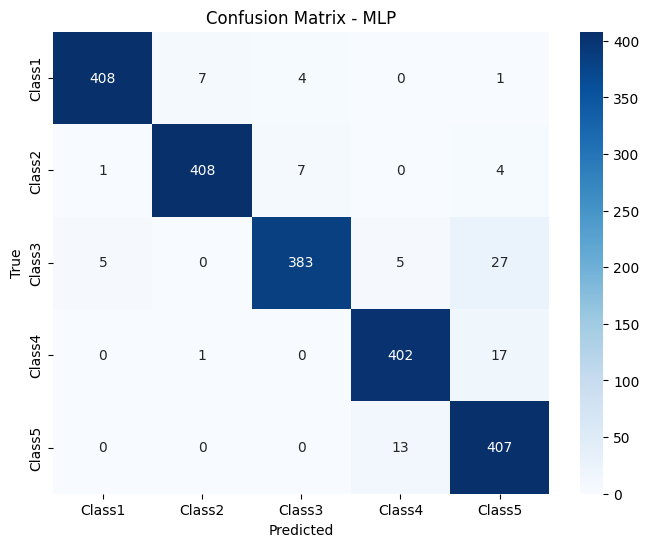

Runtime: 48.36585235595703
(4900, 123)
(2100, 123)
2100
2100
1
Shape P_nose_test: (2100, 5)


In [ ]:
TestClassification_after_Features_Selection_X(X_train_Feat_Ex_combined[0], X_test_Feat_Ex_combined[0], y_train_dup_combined, y_test_dup_combined, index_of_importance_feats4)

## Deep Learning Approach

In [ ]:
import numpy as np
import torch
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, mean_absolute_error, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Dropout, Flatten, Dense, BatchNormalization, Input, Bidirectional, GRU
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import LSTM

def plot_history(history, title_suffix=''):
    plt.figure(figsize=(10,4))
    plt.plot(history.history.get('accuracy', []), label='train_acc')
    plt.plot(history.history.get('val_accuracy', []), label='val_acc')
    plt.title('Accuracy ' + title_suffix)
    plt.xlabel('epoch'); plt.ylabel('accuracy'); plt.legend(); plt.grid(True)
    plt.show()

    plt.figure(figsize=(10,4))
    plt.plot(history.history.get('loss', []), label='train_loss')
    plt.plot(history.history.get('val_loss', []), label='val_loss')
    plt.title('Loss ' + title_suffix)
    plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend(); plt.grid(True)
    plt.show()

def eval_classification(y_true_cat, y_pred_cat, labels=None):
    """
    y_true_cat: one-hot or ordinal-binary depending; expects class labels if one-hot -> converts
    y_pred_cat: predicted class labels (integers)
    """
    # if y_true_cat is one-hot, get argmax
    if y_true_cat.ndim == 2 and y_true_cat.shape[1] > 1:
        y_true = np.argmax(y_true_cat, axis=1)
    else:
        y_true = y_true_cat

    acc = accuracy_score(y_true, y_pred_cat)
    print(f'Accuracy: {acc:.4f}')
    print('Classification report:')
    print(classification_report(y_true, y_pred_cat, zero_division=0))
    cm = confusion_matrix(y_true, y_pred_cat)
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Pred'); plt.ylabel('True'); plt.title('Confusion Matrix')
    plt.show()
    return acc, cm

# ordinal helpers: encode labels -> K-1 binary; predict -> class
def ordinal_encode(labels, num_classes):
    N = len(labels)
    K = num_classes - 1
    Y_ord = np.zeros((N, K))
    for i, g in enumerate(labels):
        Y_ord[i, :g] = 1
    return Y_ord

def ordinal_predict_from_probs(prob_matrix, threshold=0.5):
    # prob_matrix shape (N, K-1)
    return np.sum(prob_matrix > threshold, axis=1)



### Modular Routines for DL Classif

In [ ]:
def dataset_gen_for_DL(df_for_deep_learning, num_samples, num_classes, time_steps, num_sensors):
    X = df_for_deep_learning.iloc[:,:-1].values.reshape(num_samples, time_steps, num_sensors)
    y = df_for_deep_learning['Grade'].apply(lambda x: x-1).values

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X.reshape(-1, num_sensors)).reshape(-1, time_steps, num_sensors)
    y_cat = np.eye(num_classes)[y]  # one-hot for nominal training (or you can use ordinal variant separately)

    X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_cat, test_size=0.3, random_state=42, stratify=y)

    return X_train, X_test, y_train, y_test

In [ ]:
def dataset_gen_for_DL2(df_for_deep_learning, num_samples, num_classes, time_steps, num_sensors, split_r1=0.2, split_r2=0.5):
    X = df_for_deep_learning.iloc[:,:-1].values.reshape(-1, time_steps, num_sensors)
    y = df_for_deep_learning['Grade'].astype(int).apply(lambda x: x-1).values

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X.reshape(-1, num_sensors)).reshape(-1, time_steps, num_sensors)
    y_cat = np.eye(num_classes)[y]  # one-hot for nominal training (or you can use ordinal variant separately)


    # 2. Split pertama: Data utama menjadi Train (80%) dan Sementara/Test (20%)
    X_train, X_temp, y_train, y_temp = train_test_split(
        X_scaled, y_cat, test_size=split_r1, random_state=42, stratify=y_cat
    )

    # 3. Split kedua: Data sementara (20%) dibagi menjadi Validation (10%) dan Test (10%)
    # Karena 10% adalah setengah dari 20% awal, kita gunakan test_size=0.5
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=split_r2, random_state=42, stratify=y_temp
    )

    print(X_train.shape)
    print(X_val.shape)
    print(X_test.shape)

    return X_train, y_train, X_val, y_val, X_test, y_test

In [ ]:
# Reuse preprocessing (X_scaled, y_cat, X_train, X_test...)

def Classif_CNN(X_train, y_train, X_val, y_val, X_test, y_test, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5):

    # transient
    # Reuse preprocessing (X_scaled, y_cat, X_train, X_test...)

    model_cnn = Sequential([
        Input(shape=(time_steps, num_sensors)),

        Conv1D(filters=32, kernel_size=7, activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling1D(2),
        #Dropout(0.3),

        Conv1D(filters=64, kernel_size=5, activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling1D(2),
        Dropout(0.2),

        Flatten(),
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(num_classes, activation='softmax')
    ])

    model_cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    model_cnn.summary()

    es = EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True)

    history_cnn = model_cnn.fit(X_train, y_train, epochs=epochs, batch_size=b_size, validation_data=(X_val, y_val), callbacks=[es])

    # EVALUATE
    plot_history(history_cnn, 'CNN')
    y_pred_cnn = np.argmax(model_cnn.predict(X_test), axis=1)
    eval_classification(y_test, y_pred_cnn)



In [ ]:
# Reuse preprocessing (X_scaled, y_cat, X_train, X_test...)

def Classif_CNN_LSTM(X_train, y_train, X_val, y_val, X_test, y_test, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5):

    model_cnn_lstm = Sequential([
        Input(shape=(time_steps, num_sensors)),

        Conv1D(32, kernel_size=7, padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling1D(2),

        Conv1D(64, kernel_size=5, padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling1D(2),

        LSTM(64, return_sequences=False),
        Dropout(0.4),

        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ])

    model_cnn_lstm.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    model_cnn_lstm.summary()

    es = EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True)

    history_lstm = model_cnn_lstm.fit(X_train, y_train, epochs=epochs, batch_size=b_size, validation_data=(X_val, y_val), callbacks=[es])

    # EVALUATE
    plot_history(history_lstm, 'CNN+LSTM')
    y_pred_lstm = np.argmax(model_cnn_lstm.predict(X_test), axis=1)
    eval_classification(y_test, y_pred_lstm)


In [ ]:
# Reuse preprocessing (X_scaled, y_cat, X_train, X_test...)

def Classif_CNN_BiGru(X_train, y_train, X_val, y_val, X_test, y_test, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5):

    model_cnn_bigru = Sequential([
        Input(shape=(time_steps, num_sensors)),

        Conv1D(32, kernel_size=7, padding='same', activation='relu'), #k_size = 5
        BatchNormalization(),
        MaxPooling1D(2),

        Conv1D(64, kernel_size=5, padding='same', activation='relu'), #k_size = 5
        BatchNormalization(),
        MaxPooling1D(2),

        # keep sequence for GRU
        Bidirectional(GRU(64, return_sequences=False)),  # returns single vector
        Dropout(0.4),

        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ])

    model_cnn_bigru.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    model_cnn_bigru.summary()

    es = EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True)

    history_cnn_bigru = model_cnn_bigru.fit(X_train, y_train, epochs=100, batch_size=32, validation_data=(X_val, y_val), callbacks=[es])

    # EVALUATE
    plot_history(history_cnn_bigru, 'CNN+BiGRU')
    y_pred_cnn_bigru = np.argmax(model_cnn_bigru.predict(X_test), axis=1)
    eval_classification(y_test, y_pred_cnn_bigru)


In [ ]:
def Classif_CNN_BiGru_Modified(X_train, y_train, X_val, y_val, X_test, y_test, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5):

    #from tensorflow.keras.models import Sequential
    #from tensorflow.keras.losses import CategoricalCrossentropy

    model_cnn_bigru_pf = Sequential([

        Input(shape=(time_steps, num_sensors)),

        # ===== CNN BLOCK 1 =====
        Conv1D(
            filters=32,
            kernel_size=7,
            padding='same',
            activation='relu',
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Dropout(0.15),

        # ===== CNN BLOCK 2 =====
        Conv1D(
            filters=64,
            kernel_size=5,
            padding='same',
            activation='relu',
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),
        Dropout(0.20),

        # ===== CNN BLOCK 3 =====
        Conv1D(
            filters=128,
            kernel_size=3,
            padding='same',
            activation='relu',
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        BatchNormalization(),
        # ❗ NO pooling here → preserve time resolution
        Dropout(0.20),

        # ===== BI-GRU BLOCK =====
        Bidirectional(GRU(
            128,
            return_sequences=False,
            dropout=0.20,
            recurrent_dropout=0.10
        )),
        Dropout(0.30),

        # ===== DENSE BLOCK =====
        Dense(
            64,
            activation='relu',
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        Dropout(0.30),

        Dense(num_classes, activation='softmax')
    ])

    # Optimizer
    optimizer = AdamW(
        learning_rate=1e-3,
        weight_decay=1e-4
    )

    #loss func
    loss_fn = CategoricalCrossentropy(
        label_smoothing=0.1
    )

    #model compile
    model_cnn_bigru_pf.compile(
        optimizer=optimizer,
        loss=loss_fn,
        metrics=['accuracy']
    )

    # === CALLBACKS ===
    es = EarlyStopping(
        monitor='val_loss',
        patience=12,
        restore_best_weights=True
    )

    rlr = ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    )

    """
    ckpt = ModelCheckpoint(
        "best_cnn_bigru.h5",
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
    """

    # === TRAINING ===
    history_cnn_bigru = model_cnn_bigru_pf.fit(
        X_train, y_train,
        epochs=epochs,
        batch_size=b_size,
        validation_data=(X_val, y_val),
        callbacks=[es, rlr] # , ckpt
    )

    # === EVALUATE ===
    plot_history(history_cnn_bigru, 'CNN+BiGRU (Improved)')

    y_pred_cnn_bigru = np.argmax(model_cnn_bigru_pf.predict(X_test), axis=1)
    eval_classification(y_test, y_pred_cnn_bigru)


### **1. CNN**

#### Define Dataset

In [ ]:
## ================== Data ==================##

# transient Data
tr_data_for_dl = flatten_segmented_transient_dataset_df
tr_data_for_dl = tr_data_for_dl.astype(np.float64)
display(tr_data_for_dl.shape)

# steady Data
st_data_for_dl = flatten_segmented_steady_dataset_df
st_data_for_dl = st_data_for_dl.astype(np.float64)
display(st_data_for_dl.shape)

# after steady Data
afs_data_for_dl = flatten_segmented_after_steady_dataset_df
afs_data_for_dl = afs_data_for_dl.astype(np.float64)
display(afs_data_for_dl.shape)

# combined Data
cmb_data_for_dl = flatten_segmented_combined_dataset_df
cmb_data_for_dl = cmb_data_for_dl.astype(np.float64)
display(cmb_data_for_dl.shape)



## ================== Feature Extraction ==================##

# From Feature Extraction
feat_extraction = flatten_segmented_transient_dataset_df
feat_extraction = feat_extraction.astype(np.float64)

## ================== Feature Selection ===================##

# After Feature Selection
feat_selection = flatten_segmented_transient_dataset_df
feat_selection = feat_selection.astype(np.float64)


(500, 1601)

(500, 2401)

(500, 1601)

(500, 5601)

#### 1. Transient

(350, 200, 8)
(75, 200, 8)
(75, 200, 8)


Model: "sequential_32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_75 (Conv1D)              │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_75          │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_70 (MaxPooling1D) │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_76 (Conv1D)              │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_76          │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_71 (MaxPooling1D) │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_85 (Dropout)            │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_14 (Flatten)            │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_67 (Dense)                │ (None, 64)             │       204,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_86 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_68 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 217,701 (850.39 KB)

 Trainable params: 217,509 (849.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 122ms/step - accuracy: 0.6086 - loss: 1.2497 - val_accuracy: 0.6800 - val_loss: 1.0733
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.7914 - loss: 0.6290 - val_accuracy: 0.7600 - val_loss: 0.9015
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 0.8943 - loss: 0.2673 - val_accuracy: 0.8267 - val_loss: 0.7507
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 0.9343 - loss: 0.1579 - val_accuracy: 0.8400 - val_loss: 0.6070
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 143ms/step - accuracy: 0.9514 - loss: 0.1113 - val_accuracy: 0.8800 - val_loss: 0.5237
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 168ms/step - accuracy: 0.9686 - loss: 0.0798 - val_accuracy: 0.9200 - val_loss: 0.4494
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 0.9600 - loss: 0.0848 - val_accuracy: 0.8667 - val_loss: 0.4060
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - accuracy: 0.9857 - loss: 0.0617 - val_accuracy:

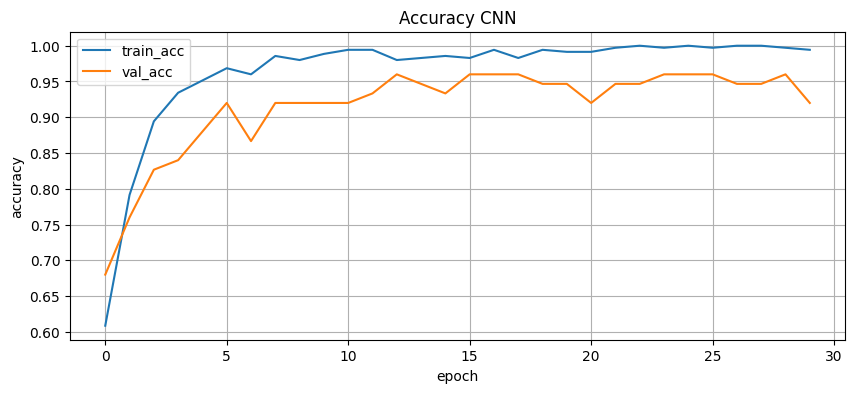

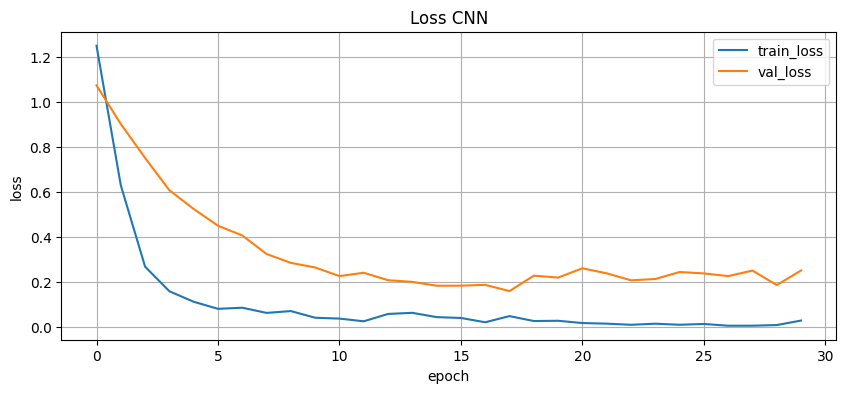

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 315ms/step
Accuracy: 0.9333
Classification report:
              precision    recall  f1-score   support

           0       1.00      0.93      0.97        15
           1       0.93      0.93      0.93        15
           2       0.93      0.93      0.93        15
           3       0.93      0.93      0.93        15
           4       0.88      0.93      0.90        15

    accuracy                           0.93        75
   macro avg       0.93      0.93      0.93        75
weighted avg       0.94      0.93      0.93        75



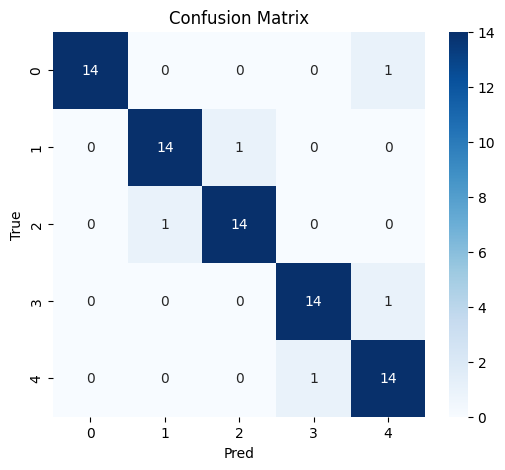

In [ ]:
X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t = dataset_gen_for_DL2(tr_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.3, split_r2=0.5)
Classif_CNN(X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

(400, 200, 8)
(50, 200, 8)
(50, 200, 8)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       204,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 217,701 (850.39 KB)

 Trainable params: 217,509 (849.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - accuracy: 0.5900 - loss: 1.4089 - val_accuracy: 0.5800 - val_loss: 1.0665
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.7650 - loss: 0.6963 - val_accuracy: 0.7000 - val_loss: 1.0142
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.8800 - loss: 0.3708 - val_accuracy: 0.7400 - val_loss: 0.8371
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9375 - loss: 0.1905 - val_accuracy: 0.8400 - val_loss: 0.7715
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9450 - loss: 0.1411 - val_accuracy: 0.7600 - val_loss: 0.6122
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9575 - loss: 0.1015 - val_accuracy: 0.8800 - val_loss: 0.5221
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9625 - loss: 0.0932 - val_accuracy: 0.8200 - val_loss: 0.5209
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9750 - loss: 0.0694 - val_accuracy: 0.

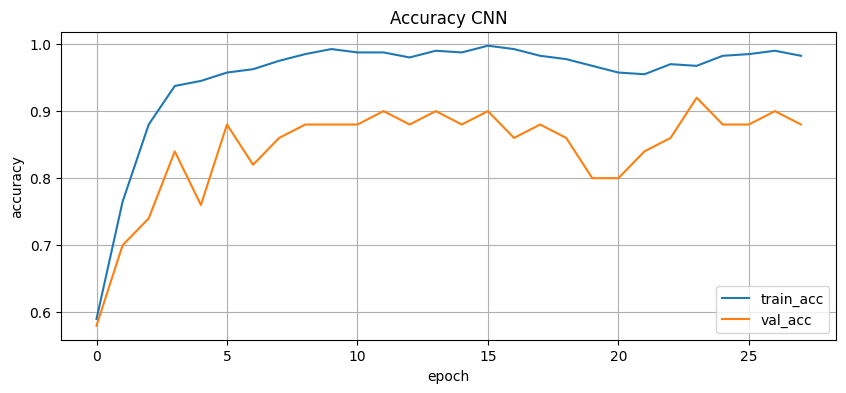

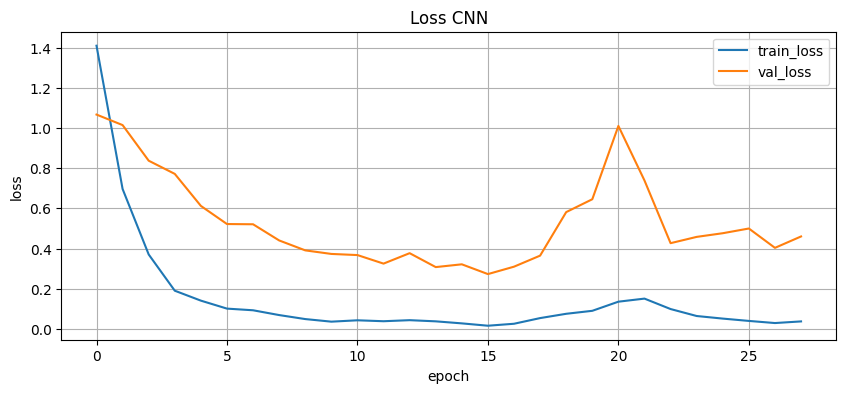

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
Accuracy: 0.9800
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00        10
           2       1.00      0.90      0.95        10
           3       1.00      1.00      1.00        10
           4       0.91      1.00      0.95        10

    accuracy                           0.98        50
   macro avg       0.98      0.98      0.98        50
weighted avg       0.98      0.98      0.98        50



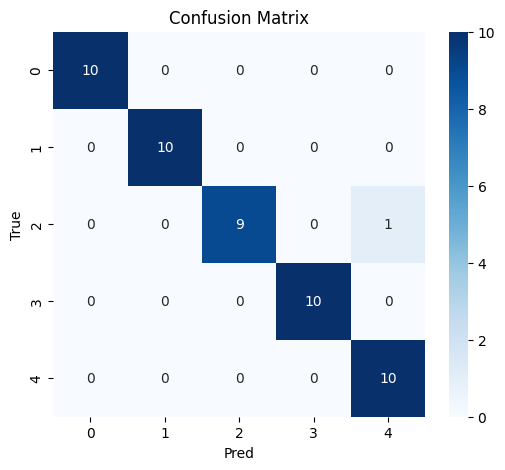

In [ ]:
X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t = dataset_gen_for_DL2(tr_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.2, split_r2=0.5)
Classif_CNN(X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

(375, 200, 8)
(62, 200, 8)
(63, 200, 8)


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_24 (Conv1D)              │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_24          │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_24 (MaxPooling1D) │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_25 (Conv1D)              │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_25          │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_25 (MaxPooling1D) │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 64)             │       204,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 217,701 (850.39 KB)

 Trainable params: 217,509 (849.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.6107 - loss: 1.3375 - val_accuracy: 0.5161 - val_loss: 1.0888
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8107 - loss: 0.5779 - val_accuracy: 0.6129 - val_loss: 1.1049
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9227 - loss: 0.2745 - val_accuracy: 0.6774 - val_loss: 0.9580
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9440 - loss: 0.1920 - val_accuracy: 0.7258 - val_loss: 0.8342
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.9573 - loss: 0.1280 - val_accuracy: 0.8065 - val_loss: 0.7552
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.9733 - loss: 0.0865 - val_accuracy: 0.7903 - val_loss: 0.6638
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.9840 - loss: 0.0670 - val_accuracy: 0.8226 - val_loss: 0.6104
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.9760 - loss: 0.0767 - val_accuracy: 0.

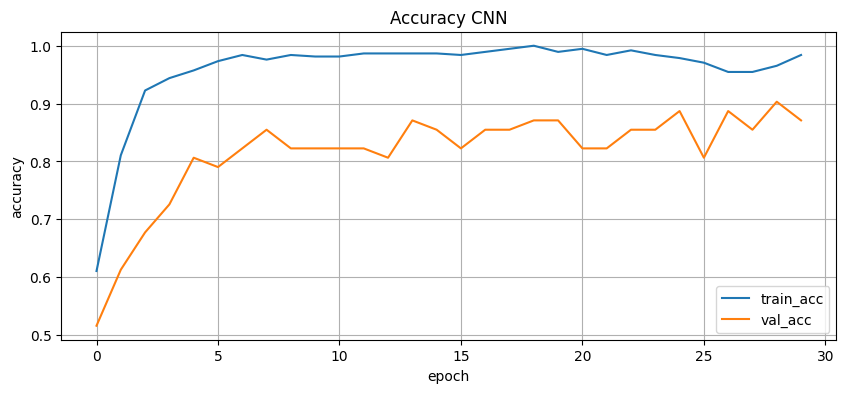

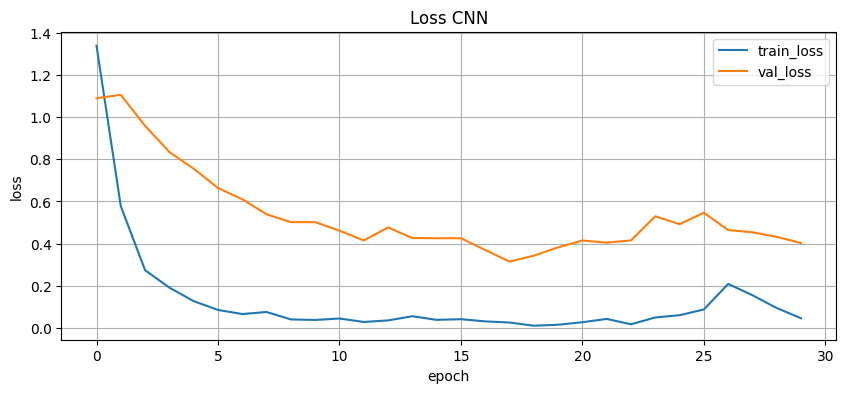

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
Accuracy: 0.9683
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.96        13
           2       1.00      0.92      0.96        13
           3       1.00      0.92      0.96        12
           4       0.93      1.00      0.96        13

    accuracy                           0.97        63
   macro avg       0.97      0.97      0.97        63
weighted avg       0.97      0.97      0.97        63



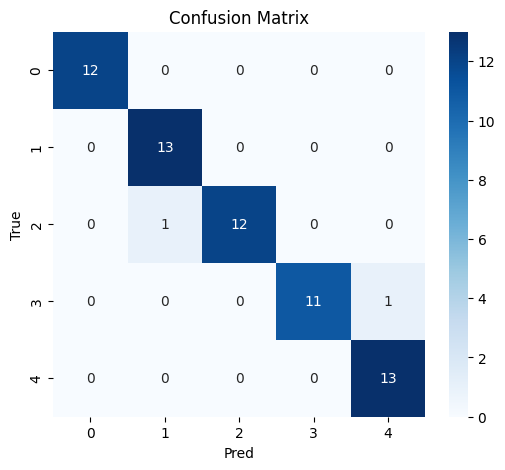

In [ ]:
X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t = dataset_gen_for_DL2(tr_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.25, split_r2=0.5)
Classif_CNN(X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

#### 2. Steady

(350, 300, 8)
(75, 300, 8)
(75, 300, 8)


Model: "sequential_33"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_77 (Conv1D)              │ (None, 300, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_77          │ (None, 300, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_72 (MaxPooling1D) │ (None, 150, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_78 (Conv1D)              │ (None, 150, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_78          │ (None, 150, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_73 (MaxPooling1D) │ (None, 75, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_87 (Dropout)            │ (None, 75, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_15 (Flatten)            │ (None, 4800)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_69 (Dense)                │ (None, 64)             │       307,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_88 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_70 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 320,101 (1.22 MB)

 Trainable params: 319,909 (1.22 MB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 11s 216ms/step - accuracy: 0.5714 - loss: 1.4485 - val_accuracy: 0.5067 - val_loss: 1.1597
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step - accuracy: 0.8143 - loss: 0.5727 - val_accuracy: 0.6933 - val_loss: 0.9704
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 190ms/step - accuracy: 0.9229 - loss: 0.3014 - val_accuracy: 0.6667 - val_loss: 0.8770
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 219ms/step - accuracy: 0.9314 - loss: 0.1839 - val_accuracy: 0.7733 - val_loss: 0.7099
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 172ms/step - accuracy: 0.9514 - loss: 0.1265 - val_accuracy: 0.8267 - val_loss: 0.6303
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 117ms/step - accuracy: 0.9686 - loss: 0.0830 - val_accuracy: 0.8133 - val_loss: 0.5822
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 111ms/step - accuracy: 0.9743 - loss: 0.0611 - val_accuracy: 0.8800 - val_loss: 0.4532
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step - accuracy: 0.9543 - loss: 0.1030 - val_acc

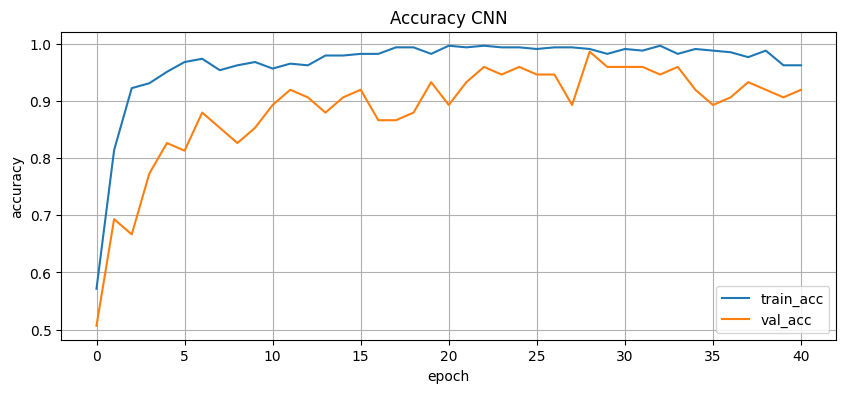

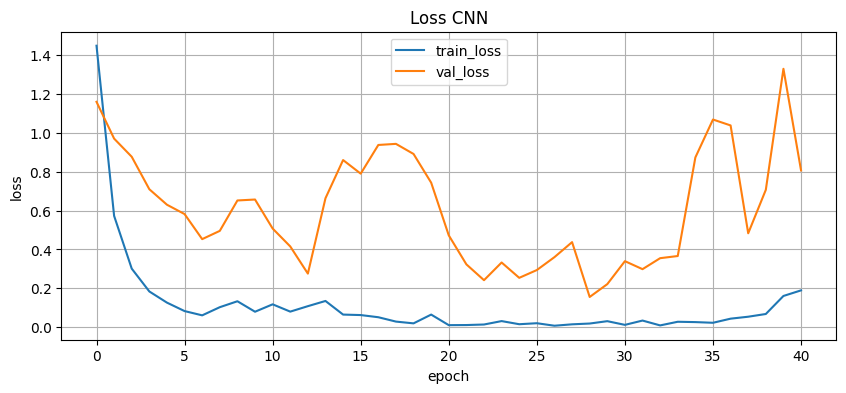

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 142ms/step
Accuracy: 0.8933
Classification report:
              precision    recall  f1-score   support

           0       1.00      0.93      0.97        15
           1       1.00      0.93      0.97        15
           2       0.93      0.87      0.90        15
           3       0.92      0.80      0.86        15
           4       0.70      0.93      0.80        15

    accuracy                           0.89        75
   macro avg       0.91      0.89      0.90        75
weighted avg       0.91      0.89      0.90        75



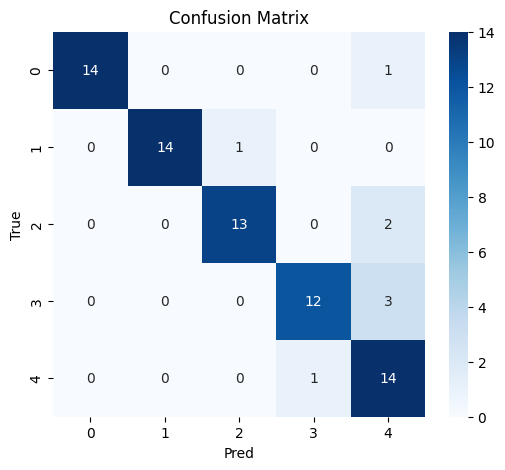

In [ ]:
X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st = dataset_gen_for_DL2(st_data_for_dl, 500, 5, time_steps=300, num_sensors=8, split_r1=0.3, split_r2=0.5)
Classif_CNN(X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st, epochs=100, b_size=32, time_steps=300, num_sensors=8, num_classes=5)

(400, 300, 8)
(50, 300, 8)
(50, 300, 8)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 300, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 300, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 150, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 150, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 150, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 75, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 75, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4800)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       307,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 320,101 (1.22 MB)

 Trainable params: 319,909 (1.22 MB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - accuracy: 0.5825 - loss: 1.5871 - val_accuracy: 0.3400 - val_loss: 1.6751
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.8025 - loss: 0.6178 - val_accuracy: 0.5600 - val_loss: 1.4396
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.8375 - loss: 0.4081 - val_accuracy: 0.7200 - val_loss: 1.3641
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.9150 - loss: 0.2000 - val_accuracy: 0.7600 - val_loss: 0.9597
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.9100 - loss: 0.1945 - val_accuracy: 0.7600 - val_loss: 0.8245
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.9450 - loss: 0.1528 - val_accuracy: 0.7600 - val_loss: 0.7860
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.9475 - loss: 0.1594 - val_accuracy: 0.8400 - val_loss: 0.6566
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.9775 - loss: 0.0910 - val_accuracy: 0.

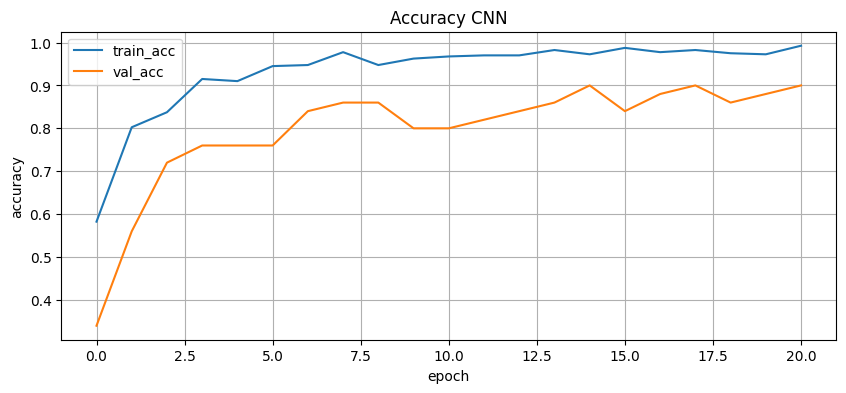

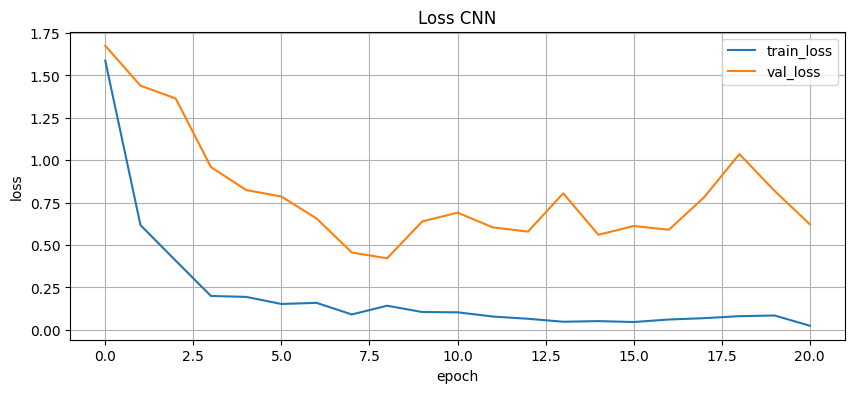

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 250ms/step
Accuracy: 0.9200
Classification report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95        10
           1       1.00      1.00      1.00        10
           2       0.80      0.80      0.80        10
           3       1.00      0.90      0.95        10
           4       0.90      0.90      0.90        10

    accuracy                           0.92        50
   macro avg       0.92      0.92      0.92        50
weighted avg       0.92      0.92      0.92        50



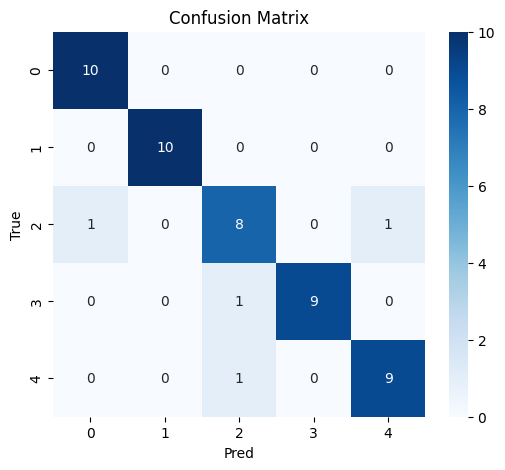

In [ ]:
X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st = dataset_gen_for_DL2(st_data_for_dl, 500, 5, time_steps=300, num_sensors=8, split_r1=0.2, split_r2=0.5)
Classif_CNN(X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st, epochs=100, b_size=32, time_steps=300, num_sensors=8, num_classes=5)

(375, 300, 8)
(62, 300, 8)
(63, 300, 8)


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_26 (Conv1D)              │ (None, 300, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_26          │ (None, 300, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_26 (MaxPooling1D) │ (None, 150, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_27 (Conv1D)              │ (None, 150, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_27          │ (None, 150, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_27 (MaxPooling1D) │ (None, 75, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_26 (Dropout)            │ (None, 75, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 4800)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 64)             │       307,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_27 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 320,101 (1.22 MB)

 Trainable params: 319,909 (1.22 MB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 101ms/step - accuracy: 0.5653 - loss: 1.4859 - val_accuracy: 0.4516 - val_loss: 1.2970
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.8347 - loss: 0.6502 - val_accuracy: 0.7097 - val_loss: 0.9248
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.8720 - loss: 0.4905 - val_accuracy: 0.7097 - val_loss: 0.8457
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.9307 - loss: 0.2365 - val_accuracy: 0.7903 - val_loss: 0.8375
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.9333 - loss: 0.2338 - val_accuracy: 0.7581 - val_loss: 0.7768
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9493 - loss: 0.1639 - val_accuracy: 0.8226 - val_loss: 0.7471
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9600 - loss: 0.1272 - val_accuracy: 0.8387 - val_loss: 0.4976
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9707 - loss: 0.0910 - val_accuracy: 0

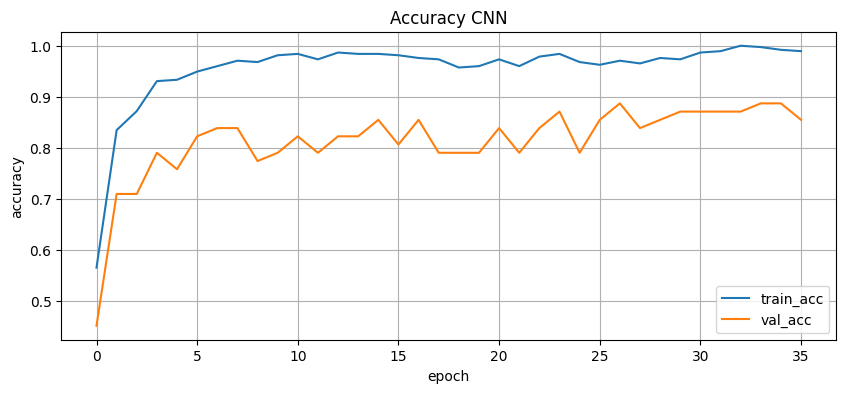

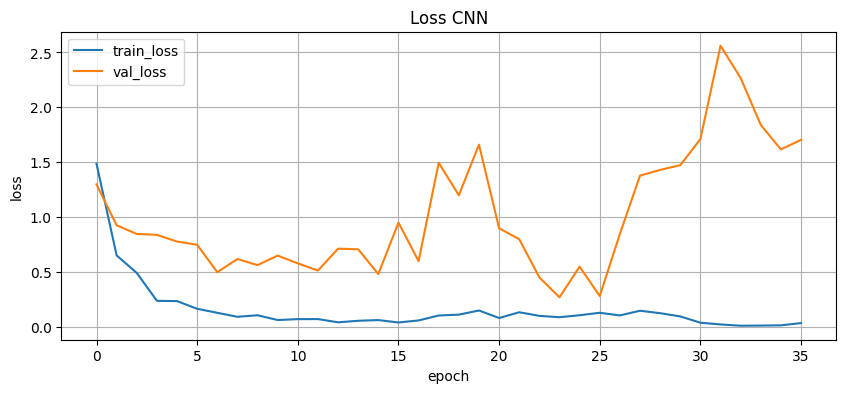

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
Accuracy: 0.9365
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.96        13
           2       0.86      0.92      0.89        13
           3       1.00      1.00      1.00        12
           4       0.91      0.77      0.83        13

    accuracy                           0.94        63
   macro avg       0.94      0.94      0.94        63
weighted avg       0.94      0.94      0.94        63



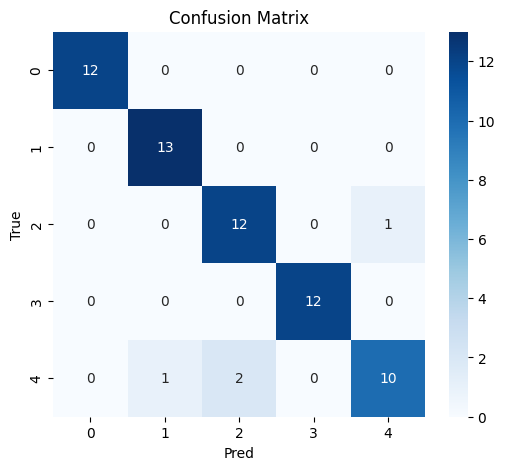

In [ ]:
X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st = dataset_gen_for_DL2(st_data_for_dl, 500, 5, time_steps=300, num_sensors=8, split_r1=0.25, split_r2=0.5)
Classif_CNN(X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st, epochs=100, b_size=32, time_steps=300, num_sensors=8, num_classes=5)

#### 3. After Steady

(350, 200, 8)
(75, 200, 8)
(75, 200, 8)


Model: "sequential_34"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_79 (Conv1D)              │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_79          │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_74 (MaxPooling1D) │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_80 (Conv1D)              │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_80          │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_75 (MaxPooling1D) │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_89 (Dropout)            │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_16 (Flatten)            │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_71 (Dense)                │ (None, 64)             │       204,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_90 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_72 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 217,701 (850.39 KB)

 Trainable params: 217,509 (849.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 258ms/step - accuracy: 0.6457 - loss: 1.0844 - val_accuracy: 0.6533 - val_loss: 0.9681
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - accuracy: 0.8857 - loss: 0.3994 - val_accuracy: 0.7200 - val_loss: 0.7701
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.9286 - loss: 0.1874 - val_accuracy: 0.8400 - val_loss: 0.5797
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step - accuracy: 0.9743 - loss: 0.0816 - val_accuracy: 0.9200 - val_loss: 0.4552
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 155ms/step - accuracy: 0.9657 - loss: 0.0774 - val_accuracy: 0.8933 - val_loss: 0.4193
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 119ms/step - accuracy: 0.9629 - loss: 0.1065 - val_accuracy: 0.9067 - val_loss: 0.3962
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - accuracy: 0.9886 - loss: 0.0319 - val_accuracy: 0.9467 - val_loss: 0.3418
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 118ms/step - accuracy: 0.9971 - loss: 0.0230 - val_accura

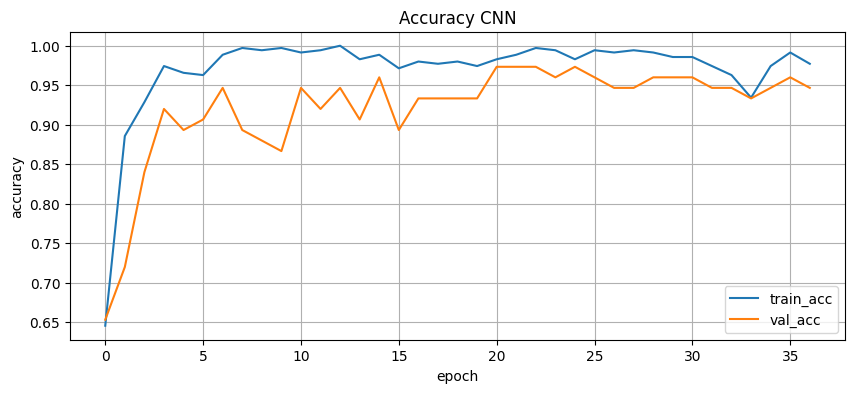

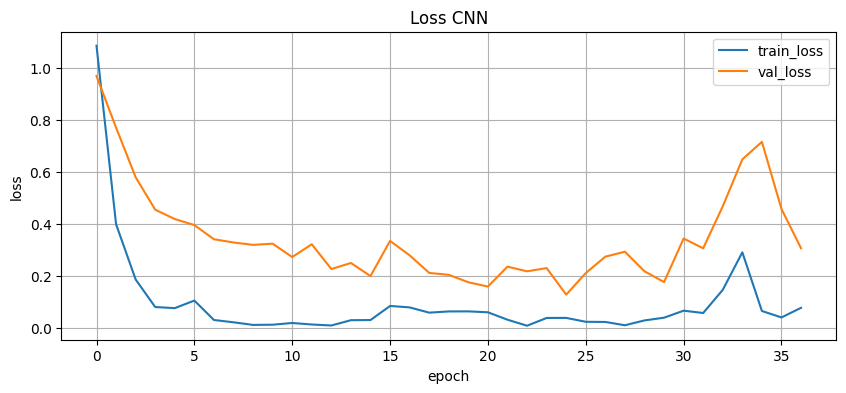

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
Accuracy: 0.9067
Classification report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        15
           1       1.00      0.80      0.89        15
           2       0.82      0.93      0.88        15
           3       0.88      1.00      0.94        15
           4       0.93      0.87      0.90        15

    accuracy                           0.91        75
   macro avg       0.91      0.91      0.91        75
weighted avg       0.91      0.91      0.91        75



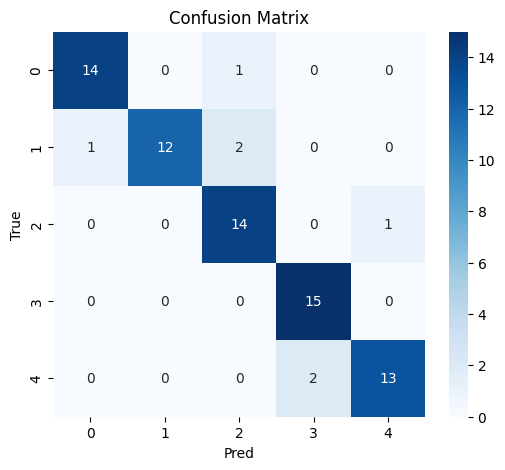

In [ ]:
X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs = dataset_gen_for_DL2(afs_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.3, split_r2=0.5)
Classif_CNN(X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

(400, 200, 8)
(50, 200, 8)
(50, 200, 8)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_4 (Conv1D)               │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_5 (MaxPooling1D)  │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       204,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 217,701 (850.39 KB)

 Trainable params: 217,509 (849.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - accuracy: 0.6100 - loss: 1.3378 - val_accuracy: 0.5000 - val_loss: 1.2152
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.8050 - loss: 0.6928 - val_accuracy: 0.7600 - val_loss: 1.0268
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.8650 - loss: 0.4552 - val_accuracy: 0.7000 - val_loss: 0.9937
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 85ms/step - accuracy: 0.9425 - loss: 0.1864 - val_accuracy: 0.8400 - val_loss: 0.7686
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.9425 - loss: 0.1679 - val_accuracy: 0.8800 - val_loss: 0.6506
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - accuracy: 0.9700 - loss: 0.1187 - val_accuracy: 0.8200 - val_loss: 0.6807
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step - accuracy: 0.9650 - loss: 0.1136 - val_accuracy: 0.8000 - val_loss: 0.6487
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 122ms/step - accuracy: 0.9650 - loss: 0.0907 - val_accuracy: 0

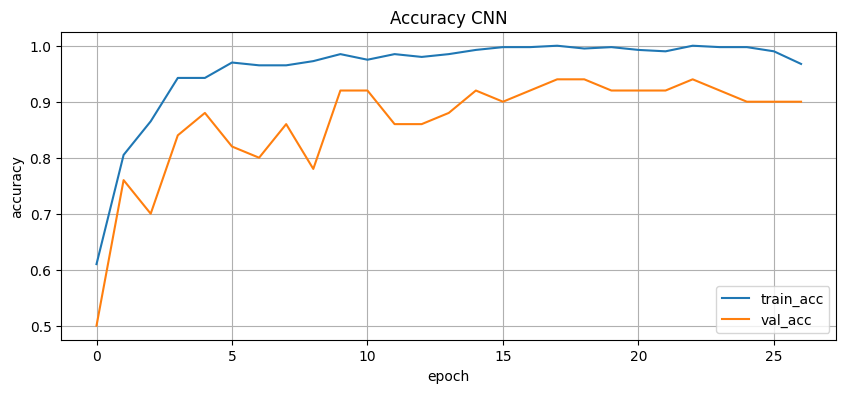

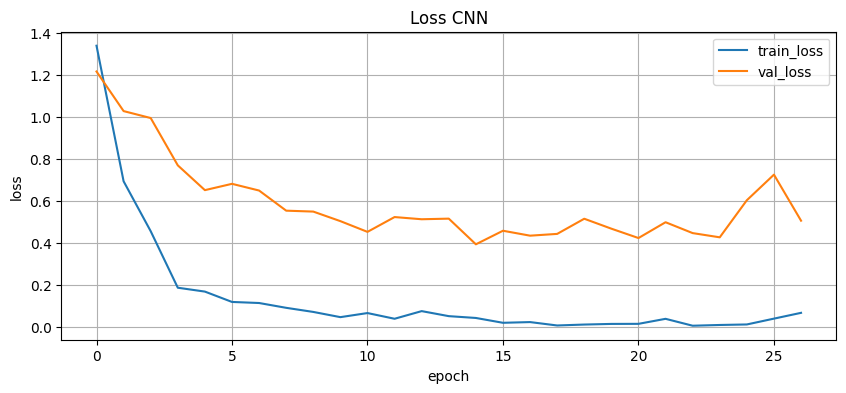

1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step
Accuracy: 0.9400
Classification report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95        10
           1       1.00      1.00      1.00        10
           2       1.00      0.80      0.89        10
           3       1.00      0.90      0.95        10
           4       0.83      1.00      0.91        10

    accuracy                           0.94        50
   macro avg       0.95      0.94      0.94        50
weighted avg       0.95      0.94      0.94        50



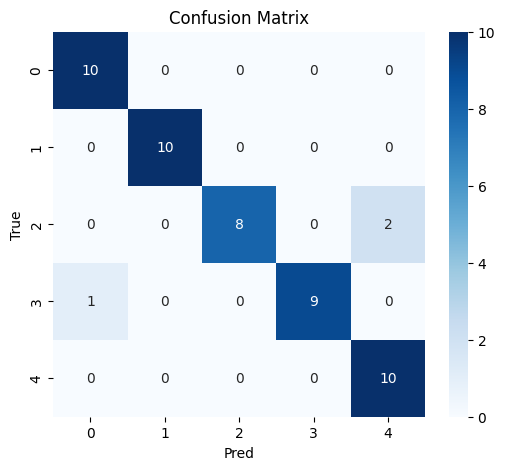

In [ ]:
X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs = dataset_gen_for_DL2(afs_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.2, split_r2=0.5)
Classif_CNN(X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

(375, 200, 8)
(62, 200, 8)
(63, 200, 8)


Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_28 (Conv1D)              │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_28          │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_28 (MaxPooling1D) │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_29 (Conv1D)              │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_29          │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_29 (MaxPooling1D) │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 64)             │       204,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_29 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 217,701 (850.39 KB)

 Trainable params: 217,509 (849.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - accuracy: 0.5333 - loss: 1.5611 - val_accuracy: 0.5000 - val_loss: 1.2441
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.8453 - loss: 0.5534 - val_accuracy: 0.5161 - val_loss: 1.3000
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.9120 - loss: 0.2810 - val_accuracy: 0.7097 - val_loss: 0.9565
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.9440 - loss: 0.1766 - val_accuracy: 0.7419 - val_loss: 0.8581
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.9680 - loss: 0.1114 - val_accuracy: 0.7258 - val_loss: 0.8851
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.9733 - loss: 0.0738 - val_accuracy: 0.7742 - val_loss: 0.8147
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.9787 - loss: 0.0560 - val_accuracy: 0.8226 - val_loss: 0.7127
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.9867 - loss: 0.0359 - val_accuracy: 0.

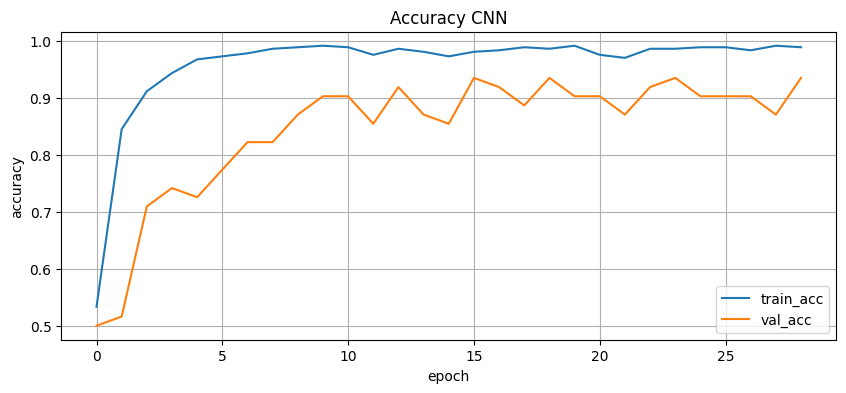

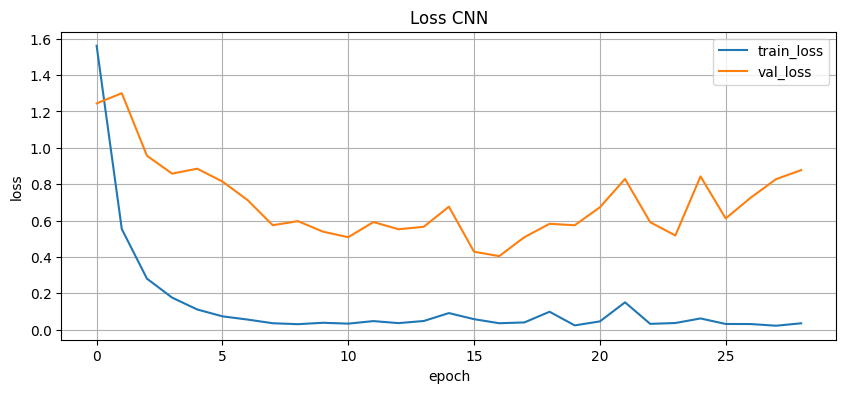

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
Accuracy: 0.9683
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.96        13
           2       1.00      0.92      0.96        13
           3       1.00      0.92      0.96        12
           4       0.93      1.00      0.96        13

    accuracy                           0.97        63
   macro avg       0.97      0.97      0.97        63
weighted avg       0.97      0.97      0.97        63



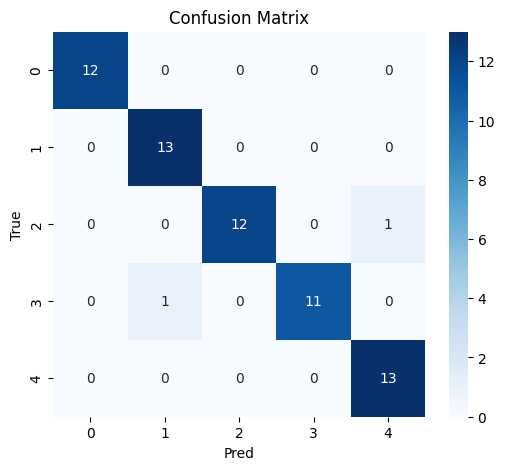

In [ ]:
X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs = dataset_gen_for_DL2(afs_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.25, split_r2=0.5)
Classif_CNN(X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

#### 4. Combined

(350, 700, 8)
(75, 700, 8)
(75, 700, 8)


Model: "sequential_35"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_81 (Conv1D)              │ (None, 700, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_81          │ (None, 700, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_76 (MaxPooling1D) │ (None, 350, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_82 (Conv1D)              │ (None, 350, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_82          │ (None, 350, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_77 (MaxPooling1D) │ (None, 175, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_91 (Dropout)            │ (None, 175, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_17 (Flatten)            │ (None, 11200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_73 (Dense)                │ (None, 64)             │       716,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_92 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_74 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 729,701 (2.78 MB)

 Trainable params: 729,509 (2.78 MB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 197ms/step - accuracy: 0.6029 - loss: 2.1395 - val_accuracy: 0.4933 - val_loss: 1.7925
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 197ms/step - accuracy: 0.7629 - loss: 1.0191 - val_accuracy: 0.6133 - val_loss: 1.0595
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 227ms/step - accuracy: 0.9000 - loss: 0.3237 - val_accuracy: 0.7333 - val_loss: 0.8604
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 142ms/step - accuracy: 0.9000 - loss: 0.2903 - val_accuracy: 0.8133 - val_loss: 0.7460
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 131ms/step - accuracy: 0.9371 - loss: 0.1533 - val_accuracy: 0.8267 - val_loss: 0.7401
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 137ms/step - accuracy: 0.9629 - loss: 0.0847 - val_accuracy: 0.8000 - val_loss: 0.6284
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - accuracy: 0.9657 - loss: 0.0886 - val_accuracy: 0.9067 - val_loss: 0.5357
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 0.9771 - loss: 0.0775 - val_accura

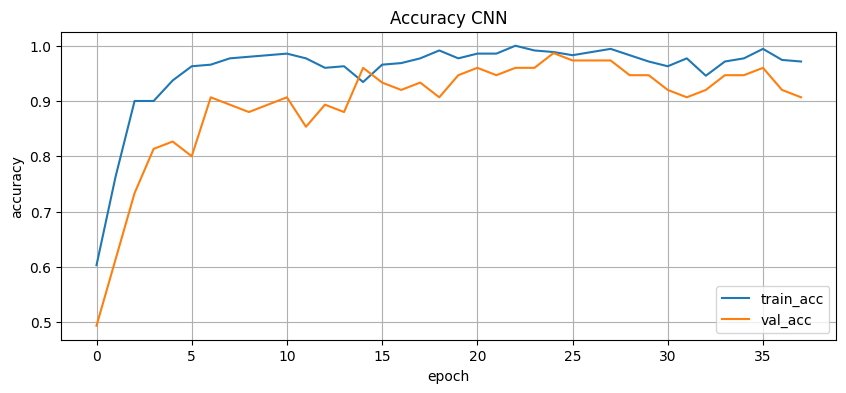

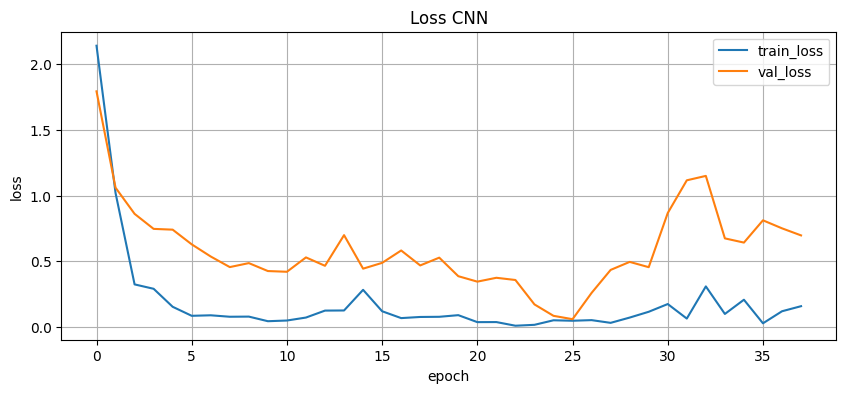

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
Accuracy: 0.9067
Classification report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        15
           1       1.00      0.93      0.97        15
           2       0.93      0.93      0.93        15
           3       0.88      1.00      0.94        15
           4       0.79      0.73      0.76        15

    accuracy                           0.91        75
   macro avg       0.91      0.91      0.91        75
weighted avg       0.91      0.91      0.91        75



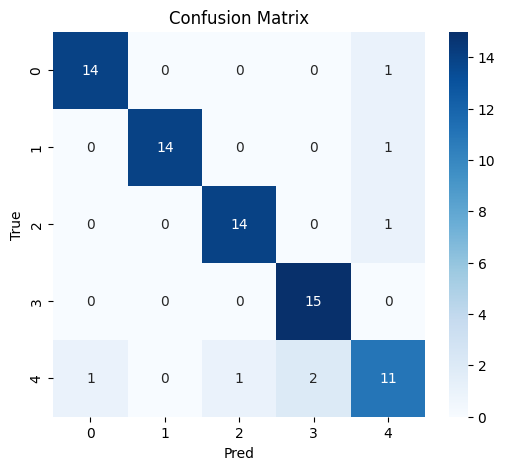

In [ ]:
X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb = dataset_gen_for_DL2(cmb_data_for_dl, 500, 5, time_steps=700, num_sensors=8, split_r1=0.3, split_r2=0.5)
Classif_CNN(X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb, epochs=100, b_size=32, time_steps=700, num_sensors=8, num_classes=5)

(400, 700, 8)
(50, 700, 8)
(50, 700, 8)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_6 (Conv1D)               │ (None, 700, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 700, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_6 (MaxPooling1D)  │ (None, 350, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 350, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 350, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_7 (MaxPooling1D)  │ (None, 175, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 175, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 11200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       716,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 729,701 (2.78 MB)

 Trainable params: 729,509 (2.78 MB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 168ms/step - accuracy: 0.6075 - loss: 1.7947 - val_accuracy: 0.5200 - val_loss: 1.5243
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 125ms/step - accuracy: 0.8050 - loss: 0.8953 - val_accuracy: 0.6600 - val_loss: 0.8962
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 197ms/step - accuracy: 0.8800 - loss: 0.4334 - val_accuracy: 0.7200 - val_loss: 1.2888
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 113ms/step - accuracy: 0.9250 - loss: 0.2422 - val_accuracy: 0.8200 - val_loss: 1.0985
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 111ms/step - accuracy: 0.9600 - loss: 0.1440 - val_accuracy: 0.8400 - val_loss: 1.0303
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - accuracy: 0.9600 - loss: 0.1361 - val_accuracy: 0.8800 - val_loss: 0.4620
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.9675 - loss: 0.1125 - val_accuracy: 0.8600 - val_loss: 0.4907
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.9700 - loss: 0.0977 - val_accurac

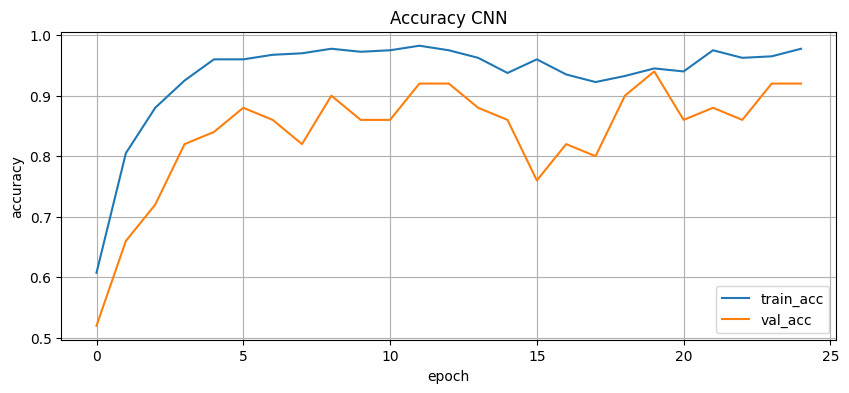

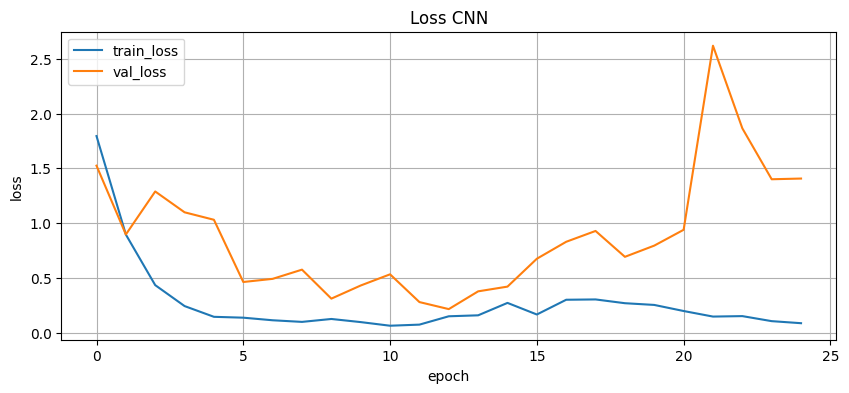

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 311ms/step
Accuracy: 0.9400
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00        10
           2       0.82      0.90      0.86        10
           3       1.00      0.90      0.95        10
           4       0.90      0.90      0.90        10

    accuracy                           0.94        50
   macro avg       0.94      0.94      0.94        50
weighted avg       0.94      0.94      0.94        50



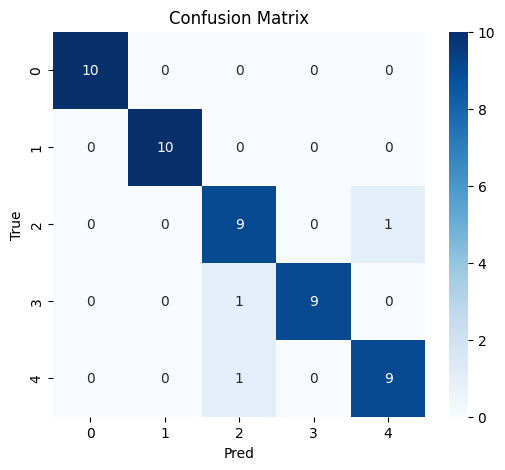

In [ ]:
X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb = dataset_gen_for_DL2(cmb_data_for_dl, 500, 5, time_steps=700, num_sensors=8, split_r1=0.2, split_r2=0.5)
Classif_CNN(X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb, epochs=100, b_size=32, time_steps=700, num_sensors=8, num_classes=5)

(375, 700, 8)
(62, 700, 8)
(63, 700, 8)


Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_30 (Conv1D)              │ (None, 700, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 700, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_30 (MaxPooling1D) │ (None, 350, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_31 (Conv1D)              │ (None, 350, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 350, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_31 (MaxPooling1D) │ (None, 175, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 175, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 11200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 64)             │       716,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_31 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 729,701 (2.78 MB)

 Trainable params: 729,509 (2.78 MB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 159ms/step - accuracy: 0.6187 - loss: 1.7669 - val_accuracy: 0.3871 - val_loss: 2.2577
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step - accuracy: 0.8373 - loss: 0.8700 - val_accuracy: 0.5484 - val_loss: 1.6667
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.8960 - loss: 0.4053 - val_accuracy: 0.5968 - val_loss: 1.8497
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.9360 - loss: 0.2107 - val_accuracy: 0.6935 - val_loss: 1.5729
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.9573 - loss: 0.1257 - val_accuracy: 0.7581 - val_loss: 1.3875
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.9680 - loss: 0.0728 - val_accuracy: 0.7097 - val_loss: 1.4293
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.9840 - loss: 0.0400 - val_accuracy: 0.8065 - val_loss: 1.3304
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.9680 - loss: 0.1405 - val_accuracy: 

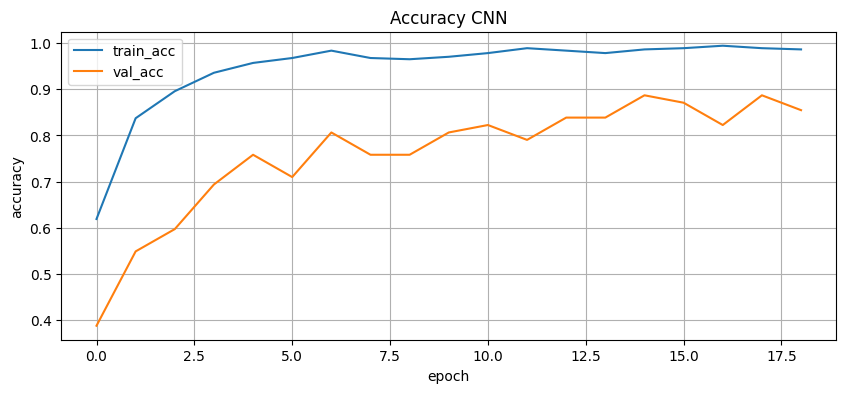

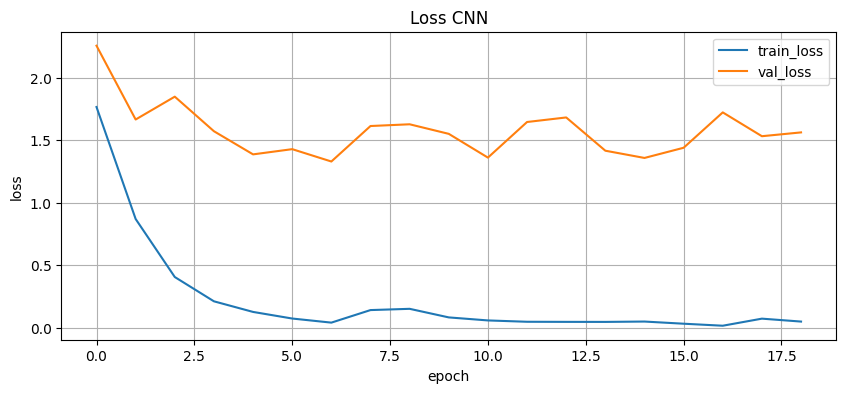

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
Accuracy: 0.8730
Classification report:
              precision    recall  f1-score   support

           0       0.75      1.00      0.86        12
           1       1.00      1.00      1.00        13
           2       0.89      0.62      0.73        13
           3       0.91      0.83      0.87        12
           4       0.86      0.92      0.89        13

    accuracy                           0.87        63
   macro avg       0.88      0.87      0.87        63
weighted avg       0.88      0.87      0.87        63



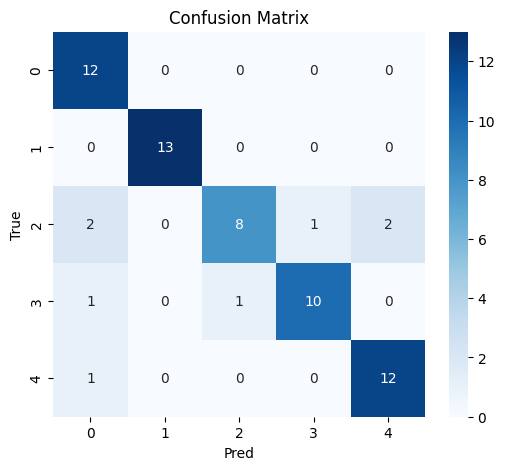

In [ ]:
X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb = dataset_gen_for_DL2(cmb_data_for_dl, 500, 5, time_steps=700, num_sensors=8, split_r1=0.25, split_r2=0.5)
Classif_CNN(X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb, epochs=100, b_size=32, time_steps=700, num_sensors=8, num_classes=5)

### **2. CNN + LSTM**

#### 1. Transient

(350, 200, 8)
(75, 200, 8)
(75, 200, 8)


Model: "sequential_36"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_83 (Conv1D)              │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_83          │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_78 (MaxPooling1D) │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_84 (Conv1D)              │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_84          │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_79 (MaxPooling1D) │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_93 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_75 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_94 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_76 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,021 (195.39 KB)

 Trainable params: 49,829 (194.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 248ms/step - accuracy: 0.4514 - loss: 1.3751 - val_accuracy: 0.4000 - val_loss: 1.4631
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 210ms/step - accuracy: 0.6686 - loss: 1.0405 - val_accuracy: 0.4933 - val_loss: 1.3326
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 160ms/step - accuracy: 0.7514 - loss: 0.8260 - val_accuracy: 0.5733 - val_loss: 1.2191
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 162ms/step - accuracy: 0.8200 - loss: 0.6215 - val_accuracy: 0.6800 - val_loss: 1.0452
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 205ms/step - accuracy: 0.8600 - loss: 0.4836 - val_accuracy: 0.7333 - val_loss: 0.8519
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 208ms/step - accuracy: 0.8714 - loss: 0.3985 - val_accuracy: 0.8267 - val_loss: 0.7068
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 154ms/step - accuracy: 0.9000 - loss: 0.3347 - val_accuracy: 0.8000 - val_loss: 0.5927
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 146ms/step - accuracy: 0.9057 - loss: 0.3041 - val_acc

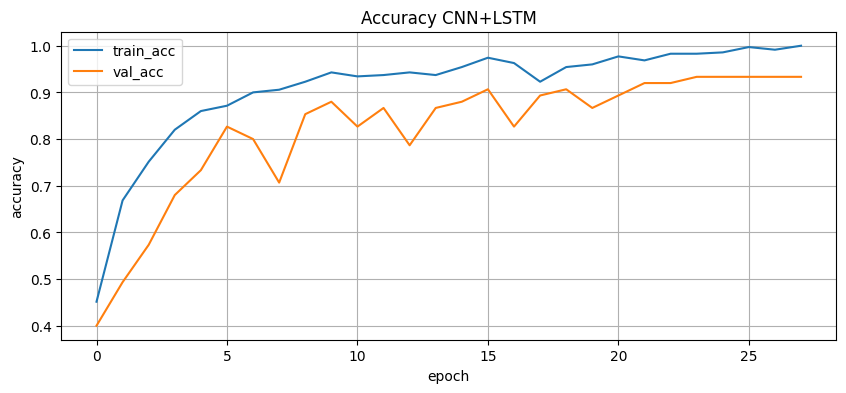

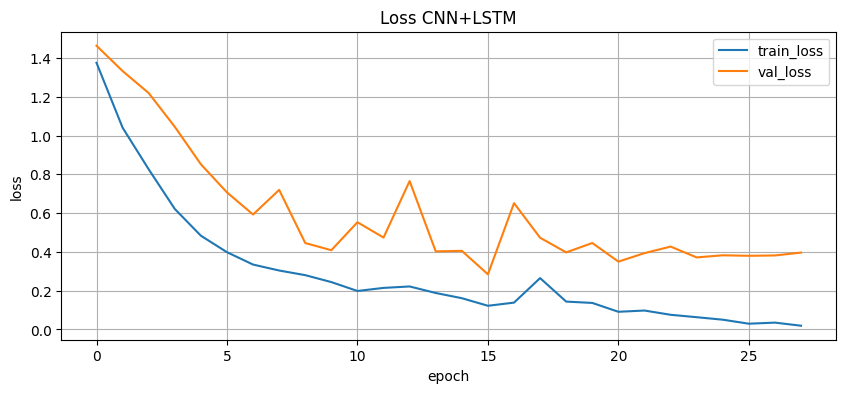

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 224ms/step
Accuracy: 0.8133
Classification report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        15
           1       0.93      0.87      0.90        15
           2       0.92      0.73      0.81        15
           3       0.71      0.67      0.69        15
           4       0.65      0.87      0.74        15

    accuracy                           0.81        75
   macro avg       0.83      0.81      0.82        75
weighted avg       0.83      0.81      0.82        75



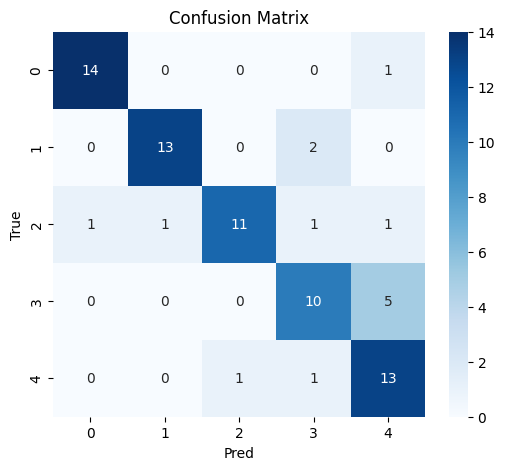

In [ ]:
X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t = dataset_gen_for_DL2(tr_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.3, split_r2=0.5)
Classif_CNN_LSTM(X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

(400, 200, 8)
(50, 200, 8)
(50, 200, 8)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_8 (Conv1D)               │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_8 (MaxPooling1D)  │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_9 (Conv1D)               │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_9 (MaxPooling1D)  │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,021 (195.39 KB)

 Trainable params: 49,829 (194.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 19s 253ms/step - accuracy: 0.3075 - loss: 1.5172 - val_accuracy: 0.5400 - val_loss: 1.4409
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 199ms/step - accuracy: 0.5925 - loss: 1.1443 - val_accuracy: 0.5800 - val_loss: 1.2764
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 270ms/step - accuracy: 0.6625 - loss: 0.9615 - val_accuracy: 0.6200 - val_loss: 1.1372
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 167ms/step - accuracy: 0.7375 - loss: 0.7701 - val_accuracy: 0.6800 - val_loss: 1.0401
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 134ms/step - accuracy: 0.8250 - loss: 0.6036 - val_accuracy: 0.6400 - val_loss: 0.9459
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 123ms/step - accuracy: 0.8575 - loss: 0.5124 - val_accuracy: 0.6800 - val_loss: 0.8585
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 123ms/step - accuracy: 0.8800 - loss: 0.4149 - val_accuracy: 0.7200 - val_loss: 0.7705
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 140ms/step - accuracy: 0.9200 - loss: 0.3261 - val_acc

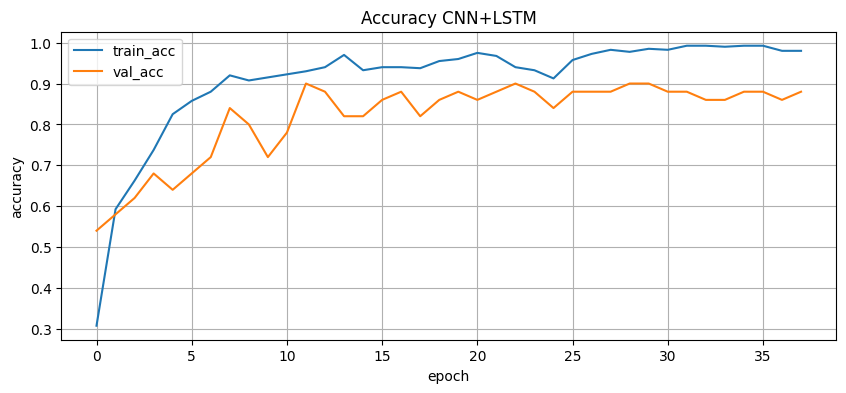

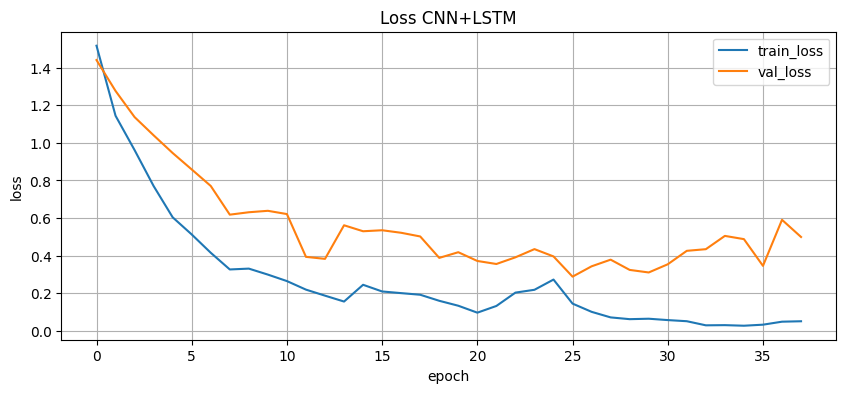

2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step
Accuracy: 0.9400
Classification report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95        10
           1       1.00      1.00      1.00        10
           2       0.82      0.90      0.86        10
           3       1.00      1.00      1.00        10
           4       1.00      0.80      0.89        10

    accuracy                           0.94        50
   macro avg       0.95      0.94      0.94        50
weighted avg       0.95      0.94      0.94        50



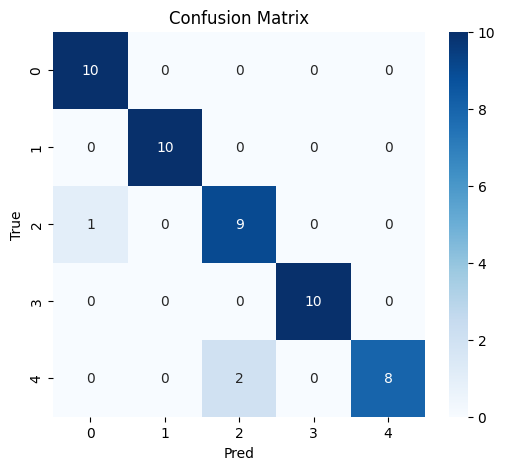

In [ ]:
X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t = dataset_gen_for_DL2(tr_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.2, split_r2=0.5)
Classif_CNN_LSTM(X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

(375, 200, 8)
(62, 200, 8)
(63, 200, 8)


Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_32 (Conv1D)              │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_32 (MaxPooling1D) │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_33 (Conv1D)              │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_33          │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_33 (MaxPooling1D) │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_32 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_33 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,021 (195.39 KB)

 Trainable params: 49,829 (194.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 88ms/step - accuracy: 0.3440 - loss: 1.5451 - val_accuracy: 0.4839 - val_loss: 1.5040
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - accuracy: 0.6187 - loss: 1.1688 - val_accuracy: 0.5484 - val_loss: 1.3374
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step - accuracy: 0.7093 - loss: 0.9304 - val_accuracy: 0.6613 - val_loss: 1.1851
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 0.7973 - loss: 0.7373 - val_accuracy: 0.6774 - val_loss: 1.0344
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - accuracy: 0.8613 - loss: 0.5419 - val_accuracy: 0.7581 - val_loss: 0.8663
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step - accuracy: 0.8880 - loss: 0.3964 - val_accuracy: 0.7742 - val_loss: 0.7187
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.8987 - loss: 0.3361 - val_accuracy: 0.7581 - val_loss: 0.6341
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.9333 - loss: 0.2688 - val_accuracy: 0.

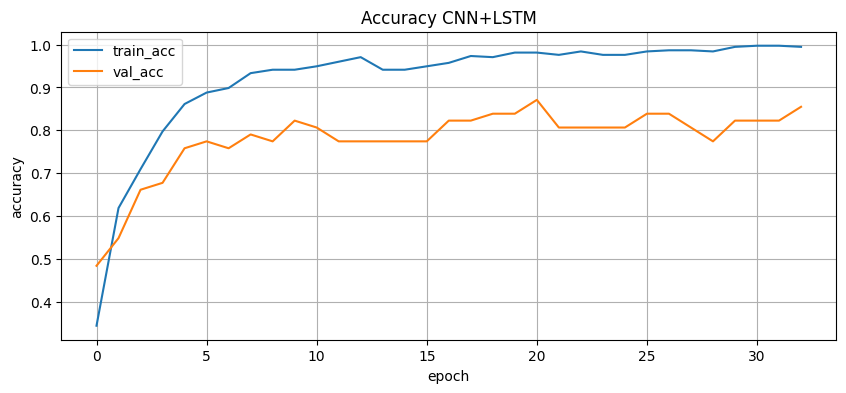

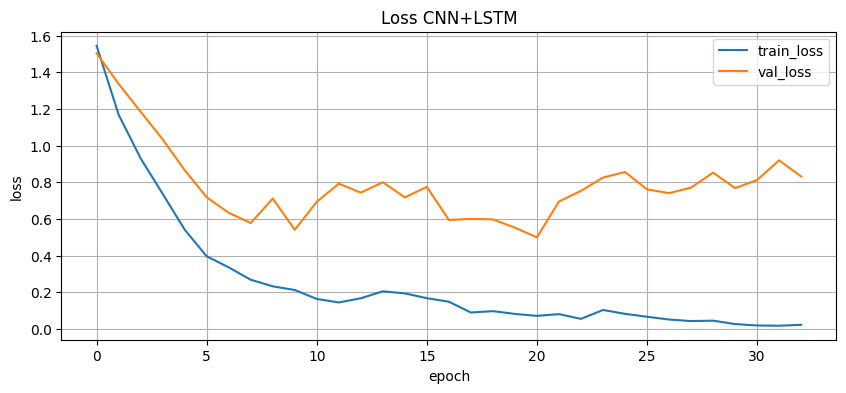

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 273ms/step
Accuracy: 1.0000
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13
           3       1.00      1.00      1.00        12
           4       1.00      1.00      1.00        13

    accuracy                           1.00        63
   macro avg       1.00      1.00      1.00        63
weighted avg       1.00      1.00      1.00        63



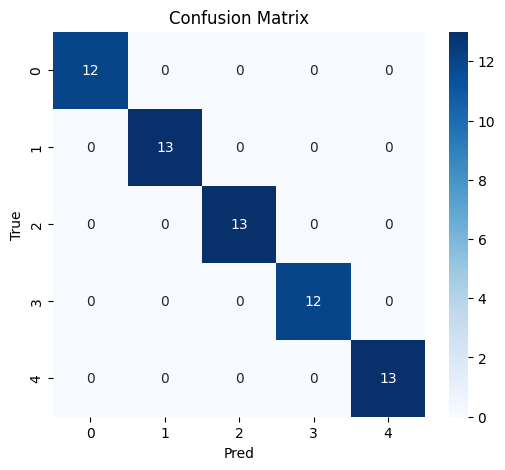

In [ ]:
X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t = dataset_gen_for_DL2(tr_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.25, split_r2=0.5)
Classif_CNN_LSTM(X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

#### 2. Steady

(350, 300, 8)
(75, 300, 8)
(75, 300, 8)


Model: "sequential_37"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_85 (Conv1D)              │ (None, 300, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_85          │ (None, 300, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_80 (MaxPooling1D) │ (None, 150, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_86 (Conv1D)              │ (None, 150, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_86          │ (None, 150, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_81 (MaxPooling1D) │ (None, 75, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_95 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_77 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_96 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_78 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,021 (195.39 KB)

 Trainable params: 49,829 (194.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 263ms/step - accuracy: 0.3114 - loss: 1.5278 - val_accuracy: 0.4267 - val_loss: 1.5030
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 250ms/step - accuracy: 0.6114 - loss: 1.1479 - val_accuracy: 0.5467 - val_loss: 1.3969
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 268ms/step - accuracy: 0.7286 - loss: 0.9282 - val_accuracy: 0.6533 - val_loss: 1.2826
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 235ms/step - accuracy: 0.8086 - loss: 0.7311 - val_accuracy: 0.7200 - val_loss: 1.1345
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 201ms/step - accuracy: 0.8600 - loss: 0.5710 - val_accuracy: 0.7467 - val_loss: 0.9793
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 184ms/step - accuracy: 0.9314 - loss: 0.4030 - val_accuracy: 0.8000 - val_loss: 0.7743
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 170ms/step - accuracy: 0.9343 - loss: 0.3058 - val_accuracy: 0.7733 - val_loss: 0.6931
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 203ms/step - accuracy: 0.9429 - loss: 0.2487 - val_acc

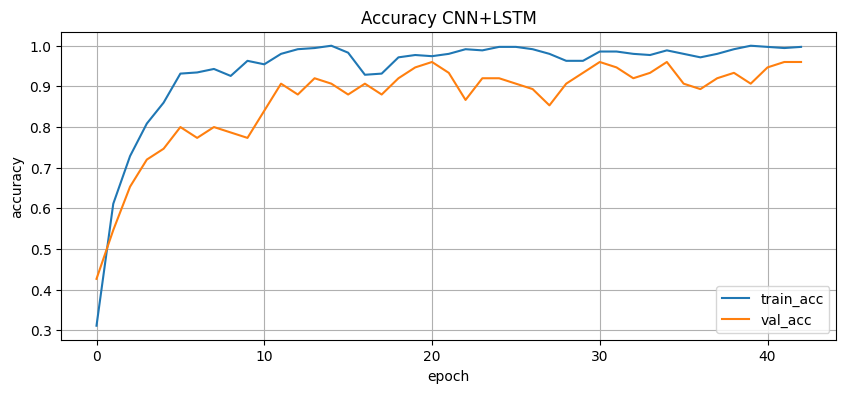

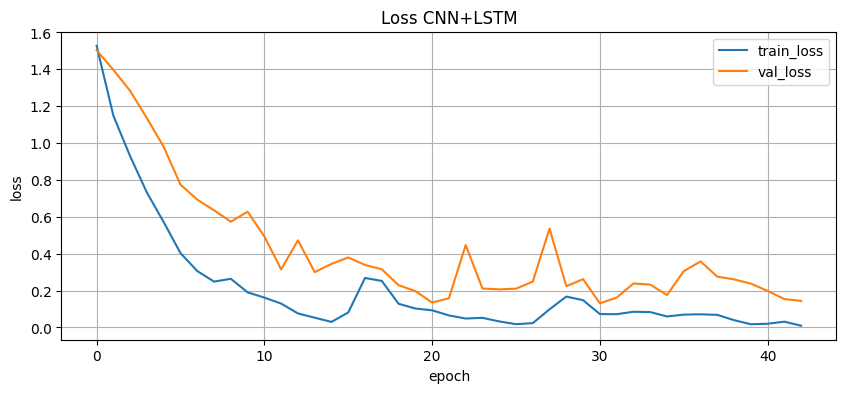

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 304ms/step
Accuracy: 0.8667
Classification report:
              precision    recall  f1-score   support

           0       1.00      0.93      0.97        15
           1       1.00      0.93      0.97        15
           2       0.93      0.93      0.93        15
           3       0.79      0.73      0.76        15
           4       0.67      0.80      0.73        15

    accuracy                           0.87        75
   macro avg       0.88      0.87      0.87        75
weighted avg       0.88      0.87      0.87        75



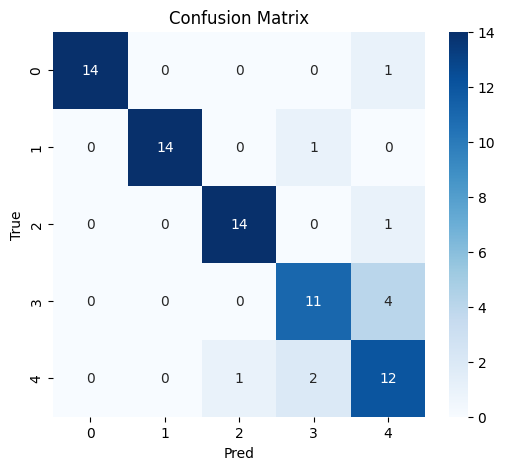

In [ ]:
X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st = dataset_gen_for_DL2(st_data_for_dl, 500, 5, time_steps=300, num_sensors=8, split_r1=0.3, split_r2=0.5)
Classif_CNN_LSTM(X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st, epochs=100, b_size=32, time_steps=300, num_sensors=8, num_classes=5)

(400, 300, 8)
(50, 300, 8)
(50, 300, 8)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_10 (Conv1D)              │ (None, 300, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 300, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_10 (MaxPooling1D) │ (None, 150, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_11 (Conv1D)              │ (None, 150, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 150, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_11 (MaxPooling1D) │ (None, 75, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,021 (195.39 KB)

 Trainable params: 49,829 (194.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 18s 269ms/step - accuracy: 0.3600 - loss: 1.4823 - val_accuracy: 0.5000 - val_loss: 1.4125
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 223ms/step - accuracy: 0.6200 - loss: 1.1125 - val_accuracy: 0.5400 - val_loss: 1.2912
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 206ms/step - accuracy: 0.6975 - loss: 0.8915 - val_accuracy: 0.7400 - val_loss: 1.1518
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 160ms/step - accuracy: 0.7600 - loss: 0.7277 - val_accuracy: 0.7600 - val_loss: 1.0056
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 179ms/step - accuracy: 0.8350 - loss: 0.5634 - val_accuracy: 0.7400 - val_loss: 0.8435
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 189ms/step - accuracy: 0.8875 - loss: 0.4393 - val_accuracy: 0.8200 - val_loss: 0.6752
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 170ms/step - accuracy: 0.9075 - loss: 0.3245 - val_accuracy: 0.7800 - val_loss: 0.5935
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 245ms/step - accuracy: 0.9275 - loss: 0.2527 - val_acc

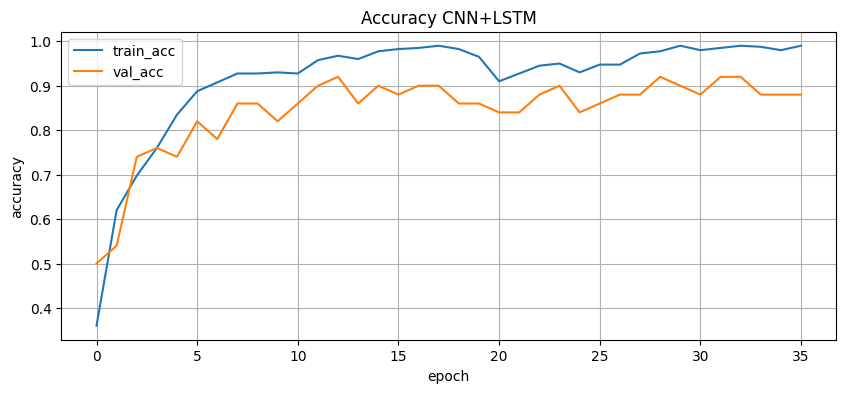

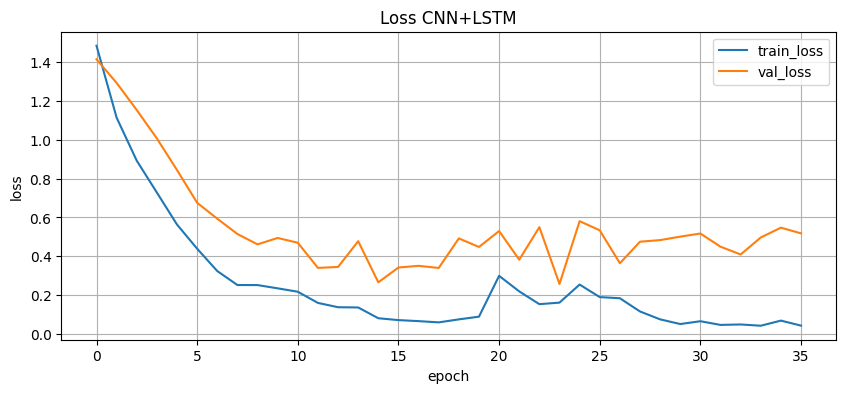

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 246ms/step
Accuracy: 0.9800
Classification report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95        10
           1       1.00      1.00      1.00        10
           2       1.00      0.90      0.95        10
           3       1.00      1.00      1.00        10
           4       1.00      1.00      1.00        10

    accuracy                           0.98        50
   macro avg       0.98      0.98      0.98        50
weighted avg       0.98      0.98      0.98        50



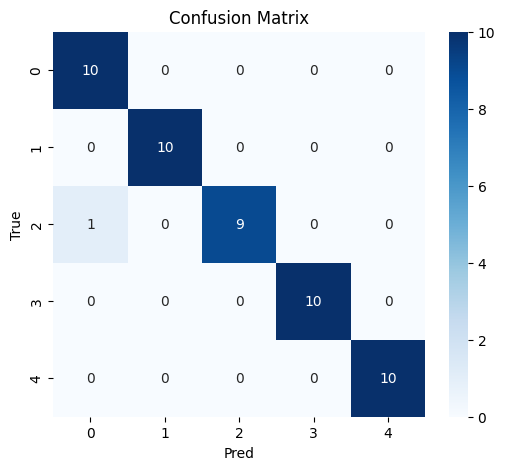

In [ ]:
X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st = dataset_gen_for_DL2(st_data_for_dl, 500, 5, time_steps=300, num_sensors=8, split_r1=0.2, split_r2=0.5)
Classif_CNN_LSTM(X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st, epochs=100, b_size=32, time_steps=300, num_sensors=8, num_classes=5)

(375, 300, 8)
(62, 300, 8)
(63, 300, 8)


Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_34 (Conv1D)              │ (None, 300, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_34          │ (None, 300, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_34 (MaxPooling1D) │ (None, 150, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_35 (Conv1D)              │ (None, 150, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_35          │ (None, 150, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_35 (MaxPooling1D) │ (None, 75, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_34 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_35 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,021 (195.39 KB)

 Trainable params: 49,829 (194.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 171ms/step - accuracy: 0.3467 - loss: 1.4952 - val_accuracy: 0.4677 - val_loss: 1.4897
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - accuracy: 0.6027 - loss: 1.1682 - val_accuracy: 0.5000 - val_loss: 1.3754
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.7147 - loss: 0.9374 - val_accuracy: 0.6129 - val_loss: 1.2380
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.7813 - loss: 0.7157 - val_accuracy: 0.6935 - val_loss: 1.1030
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.8693 - loss: 0.5463 - val_accuracy: 0.7419 - val_loss: 0.9352
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.9040 - loss: 0.4163 - val_accuracy: 0.7903 - val_loss: 0.8294
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.9253 - loss: 0.2976 - val_accuracy: 0.7903 - val_loss: 0.7658
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.9493 - loss: 0.2342 - val_accuracy: 

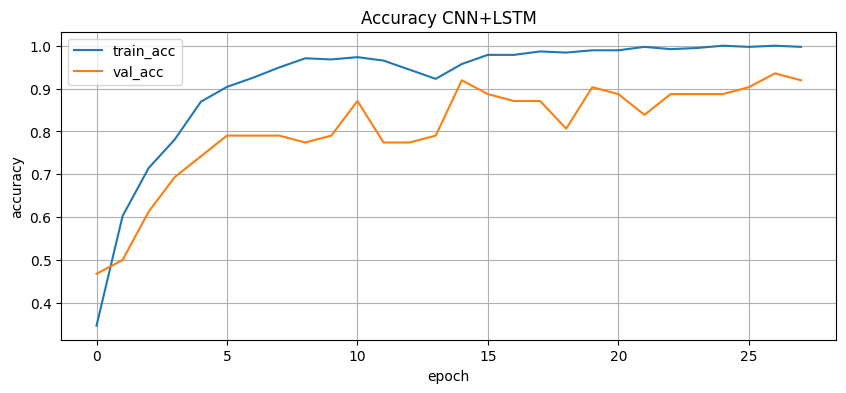

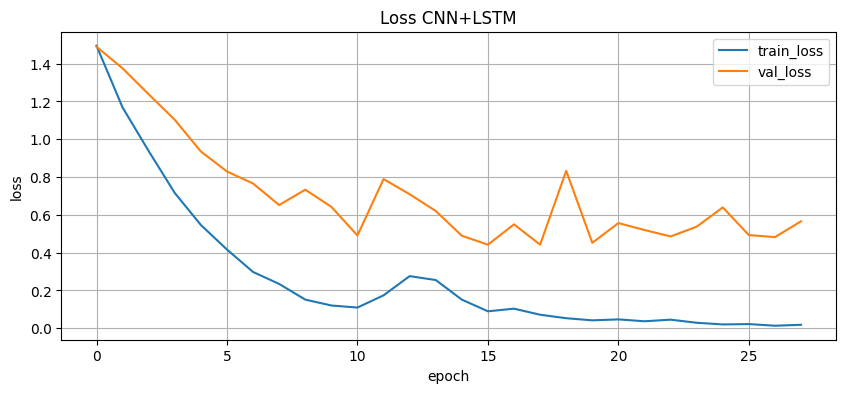

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 366ms/step
Accuracy: 0.9048
Classification report:
              precision    recall  f1-score   support

           0       0.92      0.92      0.92        12
           1       0.87      1.00      0.93        13
           2       0.92      0.92      0.92        13
           3       1.00      0.83      0.91        12
           4       0.85      0.85      0.85        13

    accuracy                           0.90        63
   macro avg       0.91      0.90      0.90        63
weighted avg       0.91      0.90      0.90        63



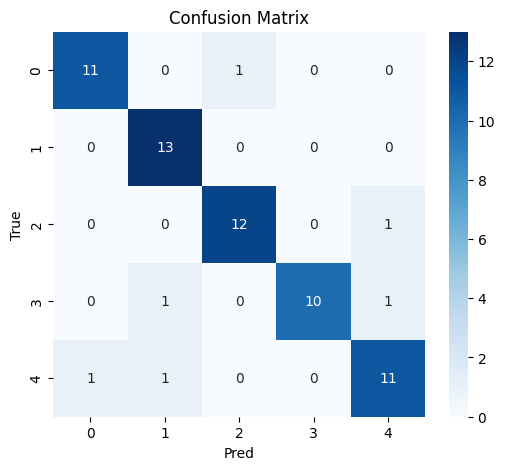

In [ ]:
X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st = dataset_gen_for_DL2(st_data_for_dl, 500, 5, time_steps=300, num_sensors=8, split_r1=0.25, split_r2=0.5)
Classif_CNN_LSTM(X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st, epochs=100, b_size=32, time_steps=300, num_sensors=8, num_classes=5)

#### 3. After Steady

(350, 200, 8)
(75, 200, 8)
(75, 200, 8)


Model: "sequential_38"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_87 (Conv1D)              │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_87          │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_82 (MaxPooling1D) │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_88 (Conv1D)              │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_88          │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_83 (MaxPooling1D) │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_97 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_79 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_98 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_80 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,021 (195.39 KB)

 Trainable params: 49,829 (194.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 271ms/step - accuracy: 0.3857 - loss: 1.5117 - val_accuracy: 0.4667 - val_loss: 1.4595
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 113ms/step - accuracy: 0.6200 - loss: 1.1822 - val_accuracy: 0.4933 - val_loss: 1.3477
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 189ms/step - accuracy: 0.7314 - loss: 0.9400 - val_accuracy: 0.6133 - val_loss: 1.2167
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 284ms/step - accuracy: 0.8286 - loss: 0.7141 - val_accuracy: 0.6933 - val_loss: 1.0637
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 254ms/step - accuracy: 0.9000 - loss: 0.5017 - val_accuracy: 0.7467 - val_loss: 0.9255
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 155ms/step - accuracy: 0.9343 - loss: 0.3669 - val_accuracy: 0.8267 - val_loss: 0.7582
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 141ms/step - accuracy: 0.9514 - loss: 0.2609 - val_accuracy: 0.8133 - val_loss: 0.6512
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 200ms/step - accuracy: 0.9629 - loss: 0.1906 - val_acc

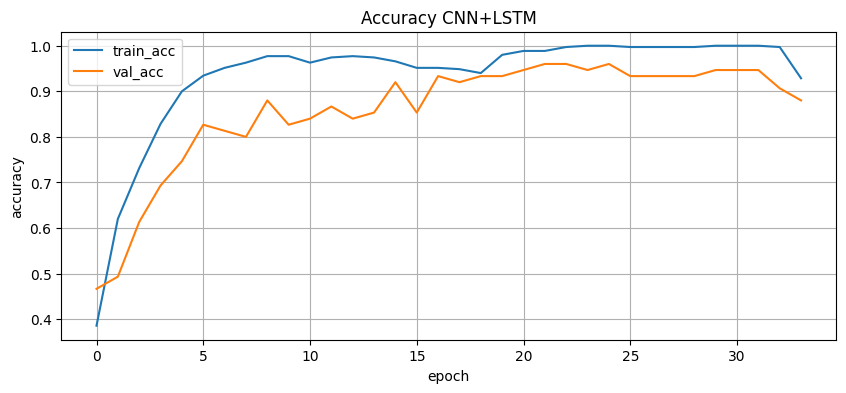

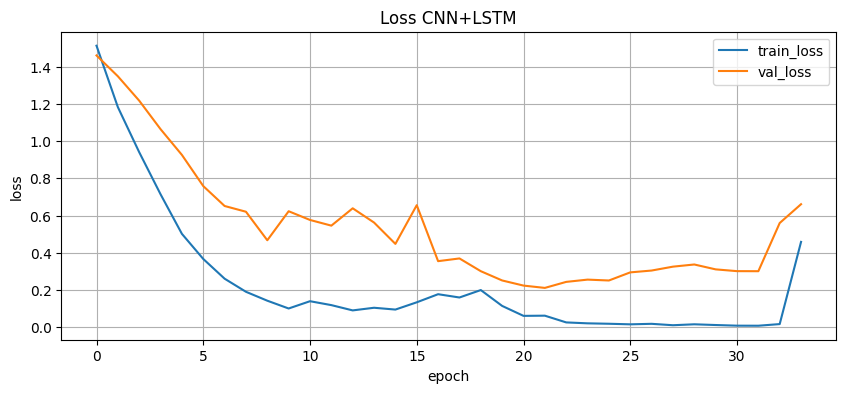

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 209ms/step
Accuracy: 0.9333
Classification report:
              precision    recall  f1-score   support

           0       1.00      0.93      0.97        15
           1       0.93      0.93      0.93        15
           2       0.93      0.93      0.93        15
           3       0.88      1.00      0.94        15
           4       0.93      0.87      0.90        15

    accuracy                           0.93        75
   macro avg       0.94      0.93      0.93        75
weighted avg       0.94      0.93      0.93        75



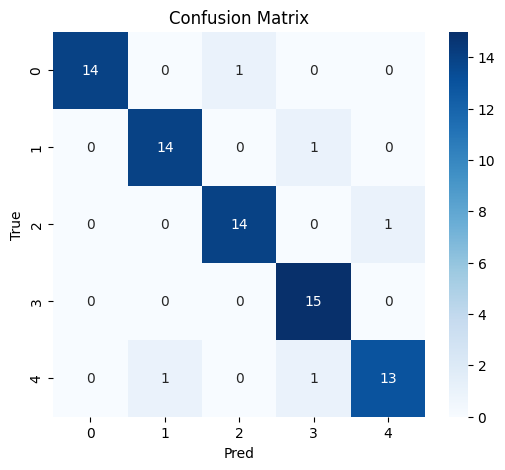

In [ ]:
X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs = dataset_gen_for_DL2(afs_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.3, split_r2=0.5)
Classif_CNN_LSTM(X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

(400, 200, 8)
(50, 200, 8)
(50, 200, 8)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_12 (Conv1D)              │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_12 (MaxPooling1D) │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_13 (Conv1D)              │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_13 (MaxPooling1D) │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,021 (195.39 KB)

 Trainable params: 49,829 (194.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 105ms/step - accuracy: 0.3250 - loss: 1.5107 - val_accuracy: 0.4600 - val_loss: 1.4872
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.6150 - loss: 1.1704 - val_accuracy: 0.6000 - val_loss: 1.3540
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.7650 - loss: 0.9030 - val_accuracy: 0.7600 - val_loss: 1.2304
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - accuracy: 0.8400 - loss: 0.6686 - val_accuracy: 0.8000 - val_loss: 1.0415
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step - accuracy: 0.9000 - loss: 0.4539 - val_accuracy: 0.8600 - val_loss: 0.8312
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - accuracy: 0.9225 - loss: 0.3500 - val_accuracy: 0.7600 - val_loss: 0.7304
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 0.9200 - loss: 0.3122 - val_accuracy: 0.8000 - val_loss: 0.6161
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - accuracy: 0.9300 - loss: 0.2634 - val_accuracy: 

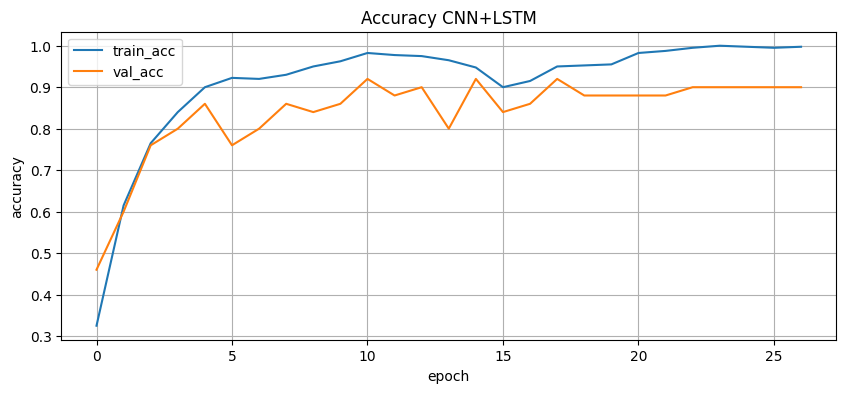

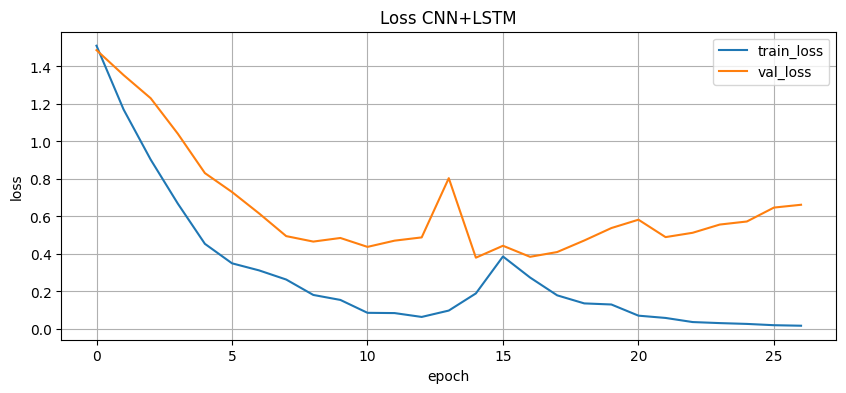

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 262ms/step
Accuracy: 0.8600
Classification report:
              precision    recall  f1-score   support

           0       0.83      1.00      0.91        10
           1       1.00      1.00      1.00        10
           2       0.73      0.80      0.76        10
           3       0.78      0.70      0.74        10
           4       1.00      0.80      0.89        10

    accuracy                           0.86        50
   macro avg       0.87      0.86      0.86        50
weighted avg       0.87      0.86      0.86        50



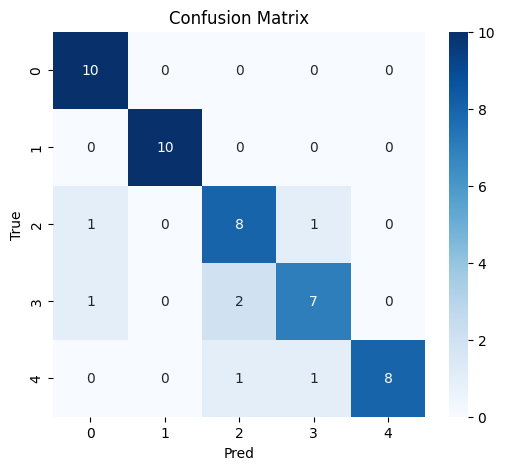

In [ ]:
X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs = dataset_gen_for_DL2(afs_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.2, split_r2=0.5)
Classif_CNN_LSTM(X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

(375, 200, 8)
(62, 200, 8)
(63, 200, 8)


Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_36 (Conv1D)              │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_36          │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_36 (MaxPooling1D) │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_37 (Conv1D)              │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_37          │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_37 (MaxPooling1D) │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_36 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_37 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,021 (195.39 KB)

 Trainable params: 49,829 (194.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 89ms/step - accuracy: 0.3173 - loss: 1.5015 - val_accuracy: 0.4677 - val_loss: 1.5060
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.5333 - loss: 1.1577 - val_accuracy: 0.6290 - val_loss: 1.3968
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.6587 - loss: 0.9045 - val_accuracy: 0.6774 - val_loss: 1.2727
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.7973 - loss: 0.6913 - val_accuracy: 0.7258 - val_loss: 1.1203
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.8427 - loss: 0.5469 - val_accuracy: 0.7258 - val_loss: 1.0044
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.8880 - loss: 0.3980 - val_accuracy: 0.7742 - val_loss: 0.8755
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.9307 - loss: 0.2783 - val_accuracy: 0.7581 - val_loss: 0.7533
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.9493 - loss: 0.2221 - val_accuracy: 0.

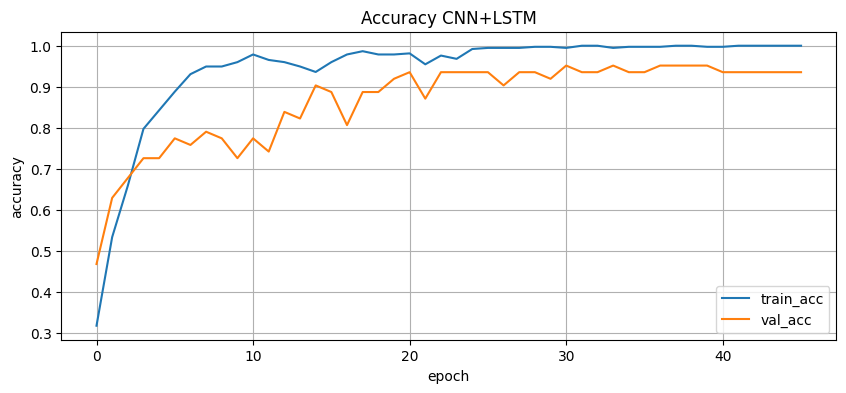

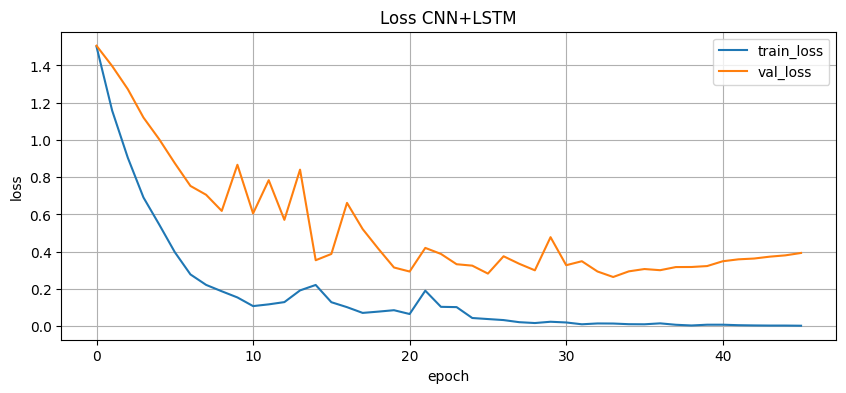

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step
Accuracy: 0.9683
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.96        13
           2       1.00      0.92      0.96        13
           3       1.00      0.92      0.96        12
           4       0.93      1.00      0.96        13

    accuracy                           0.97        63
   macro avg       0.97      0.97      0.97        63
weighted avg       0.97      0.97      0.97        63



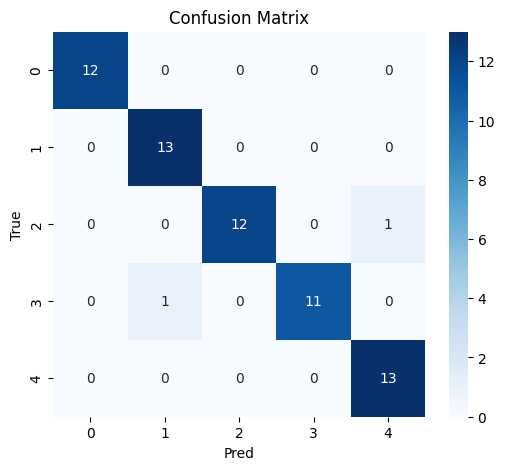

In [ ]:
X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs = dataset_gen_for_DL2(afs_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.25, split_r2=0.5)
Classif_CNN_LSTM(X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

#### 4. Combined

(350, 700, 8)
(75, 700, 8)
(75, 700, 8)


Model: "sequential_39"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_89 (Conv1D)              │ (None, 700, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_89          │ (None, 700, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_84 (MaxPooling1D) │ (None, 350, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_90 (Conv1D)              │ (None, 350, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_90          │ (None, 350, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_85 (MaxPooling1D) │ (None, 175, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_8 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_99 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_81 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_100 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_82 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,021 (195.39 KB)

 Trainable params: 49,829 (194.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 28s 853ms/step - accuracy: 0.3629 - loss: 1.5077 - val_accuracy: 0.4267 - val_loss: 1.5173
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 339ms/step - accuracy: 0.5943 - loss: 1.1568 - val_accuracy: 0.5067 - val_loss: 1.4185
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 606ms/step - accuracy: 0.7086 - loss: 0.9617 - val_accuracy: 0.6000 - val_loss: 1.2985
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 365ms/step - accuracy: 0.7971 - loss: 0.7369 - val_accuracy: 0.6400 - val_loss: 1.1499
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 460ms/step - accuracy: 0.8629 - loss: 0.5677 - val_accuracy: 0.7067 - val_loss: 0.9721
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 617ms/step - accuracy: 0.9057 - loss: 0.4096 - val_accuracy: 0.7067 - val_loss: 0.8289
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 365ms/step - accuracy: 0.9457 - loss: 0.2874 - val_accuracy: 0.6800 - val_loss: 0.7713
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 540ms/step - accuracy: 0.9429 - loss: 0.2241 - val_acc

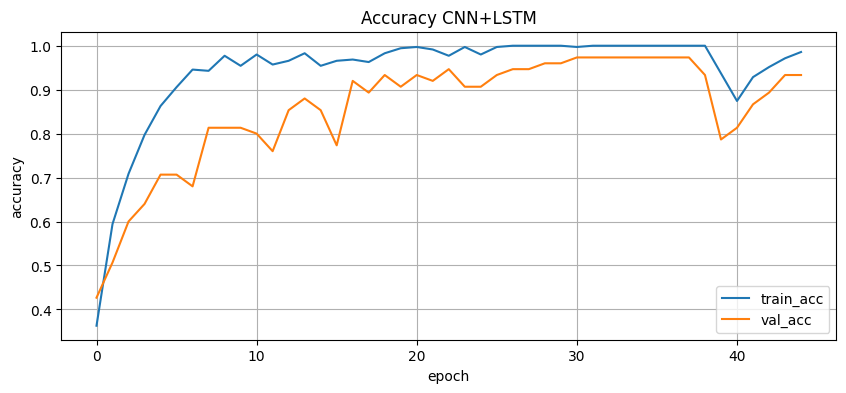

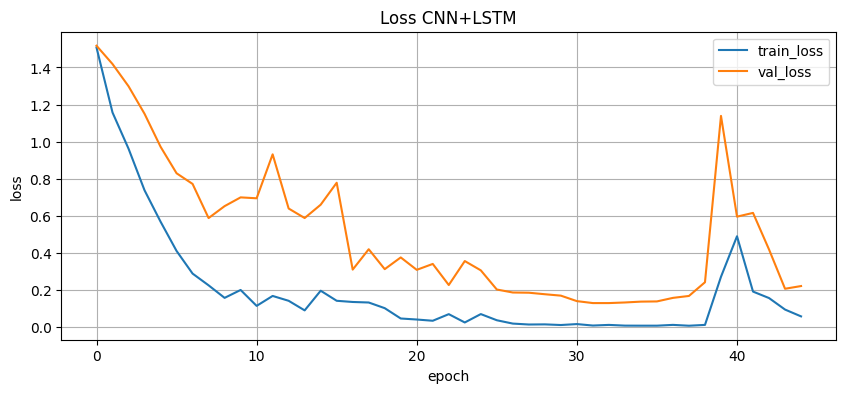

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 490ms/step
Accuracy: 0.9333
Classification report:
              precision    recall  f1-score   support

           0       1.00      0.93      0.97        15
           1       1.00      0.93      0.97        15
           2       0.93      0.93      0.93        15
           3       0.83      1.00      0.91        15
           4       0.93      0.87      0.90        15

    accuracy                           0.93        75
   macro avg       0.94      0.93      0.93        75
weighted avg       0.94      0.93      0.93        75



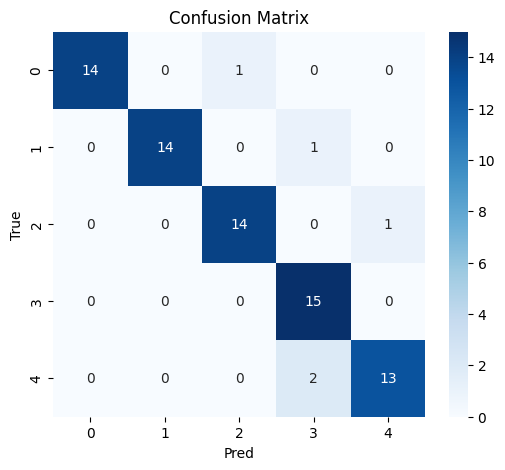

In [ ]:
X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb = dataset_gen_for_DL2(cmb_data_for_dl, 500, 5, time_steps=700, num_sensors=8, split_r1=0.3, split_r2=0.5)
Classif_CNN_LSTM(X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb, epochs=100, b_size=32, time_steps=700, num_sensors=8, num_classes=5)

(400, 700, 8)
(50, 700, 8)
(50, 700, 8)


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_14 (Conv1D)              │ (None, 700, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 700, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_14 (MaxPooling1D) │ (None, 350, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_15 (Conv1D)              │ (None, 350, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 350, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_15 (MaxPooling1D) │ (None, 175, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,021 (195.39 KB)

 Trainable params: 49,829 (194.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 407ms/step - accuracy: 0.3575 - loss: 1.5013 - val_accuracy: 0.5200 - val_loss: 1.4973
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 221ms/step - accuracy: 0.6200 - loss: 1.1516 - val_accuracy: 0.6200 - val_loss: 1.3703
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 265ms/step - accuracy: 0.7300 - loss: 0.9041 - val_accuracy: 0.7200 - val_loss: 1.2171
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 317ms/step - accuracy: 0.7675 - loss: 0.6966 - val_accuracy: 0.7800 - val_loss: 1.0637
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 238ms/step - accuracy: 0.8300 - loss: 0.5526 - val_accuracy: 0.7200 - val_loss: 0.9487
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 139ms/step - accuracy: 0.8875 - loss: 0.4415 - val_accuracy: 0.8200 - val_loss: 0.7474
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 135ms/step - accuracy: 0.8900 - loss: 0.3431 - val_accuracy: 0.7400 - val_loss: 0.6827
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 159ms/step - accuracy: 0.9125 - loss: 0.3082 - val_acc

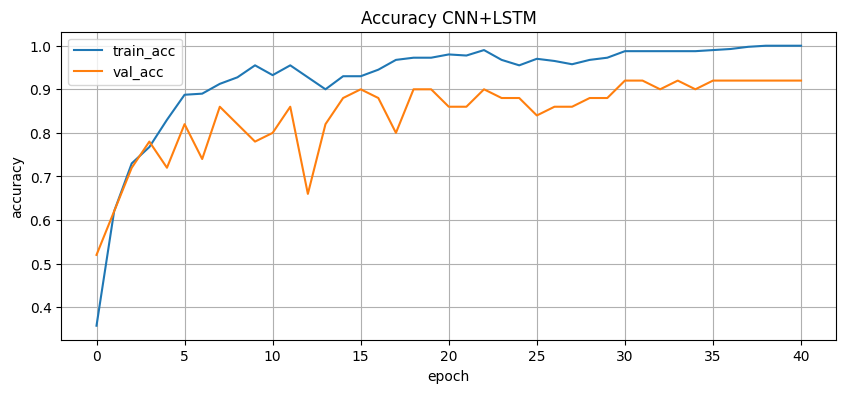

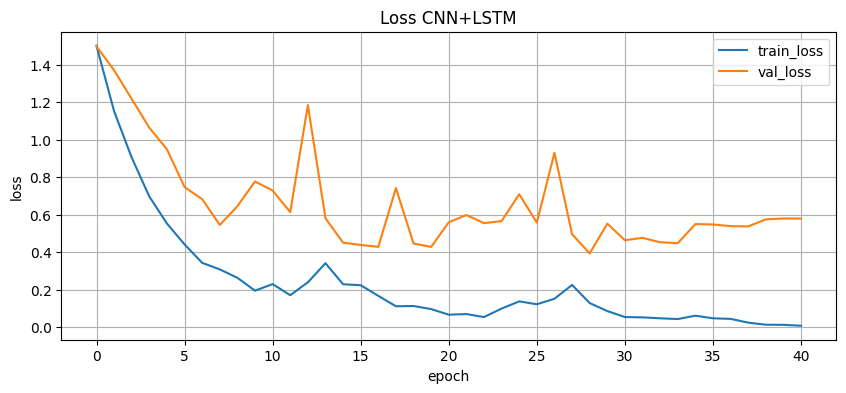

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 425ms/step
Accuracy: 0.8800
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.83      1.00      0.91        10
           2       0.82      0.90      0.86        10
           3       0.89      0.80      0.84        10
           4       0.88      0.70      0.78        10

    accuracy                           0.88        50
   macro avg       0.88      0.88      0.88        50
weighted avg       0.88      0.88      0.88        50



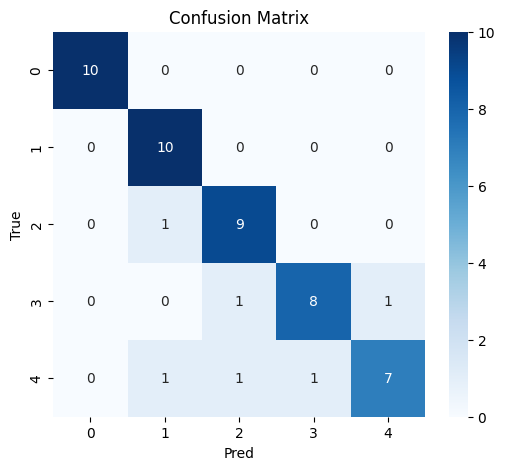

In [ ]:
X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb = dataset_gen_for_DL2(cmb_data_for_dl, 500, 5, time_steps=700, num_sensors=8, split_r1=0.2, split_r2=0.5)
Classif_CNN_LSTM(X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb, epochs=100, b_size=32, time_steps=700, num_sensors=8, num_classes=5)

(375, 700, 8)
(62, 700, 8)
(63, 700, 8)


Model: "sequential_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_38 (Conv1D)              │ (None, 700, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_38          │ (None, 700, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_38 (MaxPooling1D) │ (None, 350, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_39 (Conv1D)              │ (None, 350, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_39          │ (None, 350, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_39 (MaxPooling1D) │ (None, 175, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_38 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_39 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,021 (195.39 KB)

 Trainable params: 49,829 (194.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 179ms/step - accuracy: 0.3813 - loss: 1.4860 - val_accuracy: 0.3710 - val_loss: 1.4993
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 134ms/step - accuracy: 0.6080 - loss: 1.1441 - val_accuracy: 0.4839 - val_loss: 1.3775
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 133ms/step - accuracy: 0.6987 - loss: 0.9258 - val_accuracy: 0.5968 - val_loss: 1.2347
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 135ms/step - accuracy: 0.7867 - loss: 0.7040 - val_accuracy: 0.6935 - val_loss: 1.0789
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 198ms/step - accuracy: 0.8667 - loss: 0.5166 - val_accuracy: 0.6613 - val_loss: 0.9861
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 229ms/step - accuracy: 0.9173 - loss: 0.3565 - val_accuracy: 0.7419 - val_loss: 0.7927
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 133ms/step - accuracy: 0.9573 - loss: 0.2573 - val_accuracy: 0.8387 - val_loss: 0.6111
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 134ms/step - accuracy: 0.9600 - loss: 0.2083 - val_accu

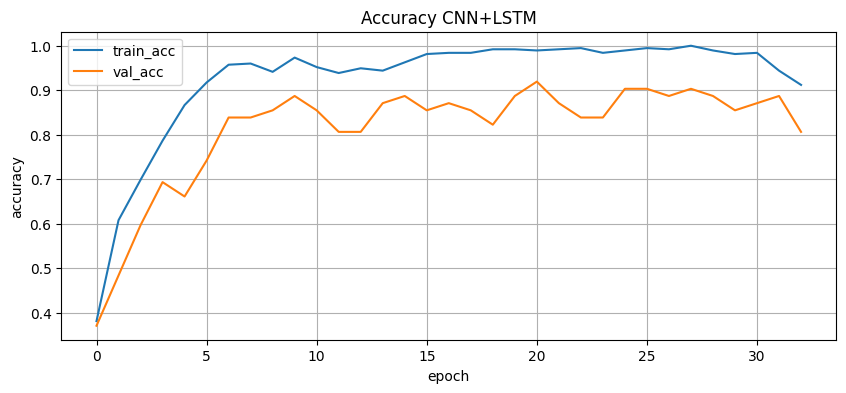

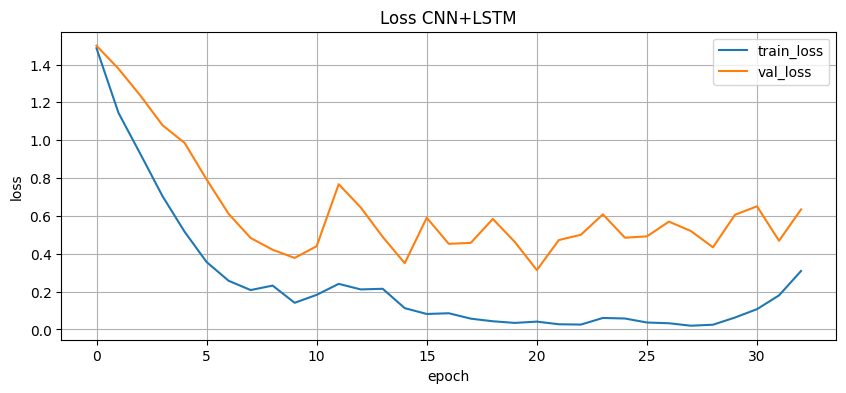

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 280ms/step
Accuracy: 0.9683
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.96        13
           2       1.00      0.92      0.96        13
           3       1.00      0.92      0.96        12
           4       0.93      1.00      0.96        13

    accuracy                           0.97        63
   macro avg       0.97      0.97      0.97        63
weighted avg       0.97      0.97      0.97        63



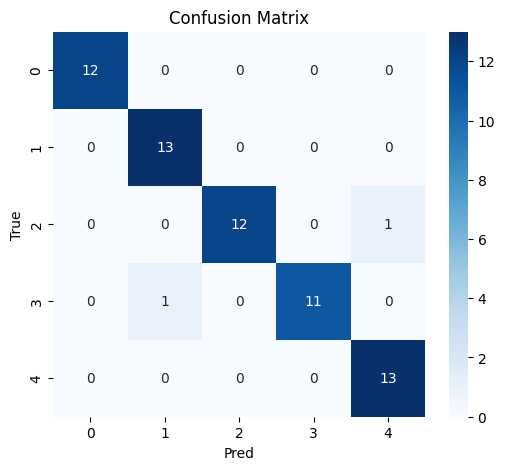

In [ ]:
X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb = dataset_gen_for_DL2(cmb_data_for_dl, 500, 5, time_steps=700, num_sensors=8, split_r1=0.25, split_r2=0.5)
Classif_CNN_LSTM(X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb, epochs=100, b_size=32, time_steps=700, num_sensors=8, num_classes=5)

### **3. CNN + BiGRU**

#### 1. Transient

(350, 200, 8)
(75, 200, 8)
(75, 200, 8)


Model: "sequential_40"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_91 (Conv1D)              │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_91          │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_86 (MaxPooling1D) │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_92 (Conv1D)              │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_92          │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_87 (MaxPooling1D) │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_16                │ (None, 128)            │        49,920 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_101 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_83 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_102 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_84 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,013 (277.39 KB)

 Trainable params: 70,821 (276.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 154ms/step - accuracy: 0.4200 - loss: 1.3714 - val_accuracy: 0.4533 - val_loss: 1.3428
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - accuracy: 0.6771 - loss: 0.8604 - val_accuracy: 0.5733 - val_loss: 1.2027
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 130ms/step - accuracy: 0.7571 - loss: 0.6368 - val_accuracy: 0.6400 - val_loss: 1.0994
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 272ms/step - accuracy: 0.8171 - loss: 0.5281 - val_accuracy: 0.6533 - val_loss: 1.0090
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 243ms/step - accuracy: 0.8943 - loss: 0.3912 - val_accuracy: 0.7333 - val_loss: 0.8970
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 160ms/step - accuracy: 0.9000 - loss: 0.3389 - val_accuracy: 0.7600 - val_loss: 0.8181
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 160ms/step - accuracy: 0.9029 - loss: 0.2951 - val_accuracy: 0.7600 - val_loss: 0.7481
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 151ms/step - accuracy: 0.9200 - loss: 0.2608 - val_accur

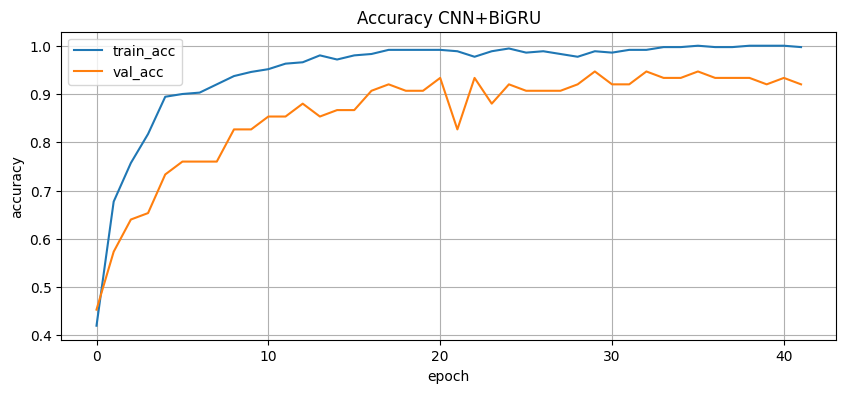

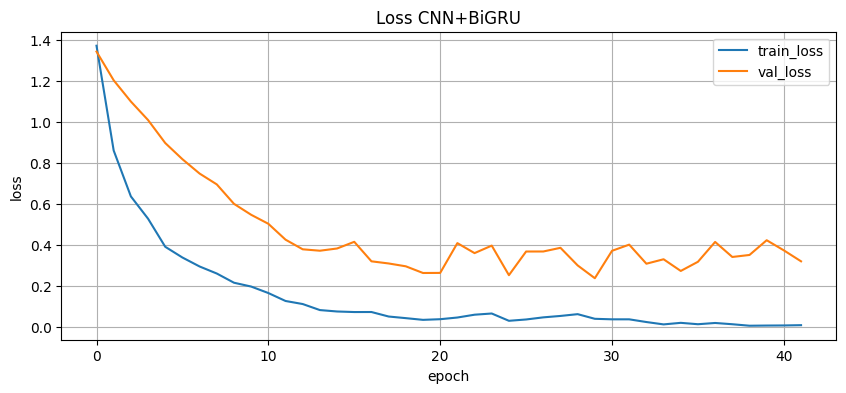

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 719ms/step
Accuracy: 0.8667
Classification report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        15
           1       0.93      0.87      0.90        15
           2       0.86      0.80      0.83        15
           3       0.79      1.00      0.88        15
           4       0.85      0.73      0.79        15

    accuracy                           0.87        75
   macro avg       0.87      0.87      0.87        75
weighted avg       0.87      0.87      0.87        75



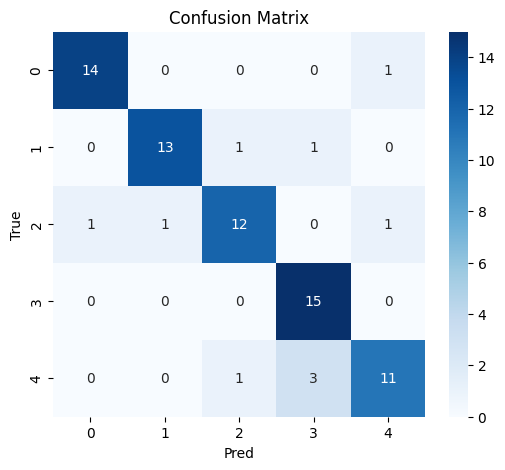

In [ ]:
X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t = dataset_gen_for_DL2(tr_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.3, split_r2=0.5)
Classif_CNN_BiGru(X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

(400, 200, 8)
(50, 200, 8)
(50, 200, 8)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_16 (Conv1D)              │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_16 (MaxPooling1D) │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_17 (Conv1D)              │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_17 (MaxPooling1D) │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        49,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,013 (277.39 KB)

 Trainable params: 70,821 (276.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 236ms/step - accuracy: 0.4000 - loss: 1.4409 - val_accuracy: 0.4600 - val_loss: 1.3695
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 131ms/step - accuracy: 0.6650 - loss: 0.9488 - val_accuracy: 0.5400 - val_loss: 1.2298
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - accuracy: 0.7575 - loss: 0.7087 - val_accuracy: 0.6400 - val_loss: 1.1437
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.8025 - loss: 0.5551 - val_accuracy: 0.7200 - val_loss: 1.0726
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step - accuracy: 0.8475 - loss: 0.4784 - val_accuracy: 0.7600 - val_loss: 0.9720
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - accuracy: 0.8675 - loss: 0.3985 - val_accuracy: 0.7600 - val_loss: 0.9150
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 84ms/step - accuracy: 0.8875 - loss: 0.3414 - val_accuracy: 0.7200 - val_loss: 0.8384
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 159ms/step - accuracy: 0.9325 - loss: 0.2631 - val_accuracy

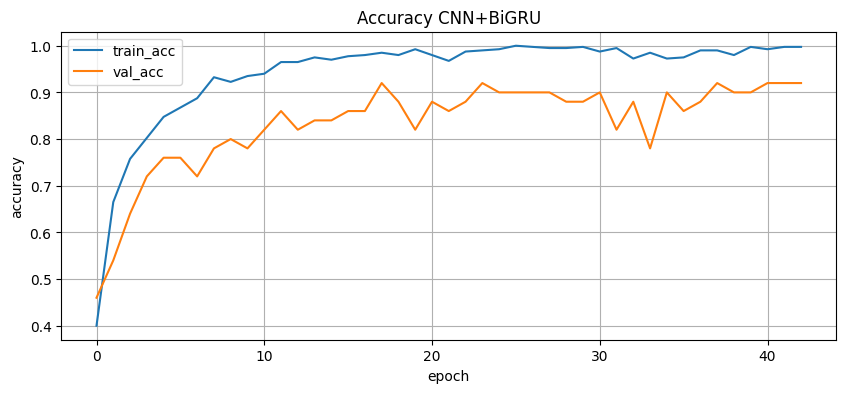

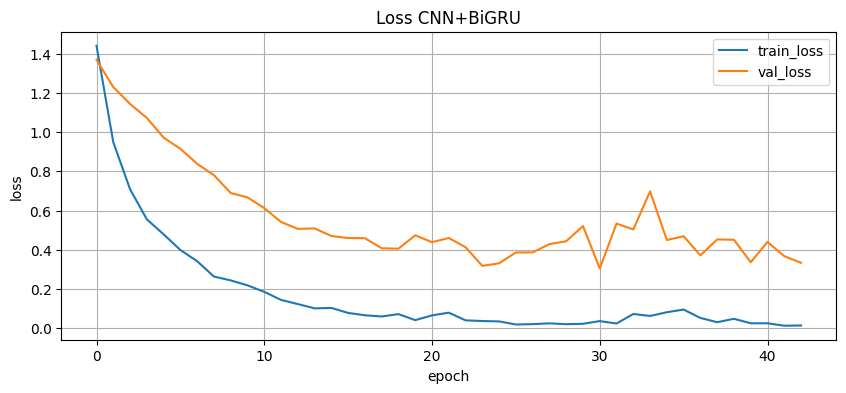

2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 3s/step
Accuracy: 0.9400
Classification report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95        10
           1       1.00      1.00      1.00        10
           2       0.82      0.90      0.86        10
           3       1.00      1.00      1.00        10
           4       1.00      0.80      0.89        10

    accuracy                           0.94        50
   macro avg       0.95      0.94      0.94        50
weighted avg       0.95      0.94      0.94        50



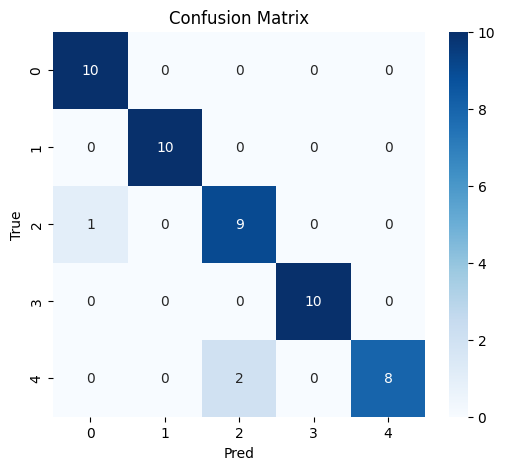

In [ ]:
X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t = dataset_gen_for_DL2(tr_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.2, split_r2=0.5)
Classif_CNN_BiGru(X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

(375, 200, 8)
(62, 200, 8)
(63, 200, 8)


Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_40 (Conv1D)              │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_40          │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_40 (MaxPooling1D) │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_41 (Conv1D)              │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_41          │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_41 (MaxPooling1D) │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 128)            │        49,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_40 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_41 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,013 (277.39 KB)

 Trainable params: 70,821 (276.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 9s 181ms/step - accuracy: 0.3920 - loss: 1.4513 - val_accuracy: 0.5323 - val_loss: 1.3903
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.6560 - loss: 0.8854 - val_accuracy: 0.5968 - val_loss: 1.2418
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 0.7787 - loss: 0.6404 - val_accuracy: 0.6935 - val_loss: 1.1297
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - accuracy: 0.8240 - loss: 0.5221 - val_accuracy: 0.7258 - val_loss: 1.0461
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.8800 - loss: 0.3892 - val_accuracy: 0.7903 - val_loss: 0.9332
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 0.9040 - loss: 0.3132 - val_accuracy: 0.7903 - val_loss: 0.8099
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - accuracy: 0.9307 - loss: 0.2378 - val_accuracy: 0.8065 - val_loss: 0.7503
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.9547 - loss: 0.1869 - val_accuracy: 0

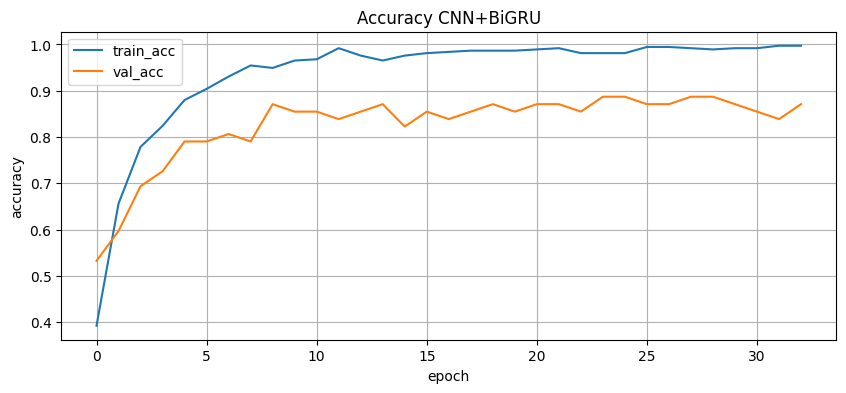

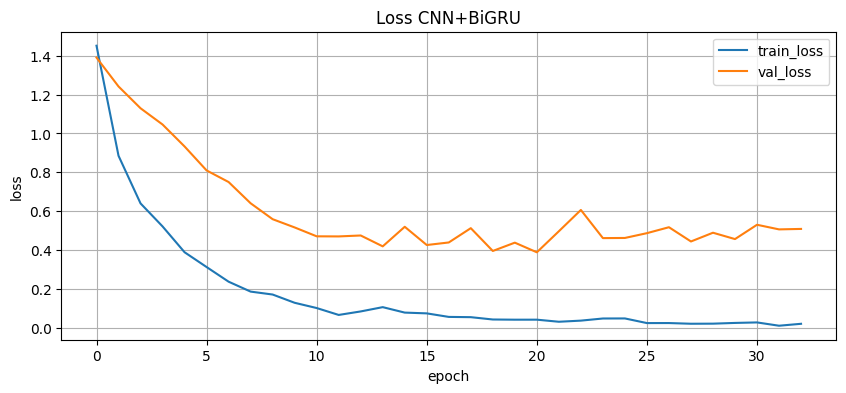

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 694ms/step
Accuracy: 0.9841
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        13
           2       0.93      1.00      0.96        13
           3       1.00      1.00      1.00        12
           4       1.00      0.92      0.96        13

    accuracy                           0.98        63
   macro avg       0.99      0.98      0.98        63
weighted avg       0.99      0.98      0.98        63



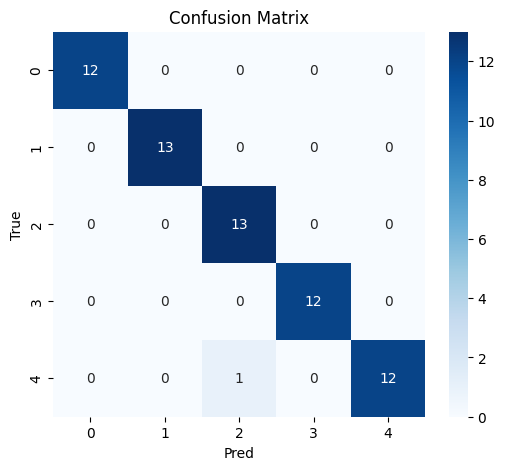

In [ ]:
X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t = dataset_gen_for_DL2(tr_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.25, split_r2=0.5)
Classif_CNN_BiGru(X_train_dl_t, y_train_dl_t, X_val_dl_t, y_val_dl_t, X_test_dl_t, y_test_dl_t, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

#### 2. Steady

(350, 300, 8)
(75, 300, 8)
(75, 300, 8)


Model: "sequential_41"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_93 (Conv1D)              │ (None, 300, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_93          │ (None, 300, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_88 (MaxPooling1D) │ (None, 150, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_94 (Conv1D)              │ (None, 150, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_94          │ (None, 150, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_89 (MaxPooling1D) │ (None, 75, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_17                │ (None, 128)            │        49,920 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_103 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_85 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_104 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_86 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,013 (277.39 KB)

 Trainable params: 70,821 (276.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 184ms/step - accuracy: 0.4086 - loss: 1.4752 - val_accuracy: 0.4000 - val_loss: 1.4470
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 120ms/step - accuracy: 0.6600 - loss: 0.9327 - val_accuracy: 0.4800 - val_loss: 1.3275
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 119ms/step - accuracy: 0.7371 - loss: 0.7215 - val_accuracy: 0.6133 - val_loss: 1.2041
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 121ms/step - accuracy: 0.7943 - loss: 0.5452 - val_accuracy: 0.6800 - val_loss: 1.0851
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 121ms/step - accuracy: 0.8457 - loss: 0.4465 - val_accuracy: 0.7867 - val_loss: 0.9720
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 153ms/step - accuracy: 0.9143 - loss: 0.3276 - val_accuracy: 0.8000 - val_loss: 0.8755
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 216ms/step - accuracy: 0.9229 - loss: 0.2689 - val_accuracy: 0.8000 - val_loss: 0.7851
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 150ms/step - accuracy: 0.9571 - loss: 0.2057 - val_acc

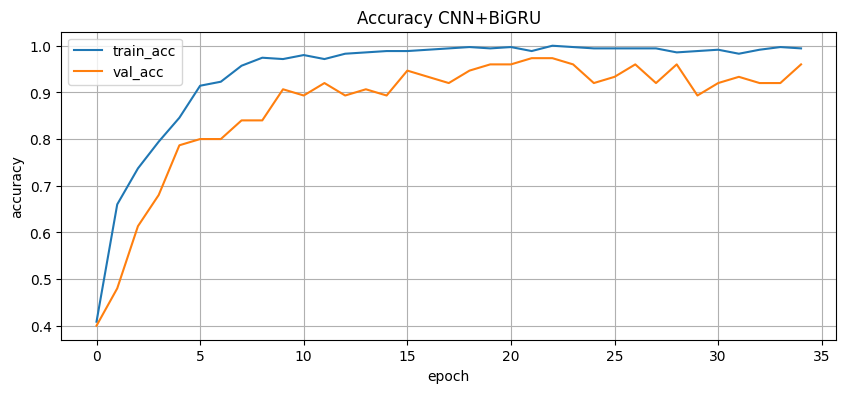

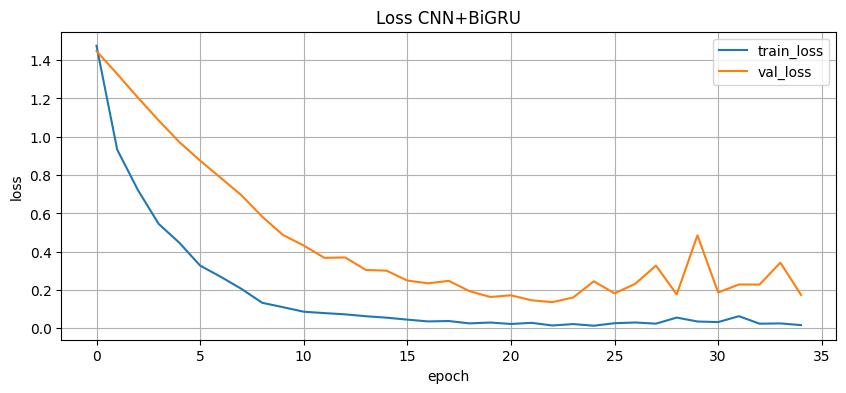

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 346ms/step
Accuracy: 0.9067
Classification report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        15
           1       1.00      0.87      0.93        15
           2       0.88      0.93      0.90        15
           3       0.88      1.00      0.94        15
           4       0.86      0.80      0.83        15

    accuracy                           0.91        75
   macro avg       0.91      0.91      0.91        75
weighted avg       0.91      0.91      0.91        75



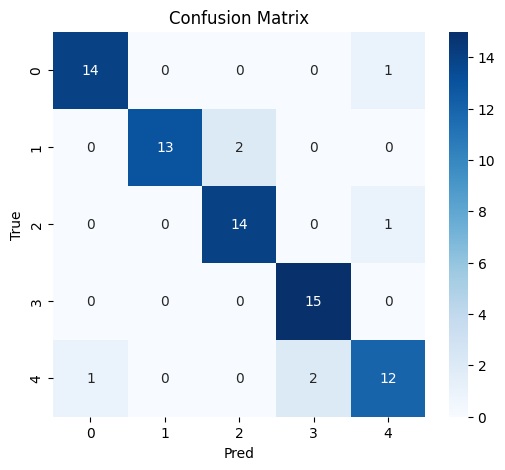

In [ ]:
X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st = dataset_gen_for_DL2(st_data_for_dl, 500, 5, time_steps=300, num_sensors=8, split_r1=0.3, split_r2=0.5)
Classif_CNN_BiGru(X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st, epochs=100, b_size=32, time_steps=300, num_sensors=8, num_classes=5)

(400, 300, 8)
(50, 300, 8)
(50, 300, 8)


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_18 (Conv1D)              │ (None, 300, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 300, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_18 (MaxPooling1D) │ (None, 150, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_19 (Conv1D)              │ (None, 150, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 150, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_19 (MaxPooling1D) │ (None, 75, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        49,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,013 (277.39 KB)

 Trainable params: 70,821 (276.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 14s 360ms/step - accuracy: 0.3950 - loss: 1.4465 - val_accuracy: 0.4800 - val_loss: 1.3548
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.6875 - loss: 0.8621 - val_accuracy: 0.6200 - val_loss: 1.1910
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step - accuracy: 0.7675 - loss: 0.6711 - val_accuracy: 0.7200 - val_loss: 1.0255
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 103ms/step - accuracy: 0.8325 - loss: 0.5147 - val_accuracy: 0.7400 - val_loss: 0.8896
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step - accuracy: 0.8875 - loss: 0.3855 - val_accuracy: 0.8000 - val_loss: 0.7527
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step - accuracy: 0.8975 - loss: 0.3197 - val_accuracy: 0.8800 - val_loss: 0.6262
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 220ms/step - accuracy: 0.9225 - loss: 0.2594 - val_accuracy: 0.8400 - val_loss: 0.6123
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 280ms/step - accuracy: 0.9425 - loss: 0.2087 - val_acc

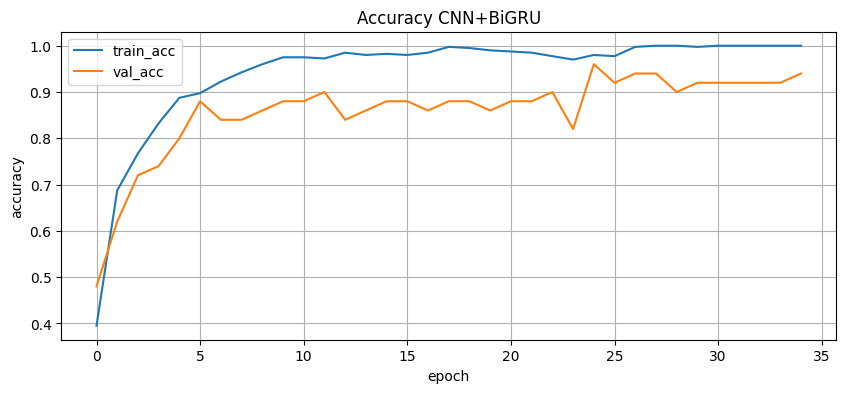

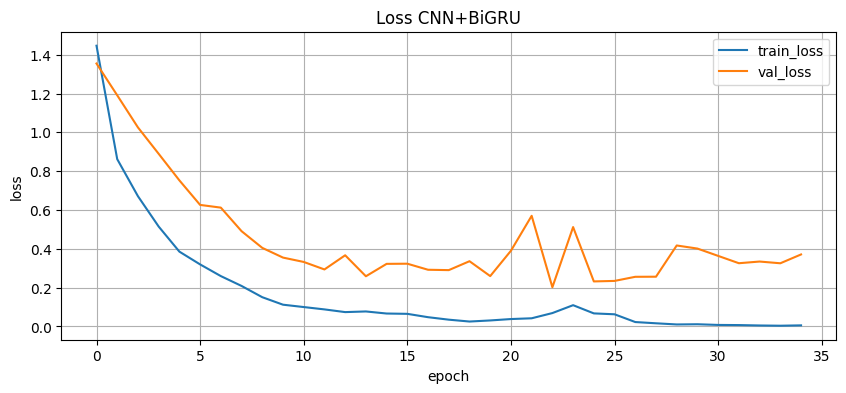

2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step
Accuracy: 0.9200
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00        10
           2       0.75      0.90      0.82        10
           3       0.90      0.90      0.90        10
           4       1.00      0.80      0.89        10

    accuracy                           0.92        50
   macro avg       0.93      0.92      0.92        50
weighted avg       0.93      0.92      0.92        50



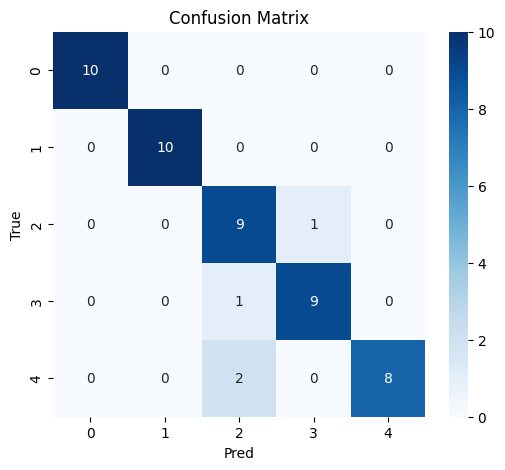

In [ ]:
X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st = dataset_gen_for_DL2(st_data_for_dl, 500, 5, time_steps=300, num_sensors=8, split_r1=0.2, split_r2=0.5)
Classif_CNN_BiGru(X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st, epochs=100, b_size=32, time_steps=300, num_sensors=8, num_classes=5)

(375, 300, 8)
(62, 300, 8)
(63, 300, 8)


Model: "sequential_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_46 (Conv1D)              │ (None, 300, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_46          │ (None, 300, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_46 (MaxPooling1D) │ (None, 150, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_47 (Conv1D)              │ (None, 150, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_47          │ (None, 150, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_47 (MaxPooling1D) │ (None, 75, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_7 (Bidirectional) │ (None, 128)            │        49,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_46 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_47 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,013 (277.39 KB)

 Trainable params: 70,821 (276.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 282ms/step - accuracy: 0.3760 - loss: 1.4472 - val_accuracy: 0.3871 - val_loss: 1.3824
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 127ms/step - accuracy: 0.6427 - loss: 0.9127 - val_accuracy: 0.4677 - val_loss: 1.2842
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - accuracy: 0.7120 - loss: 0.6908 - val_accuracy: 0.5323 - val_loss: 1.1684
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step - accuracy: 0.8187 - loss: 0.5202 - val_accuracy: 0.6774 - val_loss: 1.0225
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 105ms/step - accuracy: 0.8640 - loss: 0.3785 - val_accuracy: 0.7903 - val_loss: 0.9047
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - accuracy: 0.9120 - loss: 0.2843 - val_accuracy: 0.8387 - val_loss: 0.8124
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 105ms/step - accuracy: 0.9440 - loss: 0.2242 - val_accuracy: 0.8387 - val_loss: 0.7179
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step - accuracy: 0.9653 - loss: 0.1625 - val_acc

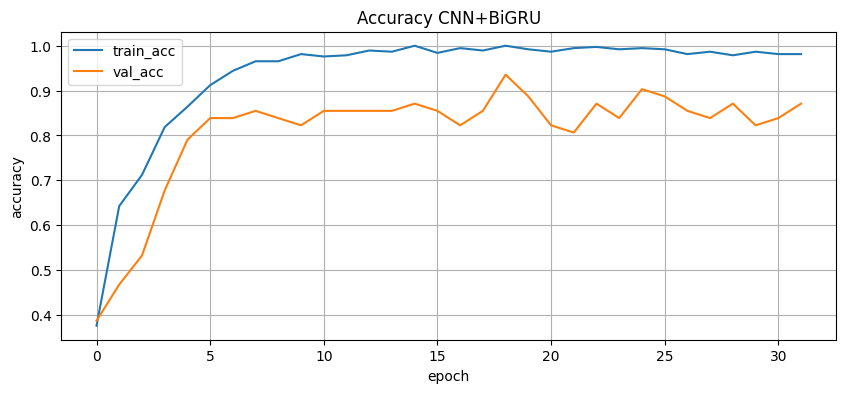

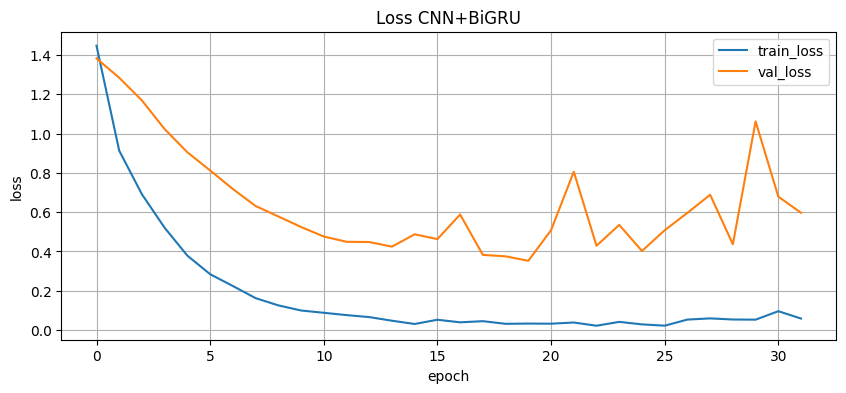

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 474ms/step
Accuracy: 0.9365
Classification report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96        12
           1       0.93      1.00      0.96        13
           2       0.86      0.92      0.89        13
           3       1.00      0.92      0.96        12
           4       1.00      0.85      0.92        13

    accuracy                           0.94        63
   macro avg       0.94      0.94      0.94        63
weighted avg       0.94      0.94      0.94        63



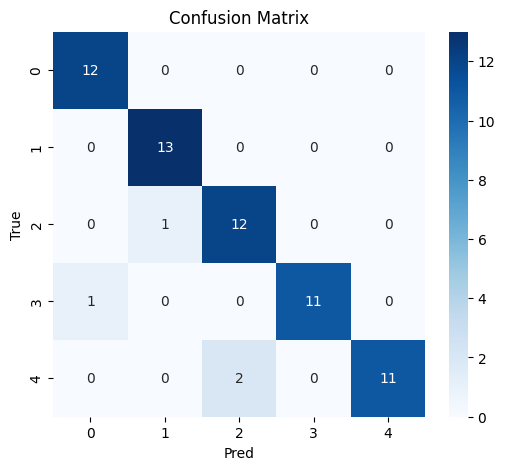

In [ ]:
X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st = dataset_gen_for_DL2(st_data_for_dl, 500, 5, time_steps=300, num_sensors=8, split_r1=0.25, split_r2=0.5)
Classif_CNN_BiGru(X_train_dl_st, y_train_dl_st, X_val_dl_st, y_val_dl_st, X_test_dl_st, y_test_dl_st, epochs=100, b_size=32, time_steps=300, num_sensors=8, num_classes=5)

#### 3. After Steady

(350, 200, 8)
(75, 200, 8)
(75, 200, 8)


Model: "sequential_42"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_95 (Conv1D)              │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_95          │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_90 (MaxPooling1D) │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_96 (Conv1D)              │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_96          │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_91 (MaxPooling1D) │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_18                │ (None, 128)            │        49,920 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_105 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_87 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_106 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_88 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,013 (277.39 KB)

 Trainable params: 70,821 (276.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 282ms/step - accuracy: 0.4143 - loss: 1.3978 - val_accuracy: 0.4267 - val_loss: 1.4540
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 224ms/step - accuracy: 0.7429 - loss: 0.8201 - val_accuracy: 0.5600 - val_loss: 1.3188
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 266ms/step - accuracy: 0.7829 - loss: 0.6257 - val_accuracy: 0.6533 - val_loss: 1.1782
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 156ms/step - accuracy: 0.8600 - loss: 0.4443 - val_accuracy: 0.7333 - val_loss: 1.0511
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 159ms/step - accuracy: 0.8943 - loss: 0.3527 - val_accuracy: 0.8133 - val_loss: 0.9223
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 162ms/step - accuracy: 0.9400 - loss: 0.2295 - val_accuracy: 0.8133 - val_loss: 0.8267
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 157ms/step - accuracy: 0.9686 - loss: 0.1812 - val_accuracy: 0.8267 - val_loss: 0.7125
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 160ms/step - accuracy: 0.9714 - loss: 0.1388 - val_acc

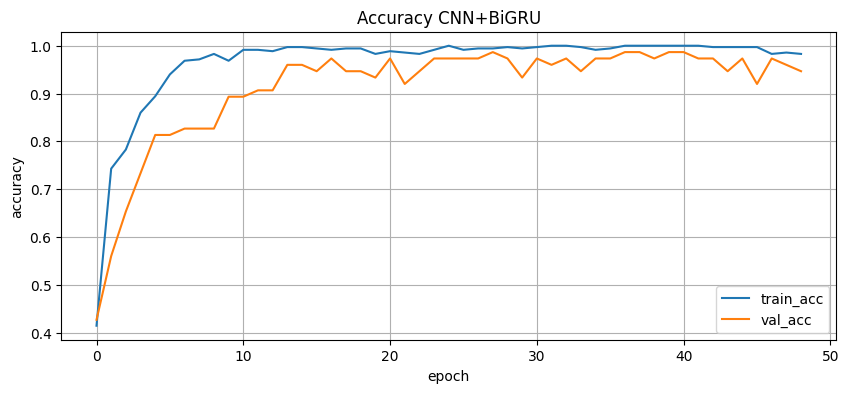

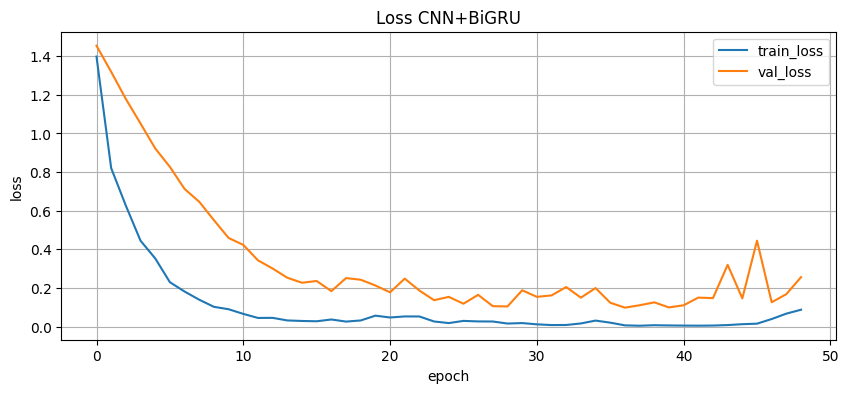

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 233ms/step
Accuracy: 0.8933
Classification report:
              precision    recall  f1-score   support

           0       0.88      0.93      0.90        15
           1       1.00      0.87      0.93        15
           2       1.00      0.87      0.93        15
           3       0.83      1.00      0.91        15
           4       0.80      0.80      0.80        15

    accuracy                           0.89        75
   macro avg       0.90      0.89      0.89        75
weighted avg       0.90      0.89      0.89        75



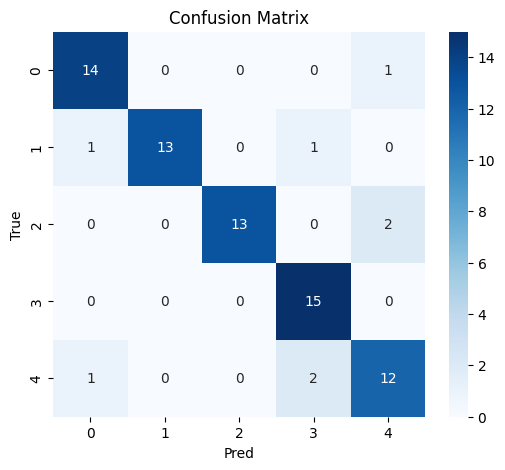

In [ ]:
X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs = dataset_gen_for_DL2(afs_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.3, split_r2=0.5)
Classif_CNN_BiGru(X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

(400, 200, 8)
(50, 200, 8)
(50, 200, 8)


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_20 (Conv1D)              │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_20 (MaxPooling1D) │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_21 (Conv1D)              │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_21 (MaxPooling1D) │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 128)            │        49,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,013 (277.39 KB)

 Trainable params: 70,821 (276.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 264ms/step - accuracy: 0.4000 - loss: 1.4173 - val_accuracy: 0.4800 - val_loss: 1.3867
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 153ms/step - accuracy: 0.6850 - loss: 0.8799 - val_accuracy: 0.5800 - val_loss: 1.2561
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - accuracy: 0.7525 - loss: 0.6521 - val_accuracy: 0.6400 - val_loss: 1.1667
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.7975 - loss: 0.5195 - val_accuracy: 0.7000 - val_loss: 1.0711
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.8600 - loss: 0.4105 - val_accuracy: 0.7400 - val_loss: 0.9710
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 0.9075 - loss: 0.3049 - val_accuracy: 0.7800 - val_loss: 0.8855
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.9175 - loss: 0.2550 - val_accuracy: 0.7800 - val_loss: 0.8117
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.9325 - loss: 0.1994 - val_accuracy:

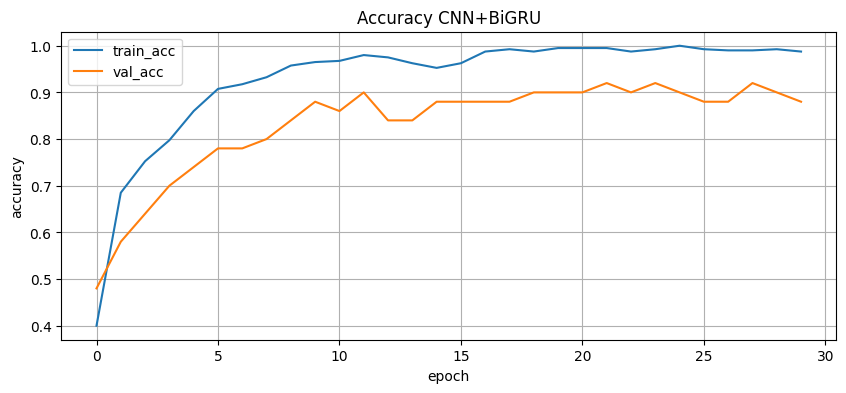

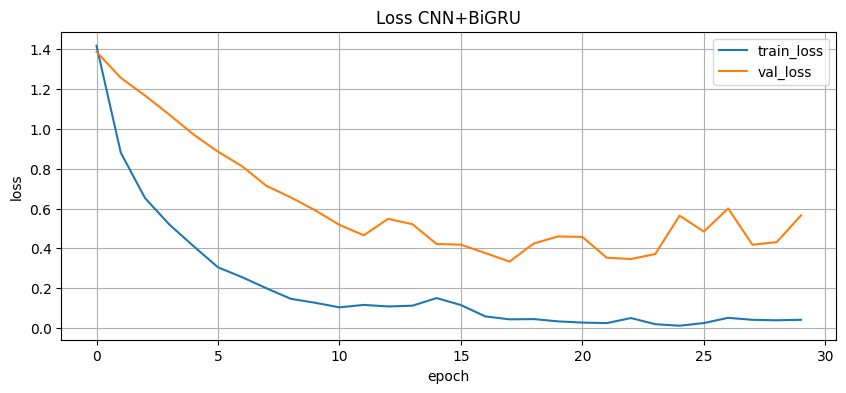

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 828ms/step
Accuracy: 0.9400
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.91      1.00      0.95        10
           2       0.82      0.90      0.86        10
           3       1.00      0.90      0.95        10
           4       1.00      0.90      0.95        10

    accuracy                           0.94        50
   macro avg       0.95      0.94      0.94        50
weighted avg       0.95      0.94      0.94        50



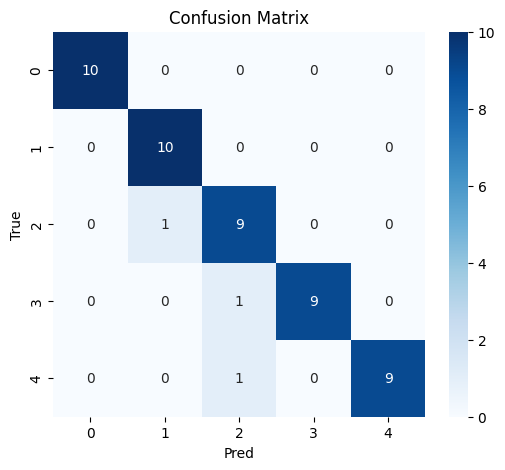

In [ ]:
X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs = dataset_gen_for_DL2(afs_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.2, split_r2=0.5)
Classif_CNN_BiGru(X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

(375, 200, 8)
(62, 200, 8)
(63, 200, 8)


Model: "sequential_22"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_44 (Conv1D)              │ (None, 200, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_44          │ (None, 200, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_44 (MaxPooling1D) │ (None, 100, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_45 (Conv1D)              │ (None, 100, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_45          │ (None, 100, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_45 (MaxPooling1D) │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_6 (Bidirectional) │ (None, 128)            │        49,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_44 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_45 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,013 (277.39 KB)

 Trainable params: 70,821 (276.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 132ms/step - accuracy: 0.3947 - loss: 1.4814 - val_accuracy: 0.5323 - val_loss: 1.4229
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step - accuracy: 0.6560 - loss: 0.9502 - val_accuracy: 0.5161 - val_loss: 1.2933
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 136ms/step - accuracy: 0.7813 - loss: 0.6797 - val_accuracy: 0.5968 - val_loss: 1.1827
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 141ms/step - accuracy: 0.8560 - loss: 0.4895 - val_accuracy: 0.7581 - val_loss: 1.0629
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 128ms/step - accuracy: 0.8987 - loss: 0.3523 - val_accuracy: 0.8226 - val_loss: 0.9329
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step - accuracy: 0.9280 - loss: 0.2644 - val_accuracy: 0.9032 - val_loss: 0.8067
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step - accuracy: 0.9413 - loss: 0.2078 - val_accuracy: 0.9032 - val_loss: 0.6985
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - accuracy: 0.9653 - loss: 0.1425 - val_accuracy

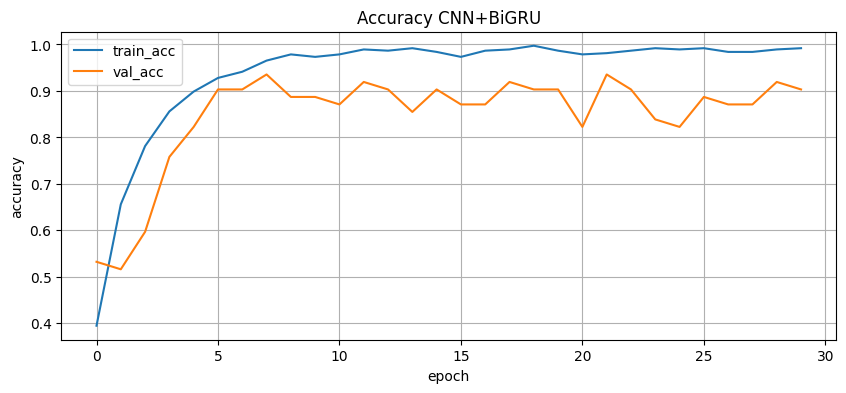

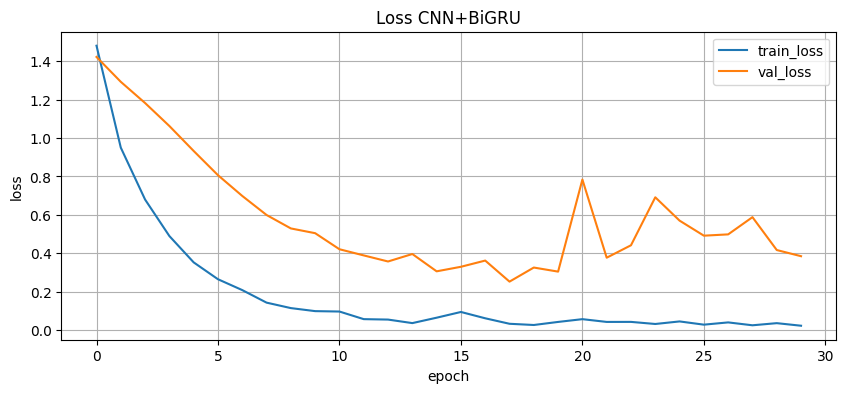

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 461ms/step
Accuracy: 0.9524
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.96        13
           2       1.00      0.92      0.96        13
           3       1.00      0.83      0.91        12
           4       0.87      1.00      0.93        13

    accuracy                           0.95        63
   macro avg       0.96      0.95      0.95        63
weighted avg       0.96      0.95      0.95        63



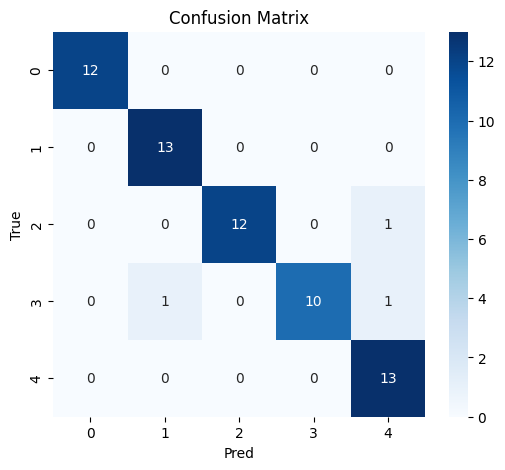

In [ ]:
X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs = dataset_gen_for_DL2(afs_data_for_dl, 500, 5, time_steps=200, num_sensors=8, split_r1=0.25, split_r2=0.5)
Classif_CNN_BiGru(X_train_dl_afs, y_train_dl_afs, X_val_dl_afs, y_val_dl_afs, X_test_dl_afs, y_test_dl_afs, epochs=100, b_size=32, time_steps=200, num_sensors=8, num_classes=5)

#### 4. Combined

(350, 700, 8)
(75, 700, 8)
(75, 700, 8)


Model: "sequential_24"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_48 (Conv1D)              │ (None, 700, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_48          │ (None, 700, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_48 (MaxPooling1D) │ (None, 350, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_49 (Conv1D)              │ (None, 350, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_49          │ (None, 350, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_49 (MaxPooling1D) │ (None, 175, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_8 (Bidirectional) │ (None, 128)            │        49,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_48 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_49 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,013 (277.39 KB)

 Trainable params: 70,821 (276.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 380ms/step - accuracy: 0.3429 - loss: 1.5347 - val_accuracy: 0.5067 - val_loss: 1.4522
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 237ms/step - accuracy: 0.6400 - loss: 1.0200 - val_accuracy: 0.5600 - val_loss: 1.3217
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 241ms/step - accuracy: 0.7429 - loss: 0.7448 - val_accuracy: 0.5867 - val_loss: 1.2069
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 416ms/step - accuracy: 0.7971 - loss: 0.6024 - val_accuracy: 0.6400 - val_loss: 1.1136
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 237ms/step - accuracy: 0.8629 - loss: 0.4579 - val_accuracy: 0.7067 - val_loss: 1.0144
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 242ms/step - accuracy: 0.8714 - loss: 0.3886 - val_accuracy: 0.8267 - val_loss: 0.9085
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 430ms/step - accuracy: 0.9257 - loss: 0.2863 - val_accuracy: 0.9067 - val_loss: 0.8049
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 240ms/step - accuracy: 0.9286 - loss: 0.2566 - val_acc

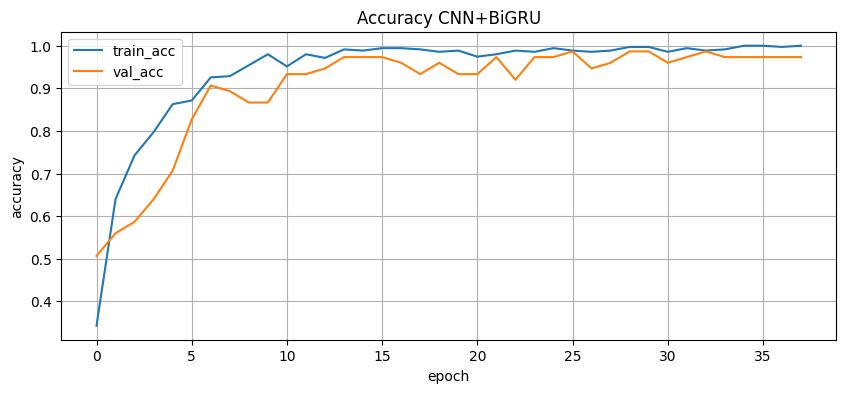

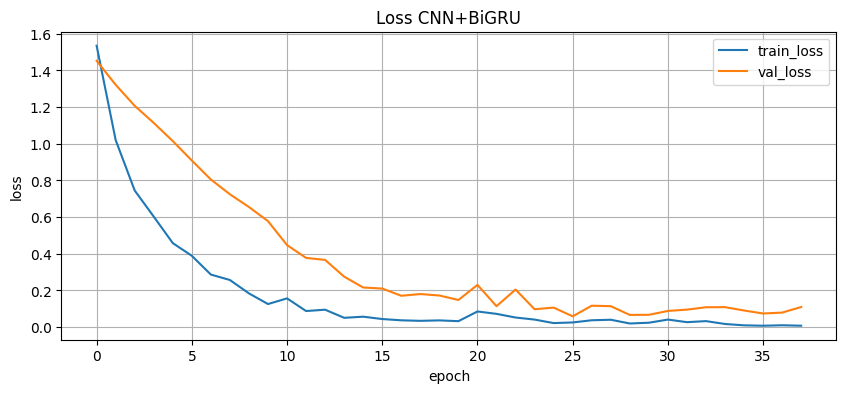

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 408ms/step
Accuracy: 0.9067
Classification report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        15
           1       1.00      0.87      0.93        15
           2       1.00      0.93      0.97        15
           3       0.82      0.93      0.88        15
           4       0.81      0.87      0.84        15

    accuracy                           0.91        75
   macro avg       0.91      0.91      0.91        75
weighted avg       0.91      0.91      0.91        75



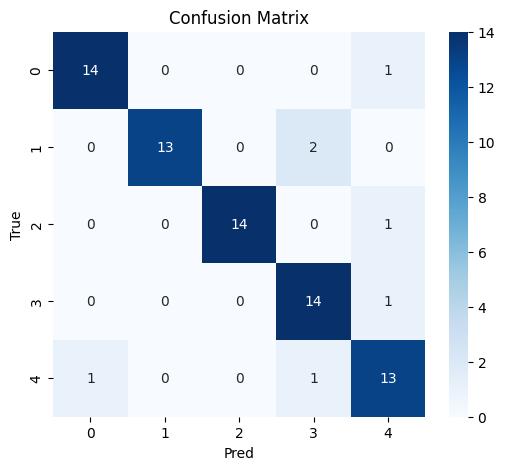

In [ ]:
X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb = dataset_gen_for_DL2(cmb_data_for_dl, 500, 5, time_steps=700, num_sensors=8, split_r1=0.3, split_r2=0.5)
Classif_CNN_BiGru(X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb, epochs=100, b_size=32, time_steps=700, num_sensors=8, num_classes=5)

(400, 700, 8)
(50, 700, 8)
(50, 700, 8)


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_22 (Conv1D)              │ (None, 700, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 700, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_22 (MaxPooling1D) │ (None, 350, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_23 (Conv1D)              │ (None, 350, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_23          │ (None, 350, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_23 (MaxPooling1D) │ (None, 175, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 128)            │        49,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,013 (277.39 KB)

 Trainable params: 70,821 (276.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 19s 451ms/step - accuracy: 0.3375 - loss: 1.5467 - val_accuracy: 0.5600 - val_loss: 1.4180
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 365ms/step - accuracy: 0.6375 - loss: 0.9566 - val_accuracy: 0.6200 - val_loss: 1.3084
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 279ms/step - accuracy: 0.7175 - loss: 0.7649 - val_accuracy: 0.6600 - val_loss: 1.1820
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 411ms/step - accuracy: 0.8225 - loss: 0.5637 - val_accuracy: 0.7200 - val_loss: 1.0944
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 444ms/step - accuracy: 0.8400 - loss: 0.4790 - val_accuracy: 0.7800 - val_loss: 0.9980
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 226ms/step - accuracy: 0.8900 - loss: 0.3846 - val_accuracy: 0.7800 - val_loss: 0.9153
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 227ms/step - accuracy: 0.9075 - loss: 0.3042 - val_accuracy: 0.8400 - val_loss: 0.8258
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 257ms/step - accuracy: 0.9350 - loss: 0.2293 - val_acc

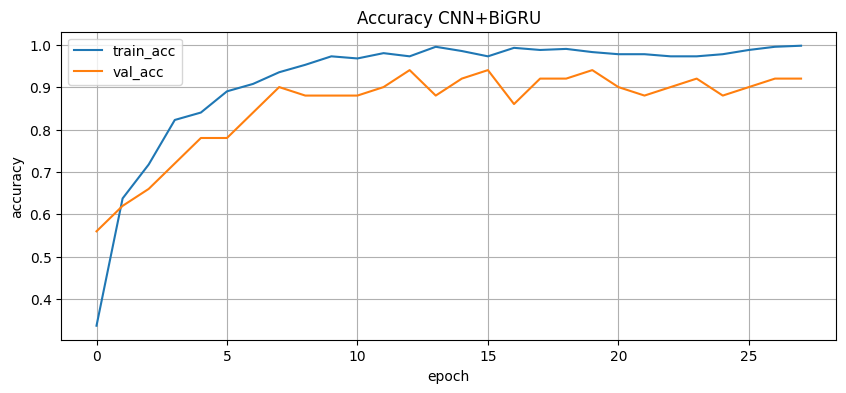

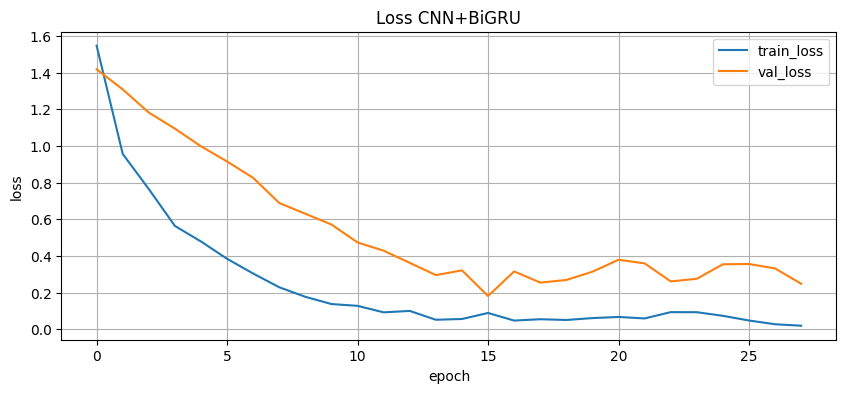

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 478ms/step
Accuracy: 0.9800
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00        10
           2       0.91      1.00      0.95        10
           3       1.00      1.00      1.00        10
           4       1.00      0.90      0.95        10

    accuracy                           0.98        50
   macro avg       0.98      0.98      0.98        50
weighted avg       0.98      0.98      0.98        50



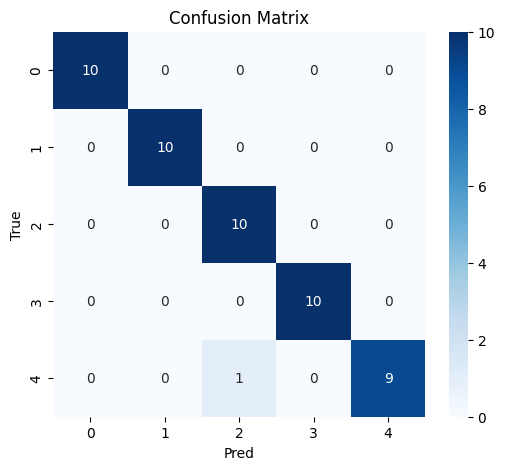

In [ ]:
X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb = dataset_gen_for_DL2(cmb_data_for_dl, 500, 5, time_steps=700, num_sensors=8, split_r1=0.2, split_r2=0.5)
Classif_CNN_BiGru(X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb, epochs=100, b_size=32, time_steps=700, num_sensors=8, num_classes=5)

(375, 700, 8)
(62, 700, 8)
(63, 700, 8)


Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_42 (Conv1D)              │ (None, 700, 32)        │         1,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_42          │ (None, 700, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_42 (MaxPooling1D) │ (None, 350, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_43 (Conv1D)              │ (None, 350, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_43          │ (None, 350, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_43 (MaxPooling1D) │ (None, 175, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 128)            │        49,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_42 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_43 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,013 (277.39 KB)

 Trainable params: 70,821 (276.64 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 10s 290ms/step - accuracy: 0.3387 - loss: 1.5578 - val_accuracy: 0.4839 - val_loss: 1.4307
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 344ms/step - accuracy: 0.6187 - loss: 1.0070 - val_accuracy: 0.5645 - val_loss: 1.2787
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 227ms/step - accuracy: 0.7493 - loss: 0.7341 - val_accuracy: 0.6452 - val_loss: 1.1223
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 226ms/step - accuracy: 0.7840 - loss: 0.5984 - val_accuracy: 0.6935 - val_loss: 0.9884
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 262ms/step - accuracy: 0.8133 - loss: 0.4916 - val_accuracy: 0.7419 - val_loss: 0.8569
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 387ms/step - accuracy: 0.8987 - loss: 0.3503 - val_accuracy: 0.8065 - val_loss: 0.7503
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 229ms/step - accuracy: 0.9307 - loss: 0.2779 - val_accuracy: 0.7742 - val_loss: 0.6324
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 224ms/step - accuracy: 0.9493 - loss: 0.2209 - val_acc

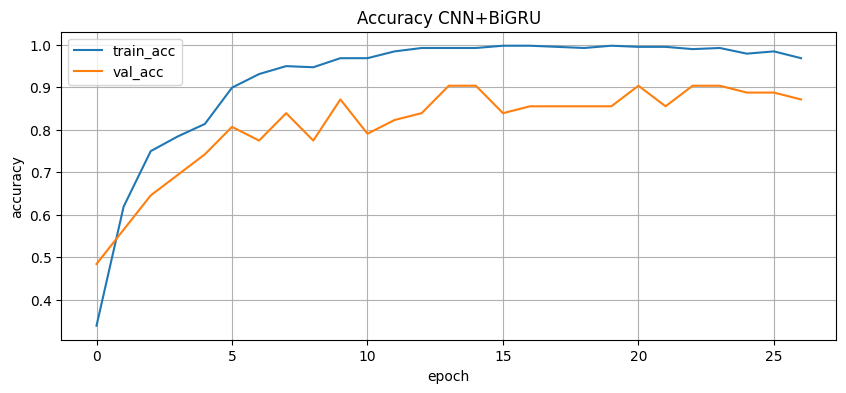

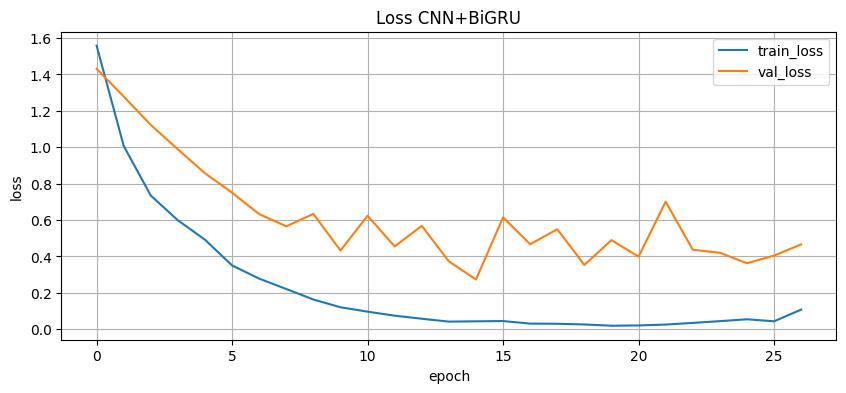

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 529ms/step
Accuracy: 0.9365
Classification report:
              precision    recall  f1-score   support

           0       1.00      0.83      0.91        12
           1       0.93      1.00      0.96        13
           2       0.92      0.92      0.92        13
           3       0.92      0.92      0.92        12
           4       0.93      1.00      0.96        13

    accuracy                           0.94        63
   macro avg       0.94      0.93      0.93        63
weighted avg       0.94      0.94      0.94        63



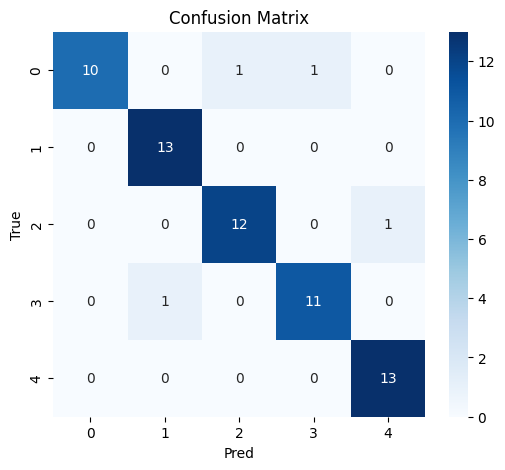

In [ ]:
X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb = dataset_gen_for_DL2(cmb_data_for_dl, 500, 5, time_steps=700, num_sensors=8, split_r1=0.25, split_r2=0.5)
Classif_CNN_BiGru(X_train_dl_cmb, y_train_dl_cmb, X_val_dl_cmb, y_val_dl_cmb, X_test_dl_cmb, y_test_dl_cmb, epochs=100, b_size=32, time_steps=700, num_sensors=8, num_classes=5)